# 2-motor: motor-model

Build one circuit model of the motor that reproduces the current inside each PWM period, test it on data it was not fitted to, and use it to say how far the board's once-per-period current sample sits from the motor's mean current.

## Purpose

The board reads the motor current once per PWM period, near the middle of the window. A current loop, a stall detector, a torque estimate and the back-EMF a speed estimate reads as $V - R i$ all take that sample as the motor's current, so they need to know how far it sits from the mean over the period. On a plain resistance and inductance in series, the model from a first course in circuits, the window's current is a ramp and its middle sits close to the mean. On this motor spinning, bemf-coast found the sample 20 to 30 mA over what a meter in series reads.

Stage 2 left two more things the plain R-L does not explain. Inductance found that the motor's inductance reads about 0.6 mH inside one window and about 0.8 mH over half a millisecond. And on the locked motor in fast decay, the current at the bridge's ON edge reads 18 to 23 mA, where an R-L starts from zero.

All three point at the metal around the coil. The coils are wound on an iron rotor inside a steel can with magnets, and that metal adds three parts a textbook inductor does not have.

- A changing flux drives eddy currents in the metal, and the coil supplies them, as a transformer's primary supplies its secondary. The voltage across the coil is the rate of change of its flux, so this loss current follows the volts across the coil. In a transformer's equivalent circuit it is the core-loss resistor across the magnetizing inductance, and here it is written as a conductance $G$ across the inductance. The teardown finds a little of it on one bare coil and about twice that once the coil is back in the can, so the rotor's iron, the can and the magnets all carry some. It flows the instant the bridge applies a voltage, which an inductor's current does not, so the current at the ON edge starts above zero. On the spinning motor the coil sees about $(1 - D)\,V$ during the window and the reverse during the brake, so this current averages to zero over a period and a meter never sees it. The board samples only inside the window, so it reads the positive half every time.
- Some eddy paths are thick enough that the field takes tens of microseconds to soak into them, the way heat soaks into a pan. Until it does, their eddy currents hold the flux out. The textbook circuit for that soaking is a ladder of inductances and resistances, each step deeper and slower than the last [3], and these data resolve its first step, one rung, an inductance and a resistance in parallel after the main inductance. Over one window the rung acts as extra resistance and over many periods as extra inductance, which is the 0.6 against 0.8 mH. It shows in full only on the assembled motor, and the can and the magnets are the candidate this notebook leaves for it.
- The inductance itself rises a little with the current. That is the iron's hysteresis, which follows how much flux there is and not how fast it changes.

Speed-torque's run-ups at 100 %, where nothing switches, left one more pair. They settled about 20 mA over no-load-current's drag curve, and their volts sit over what $R i + K_e \omega$ predicts. Two later sections take those up, the current as drag the rotor really has and the volts as a voltage set by the speed and not by the current, the brush drop $V_b(\omega)$.

So the quantity this notebook ends with is the crest sample less the period mean on the free motor, by duty and rail, with no meter in the loop and with one, with a band from the models that fit. The model is fitted where the rotor is locked, since the current is read best there. It is then tested on another rail, another duty, the other decay mode, inductance's own estimators and, last, the spinning motor. Each part of the network stays only if the data it was not fitted to need it.

## Procedure

This notebook has no capture of its own. It reads the bursts the teardown and inductance recorded, the spins and coasts of bemf-coast and speed-torque, and bridge-states' control bursts from stage 1, and it simulates them. No new bench work exists or is planned for it, so what these data do not separate is listed as open, with what each candidate predicts.

## Data

- `telemetry/mg90-b__dev-v006-2A-D/teardown/coil-levels-ra-1/`, `coil-levels-bare-1/` and `coil-levels-can-1/`, each with `3v7/`, `5v0/` and `7v4/`. The levels runs, one sitting at three rails. Each rail holds inductance's fast groups, fast decay at 25 and 40 % both ways and slow decay forward at both duties, five bursts each. `ra` is bridge-states' resistor and inductor A, the control, `bare` one coil of the bare rotor with the disc off, and `can` the same coil back in the can with its magnets.
- `teardown/coil-noring-1/` and `coil-can-1/`, the same groups at 5 V in an earlier sitting, one coil of the bare rotor and the same leads back in the can.
- `inductance/fast-1/hole-11/`, the motor locked at hole 11, the four fast groups and the two slow groups after them.
- `inductance/capture-1/hole-11/` and `inductance/reversal-1/hole-11/`, the same seat in slow decay, capture-1's five groups and reversal-1's six.
- `dev-v006-2A-D/bridge-states/capture-1/ra/bursts-fast/` and `rab/bursts-fast/`, bridge-states' fast-decay bursts on inductor A and on A and B in series, each with its resistor.
- `bemf-coast/capture-1/`, `meter-1/` and `high-1/`, the spins and coasts of the free motor, the meter in series in `meter-1` and `high-1`, and bemf-coast's result for `spinning-1`'s bursts with the meter in the loop.
- `bemf-coast/spinning-1/`, the bursts on the spinning motor with the meter in the loop, each tap sampled through about 20 whole periods, read for the motor's period-mean voltage.
- `speed-torque/capture-1/`, the 100 % run-ups and their coasts, and its turn windows through speed-torque's own estimator cells, run unchanged.
- `telemetry/mg90-b/teardown/photos/07-brushes-and-commutator-end.jpg`, the teardown's photo of the brushes.
- `telemetry/mg90-b/teardown/hand.csv`, the coil runs' leads read at their free ends, and one coil read alone.

Every burst but the first of its group enters a fit, since inductance found that the first burst after a reversal reads apart from the others.

### The results carried in

From stage 1, current-scale's counts per amp and its in-drive offset, terminal-chain's terminal line, sample-timing's slow-decay edges, settle and window scale and the instant the crest shunt sample closes, and bridge-states' fast-decay edges, the amplifier's lag and gain, the low-side loop and the controls' DC resistance. From stage 2, rest-resistance's stall resistance by hole and its median, bemf-coast's $K_e$ (the back-EMF constant) and its per-cycle rows, speed-torque's inertia $J$ and its run-up line, rest-resistance's run-up R and the meter's ohms at rest, and teardown's lead zero, which comes off every hand reading of the coil runs' leads. Inductance's period-fit $L$ enters only the brush drop's two size checks. Otherwise no resistance, inductance or offset that inductance or the teardown derived is an input anywhere. They appear only where this notebook's numbers are set beside them.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from scipy import stats

from oscnb import results
import motor_model as mm                                               # this notebook's simulator, folds and fits, beside it

BLUE, ORANGE, INK, MUTED, GREEN = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#1baf7a"   # the house colors
pd.set_option("display.width", 200)
print(mm.MOTOR.key, "on", mm.BOARD.key)
print("levels runs:", ", ".join(str(results.rel(p)) for p in mm.SETS.values()))
print("5 V runs:", ", ".join(str(results.rel(p)) for p in mm.OLD.values()))
print("hole 11 in slow decay:", results.rel(mm.IND / "capture-1" / "hole-11"), "and", results.rel(mm.IND / "reversal-1" / "hole-11"))
print("controls:", results.rel(mm.BS), "| spinning:", results.rel(mm.BC), "and", results.rel(mm.STQ))
# every constant from its results file, none typed in
print(f"current {mm.CPA:.2f} counts per A, in-drive offset {mm.CS['drive_offset_counts']['value']:+.1f} counts (current-scale)")
print(f"terminals {mm.K_CPV:.2f} counts per V, offset {mm.C_OFF:+.1f} counts (terminal-chain)")
print(f"slow decay's bridge edges {mm.SLOW_ON:.1f} and {mm.SLOW_OFF:.1f} ticks after the commanded start and end, "
      f"the crest shunt sample {mm.CREST_AT} ticks after the crest (sample-timing)")
print(f"fast decay's edges {mm.FAST_ON:.0f} and {mm.FAST_OFF:.0f} ticks, the amplifier's lag {mm.AMP_TAU:.2f} ticks and gain {mm.AMP_GAIN:.4f}, "
      f"the low-side loop {mm.BSR['low_side_loop_ohm']['value']:.3f} ohm (bridge-states)")
print(f"the motor's stall R at hole 11 {mm.motor_r(11):.3f} ohm, the median over the holes {mm.RR['r_term_median_ohm']['value']:.3f} ohm (rest-resistance)")
print(f"Ke {mm.KE * 1e3:.4f} mV s/rad (bemf-coast), J {mm.J * 1e9:.3f} x 1e-9 kg m^2 (speed-torque), lead zero {mm.LEAD_ZERO:.2f} ohm (teardown)")
print("each coil run's series R, the hand ohms less the lead zero:", ", ".join(f"{s} {mm.hand_r(s):.3f}" for s in ("ra", "bare", "can", "coil-noring-1")), "ohm")

mg90-b on dev-v006-2A-D
levels runs: telemetry/mg90-b__dev-v006-2A-D/teardown/coil-levels-ra-1, telemetry/mg90-b__dev-v006-2A-D/teardown/coil-levels-bare-1, telemetry/mg90-b__dev-v006-2A-D/teardown/coil-levels-can-1
5 V runs: telemetry/mg90-b__dev-v006-2A-D/inductance/fast-1/hole-11, telemetry/mg90-b__dev-v006-2A-D/teardown/coil-can-1, telemetry/mg90-b__dev-v006-2A-D/teardown/coil-noring-1
hole 11 in slow decay: telemetry/mg90-b__dev-v006-2A-D/inductance/capture-1/hole-11 and telemetry/mg90-b__dev-v006-2A-D/inductance/reversal-1/hole-11
controls: telemetry/dev-v006-2A-D/bridge-states/capture-1 | spinning: telemetry/mg90-b__dev-v006-2A-D/bemf-coast and telemetry/mg90-b__dev-v006-2A-D/speed-torque/capture-1
current 1135.01 counts per A, in-drive offset +5.3 counts (current-scale)
terminals 248.37 counts per V, offset +2.4 counts (terminal-chain)
slow decay's bridge edges 39.5 and 14.0 ticks after the commanded start and end, the crest shunt sample 31 ticks after the crest (sample-timing)

Every fold in one line each. The figure shows what one fold of the motor holds, the shunt over its zero against the tick in the period, every full window of every burst in the fold pooled, fast decay on the left and slow decay on the right. The thing to see is the shape a model has to draw. In fast decay the window rises from close to zero with a step at its start, the return runs the wrong way after it, and the shunt sits at zero until the next window. In slow decay the window starts high, since the current keeps running through the brake between windows, and the shunt reads nothing between windows.

ra             18 folds,  72 bursts, rails 3v7, 5v0, 7v4, decays fast, slow, V_on 3.68 to 7.37 V, rest sd 0.83 to 1.21 mA
bs-ra           4 folds,  16 bursts, rails 5v0, decays fast, V_on 4.96 to 4.97 V, rest sd 0.88 to 0.91 mA
bs-rab          4 folds,  16 bursts, rails 5v0, decays fast, V_on 4.96 to 4.97 V, rest sd 0.85 to 0.93 mA
bare           18 folds,  72 bursts, rails 3v7, 5v0, 7v4, decays fast, slow, V_on 3.68 to 7.39 V, rest sd 0.87 to 1.22 mA
can            18 folds,  72 bursts, rails 3v7, 5v0, 7v4, decays fast, slow, V_on 3.67 to 7.40 V, rest sd 0.86 to 1.24 mA
coil-noring-1   6 folds,  24 bursts, rails 5v0, decays fast, slow, V_on 4.96 to 5.00 V, rest sd 0.87 to 0.92 mA
coil-can-1      6 folds,  24 bursts, rails 5v0, decays fast, slow, V_on 4.96 to 5.00 V, rest sd 0.84 to 0.95 mA
motor           6 folds,  24 bursts, rails 5v0, decays fast, slow, V_on 4.94 to 4.98 V, rest sd 0.85 to 0.89 mA
cap-11          4 folds,  18 bursts, rails 5v0, decays slow, V_on 4.97 to 4.98 V, rest

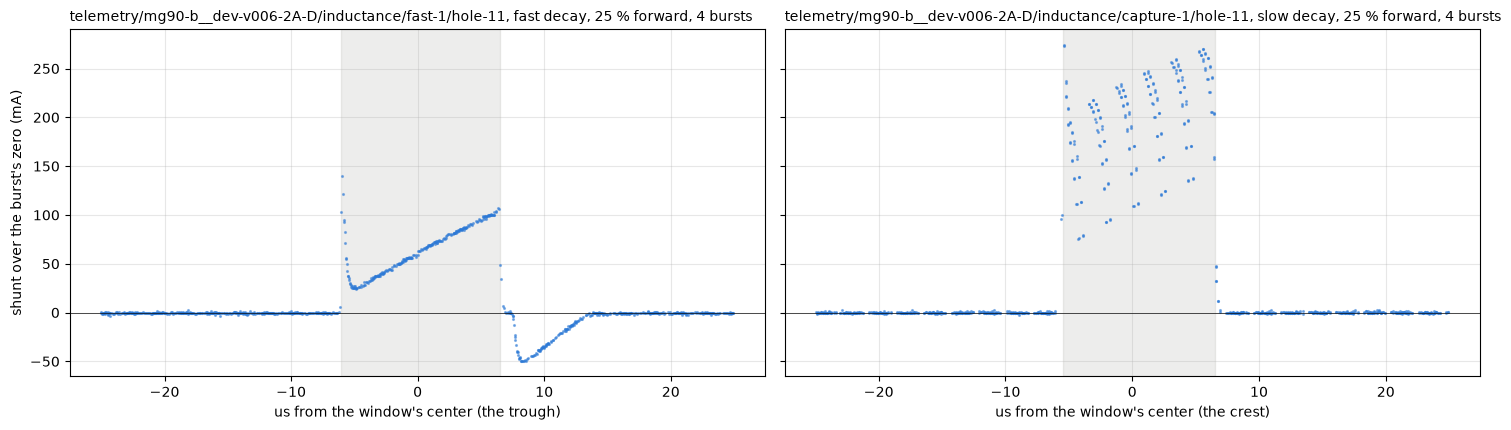

In [2]:
NAMES = ("ra", "bs-ra", "bs-rab", "bare", "can", "coil-noring-1", "coil-can-1", "motor", "cap-11", "rev-11")
FT = pd.DataFrame([dict(set=s, level=f["level"], decay=f["decay"], pct=f["pct"], sign=f["sign"], bursts=f["nb"], samples=len(f["t"]),
                        v_on=f["v_on"], r_on=f["r_on"], rest_sd_ma=f["sd"]) for s in NAMES for f in mm.cached_folds(s)])
for s, g in FT.groupby("set", sort=False):
    print(f"{s:14s} {len(g):2d} folds, {g['bursts'].sum():3d} bursts, rails {', '.join(sorted(g['level'].unique()))}, "
          f"decays {', '.join(sorted(g['decay'].unique()))}, V_on {g['v_on'].min():.2f} to {g['v_on'].max():.2f} V, "
          f"rest sd {g['rest_sd_ma'].min():.2f} to {g['rest_sd_ma'].max():.2f} mA")

# one fast-decay fold and one slow-decay fold of the motor at hole 11, every sample against its tick in the period
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True)
for a, (s, decay) in zip(ax, (("motor", "fast"), ("cap-11", "slow"))):
    f = mm.pick(mm.cached_folds(s), decay, pcts=(25,), signs=(1,))[0]
    keep = f["t"] >= (mm.P - mm.ARR if decay == "fast" else mm.ARR)   # every full window after the first
    a.plot(f["x"][keep] / mm.TPU, f["i"][keep], ".", ms=2.5, color=BLUE, alpha=0.5)
    a.axvspan(f["on"] / mm.TPU, f["off"] / mm.TPU, color=MUTED, alpha=0.15)
    a.axhline(0, color=INK, lw=0.5); a.grid(alpha=0.3)
    a.set_xlabel(f"us from the window's center ({'the trough' if decay == 'fast' else 'the crest'})")
    a.set_title(f"{results.rel(mm.OLD['motor'] if s == 'motor' else mm.IND / 'capture-1' / 'hole-11')}, {decay} decay, 25 % forward, "
                f"{f['nb']} bursts", loc="left", fontsize=10)
ax[0].set_ylabel("shunt over the burst's zero (mA)")
plt.tight_layout(); plt.show()

## Method

### The folds

A fold is one set, rail, decay, duty and sign, every burst but the first of its group pooled. Each raw shunt sample is placed in the period by the PWM counter at the burst's first sample and the fixed sample spacing, at the tick its aperture closed, over the burst's own pre-step zero, and converted through current-scale's counts per amp. The bridge's source terms come off the taps. Inside the window the terminal difference against the current gives the window's volts $V_\mathrm{on}$ and the bridge's own resistance $r_\mathrm{on}$ as a line, and in fast decay the return's volts and resistance come the same way from the reverse folds. In slow decay the brake is the low-side loop of bridge-states.

### The simulator

The model is one series branch through the bridge, simulated tick by tick at 48 MHz with four Runge-Kutta steps a tick. A series resistance $R_s$ feeds a magnetizing inductance $L(i)$ with a conductance $G$ across it, and in some models a rung after it, an inductance $L_b$ in parallel with a resistance $R_b$. A rung is the first step of an eddy ladder, the Cauer ladder network that stands for eddy currents in a conductor as inductances and resistances in turn [3]. At high frequency it looks like $R_b$ in series, and at low frequency like $L_b$ added to the inductance. $G$ is the simplest model of a loss across the inductance, a loss current in proportion to the volts across it, which is what eddy currents in a core would draw, the classical eddy term of the loss separation of soft iron [2]. Here it is a measured loss of that shape, not a measured eddy current. The magnetizing branch's incremental inductance is

$$L_\mathrm{inc} = L_0\,\left(1 + a_1 s\,i + a_2 i^2 + c_r\,|i - i_\mathrm{rev}|\right)\left(1 - k_c\,e^{-|i - i_\mathrm{rev}|/i_c}\right)$$

with $i$ the current's size in the drive's sign $s$. $a_1$ and $a_2$ are a shape the magnets bias by sign, the anhysteretic part. $c_r$ is the Rayleigh coefficient, the incremental inductance rising in proportion to the current change since the last reversal of the current's direction $i_\mathrm{rev}$, the law of soft iron at low fields [1]. The last factor is an onset step, an iron that takes little flux for the first $i_c$ or so after a reversal, of which only $k_c i_c$ is identified, so $k_c$ is held at 0.9. Two memory rules count $i_\mathrm{rev}$. Rule 1 keeps Rayleigh memory, a branch that passes an older turning point wipes the minor loop out and continues on the older branch. Rule 2 counts from the last reversal only and never returns to an older branch. In fast decay the current returns to zero every period and the two rules read the same branch, to within a few hundredths of a milliamp.

The bridge runs one of four modes each tick. ON drives the window's volts through $r_\mathrm{on}$. RET is fast decay's return through the opposite pair until the current reaches zero, then FLOAT with no terminal current. BRAKE is slow decay's short through the low side. The shunt reads the current in ON, its negative in RET and nothing otherwise, then passes through bridge-states' first-order amplifier lag and gain. The series current comes out too, for a meter in the loop. The simulator carries no terminal capacitance, so the ON edge's first ticks, where the varistor ring's charge flows, are left to the teardown.

### The band, the weights and the series R

Each fit reads its folds from the bridge's ON edge plus 60 ticks to its OFF edge less 30, on the coils, the controls and in slow decay, and from ON plus 150 on the motor's fast decay, past the tail of the ring's charge. The OFF edge, the return and the float belong to the board and are not modeled. Each point is weighted by one over its burst's rest standard deviation, about 1 mA. The coils' series $R$ is the hand ohms at the leads' free ends less teardown's lead zero. The motor's fast decay takes rest-resistance's stall $R$ at hole 11, since a window that starts from zero barely sees $R$, and its slow decay fits one $R$ per capture, since there the plateau is $R$'s.

### The candidate models

On the bare coil and the motor, the iron family. R-L, L||G (a constant $L$ with $G$ across it), Rayleigh ($L_0$, $c_r$ and $a_1$), Rayleigh + G, Rayleigh + step, Rayleigh + step + G, each with and without a rung, and L + rung. In the can, a family whose shape the magnets bias, R-L per sign, L||G per sign, a quadratic per sign ($a_1$ and $a_2$ per sign) alone and with $G$, a step, a Rayleigh term or a rung. The keys in the figures are short names, `R` for Rayleigh, `G` for the conductance, `S` for the step, `b` for the rung, `Q` for the quadratic per sign and `s` for per sign.

### The held-out tests

Each model is fitted to a set's fast decay over every rail, duty and sign, and then refitted with one part of the data left out and scored on that part alone. Two rails predict the third, one duty predicts the other, and fast decay, with only each capture's series $R$ refitted, predicts slow decay. The control's ideal R-L sets the floor every test is read against. Later, the locked motor predicts the spinning motor and inductance's own estimators.

### Running the fits

Every fit runs in the cell below, 313 least-squares fits in three waves of independent jobs, each on its own process. Each fit is deterministic, so the order the jobs finish in does not matter.

In [3]:
# every fit of the notebook, in three waves of independent jobs, each job on its own process and the costliest sent first.
# Wave 1: every model on every set in fast decay, the joint fit over all its folds, and its prediction of slow decay with R held
SUITE = {"ra": ["RL", "LG"], "bs-ra": ["RL", "LG"], "bs-rab": ["RL", "LG"],
         "bare": ["RL", "LG", "LGb", "R", "RG", "RS", "RSG", "RGb", "RSb", "Rb", "RSGb"],
         "can": ["RLs", "LGs", "Q", "QG", "QS", "QSG", "QRG", "QGb", "QSb", "QRGb", "QRb", "QRSG"],
         "motor": ["RL", "LG", "LGb", "R", "RG", "RS", "RSG", "RGb", "RSb", "Rb", "Lb", "RSGb"],
         "coil-can-1": ["RLs", "LGs", "Q", "QG", "QGb", "QRG", "QRGb", "QRSG", "QS", "QSb", "QSG"],
         "coil-noring-1": ["LG", "RG"]}
HELD = ("bare", "can", "motor")                                         # the sets the held-out tests run on
mm.simulate(dict(rs=4.0, l0=5e-4), dict(decay="fast", half=300, on_lag=8, off_lag=12, v_on=5.0))   # compile once before the processes start
W1 = [(s, k) for s, ks in SUITE.items() for k in ks]
size = lambda s, k: sum(len(f["t"]) for f in mm.fast_folds(s)) * (len(mm.suite(mm.KIND[s])[k].spec) + 1)   # a first guess at a fit's cost
FAST = {(r["set"], r["key"]): r for r in mm.run_parallel([(mm.job_fast, (s, k), {}) for s, k in W1], cost=[size(s, k) for s, k in W1])}


def x0_of(fit):
    # a fit's parameters, keyed as the fits key them, as the start of the next one
    return {n: v for n, v in zip(fit["names"], fit["x"])}


def params_of(fit):
    # an unsplit fit's parameters by name, as the simulator takes them
    return {n: v for (n, k), v in zip(fit["names"], fit["x"])}


# Wave 2, from wave 1's fits: the held-out refits; the motor's fast fits carried into slow decay with each capture's R refitted
# under memory rules 1 and 2; the joint fast + slow fits with the memory rule fixed; the rail test; the band-start and R variants;
# and the window offset's shares on the motor
IDX = [(s, k, t) for s in HELD for k in SUITE[s] for t in mm.tests_of(s)]
RF_IDX = [("motor", k, m) for k in ("RL", "LG", "RG", "RS", "RSG", "RGb") for m in (1, 2)]
JOINTS = [("bare", "RG", 2), ("bare", "RG", 1), ("bare", "RSG", 2), ("can", "QG", 1), ("can", "QRG", 1), ("can", "QRG", 2),
          ("can", "QRGb", 1), ("can", "QRGb", 2), ("motor", "RGb", 2), ("motor", "RGb", 1), ("motor", "RG", 2), ("motor", "RSGb", 2)]
RAILS = (("ra", "RL"), ("bare", "RG"), ("can", "QRG"))
VARS = [("bare", "RG"), ("bare", "RSG"), ("can", "QG"), ("can", "QRG"), ("motor", "RGb")]
V_IDX = [(s, k, w) for s, k in VARS for w in mm.variant_list(s)]
OFFS = ["RGb", "RG", "RSG", "RS", "LG", "RSb"]
O_IDX = [(k, i) for k in OFFS for i in range(len(mm.fast_folds("motor")))]
sec = lambda s, k: FAST[(s, k)]["seconds"]                              # wave 1's own time per fit, to order the jobs by
jobs, cost, tags = [], [], []
for s, k, t in IDX:
    jobs.append((mm.job_fast_refit, (s, k, t, x0_of(FAST[(s, k)]["joint"])), {})); cost.append(sec(s, k)); tags.append(("refit", (s, k, t)))
for s, k, m in RF_IDX:
    jobs.append((mm.job_slow_rfree, (s, k, m, FAST[(s, k)]["joint"]), {})); cost.append(sec(s, k) / 2); tags.append(("rfree", (s, k, m)))
for s, k, m in JOINTS:
    jobs.append((mm.job_joint, (s, k, m, x0_of(FAST[(s, k)]["joint"])), {})); cost.append(4 * sec(s, k)); tags.append(("joint", (s, k, m)))
for s, k in RAILS:
    jobs.append((mm.job_rail_test, (s, k, FAST[(s, k)]["joint"]), {})); cost.append(2 * sec(s, k)); tags.append(("rail", (s, k)))
for s, k, w in V_IDX:
    jobs.append((mm.job_variant, (s, k, w, x0_of(FAST[(s, k)]["joint"])), {})); cost.append(sec(s, k)); tags.append(("var", (s, k, w)))
for k, i in O_IDX:
    jobs.append((mm.job_offset, (k, FAST[("motor", k)]["joint"], i), {})); cost.append(0.5); tags.append(("offset", (k, i)))
W2 = list(zip(tags, mm.run_parallel(jobs, cost=cost)))
REFIT = {key: r for (kind, key), r in W2 if kind == "refit"}
RFREE = {key: r for (kind, key), r in W2 if kind == "rfree"}
JOINT = {key: r for (kind, key), r in W2 if kind == "joint"}
RAIL = {key: r for (kind, key), r in W2 if kind == "rail"}
VAR = {key: r for (kind, key), r in W2 if kind == "var"}
OFFSET = pd.DataFrame([r for (kind, key), r in W2 if kind == "offset"])
# Wave 3, from the joint fits: their held-out refits, scored on the left-out folds of both decays
J_IDX = [(s, k, m, t) for s, k, m in JOINTS for t in mm.tests_of(s)]
JREFIT = dict(zip(J_IDX, mm.run_parallel([(mm.job_joint_refit, (s, k, m, t, x0_of(JOINT[(s, k, m)])), {}) for s, k, m, t in J_IDX],
                                         cost=[sec(s, k) for s, k, m, t in J_IDX])))
print(f"wave 1: {len(FAST)} fast-decay joint fits. Wave 2: {len(REFIT)} held-out refits, {len(RFREE)} slow-decay R refits, {len(JOINT)} joint fast + slow "
      f"fits, {len(RAIL)} rail tests, {len(VAR)} variants, {len(OFFSET)} offset reads. Wave 3: {len(JREFIT)} held-out refits of the joint fits")

wave 1: 54 fast-decay joint fits. Wave 2: 139 held-out refits, 12 slow-decay R refits, 12 joint fast + slow fits, 3 rail tests, 30 variants, 24 offset reads. Wave 3: 48 held-out refits of the joint fits


### The network, and where each part acts

On the left the network every model is a part of. On the right, the motor's joint fast and slow fit (Rayleigh + G + rung, rule 2, from the next sections) over one period late in a 25 % burst, fast decay at hole 11 in the middle and capture-1's slow decay on the right. Beside it are the same model with $G$ switched off, with the rung switched off, and a plain R-L of the same $L_0$ and $R$. Blue shades the band the fits read, orange the ticks the bridge spends in its return and float or its brake, and the dotted lines are the bridge's edges. The thing to see is where each part changes the shunt.

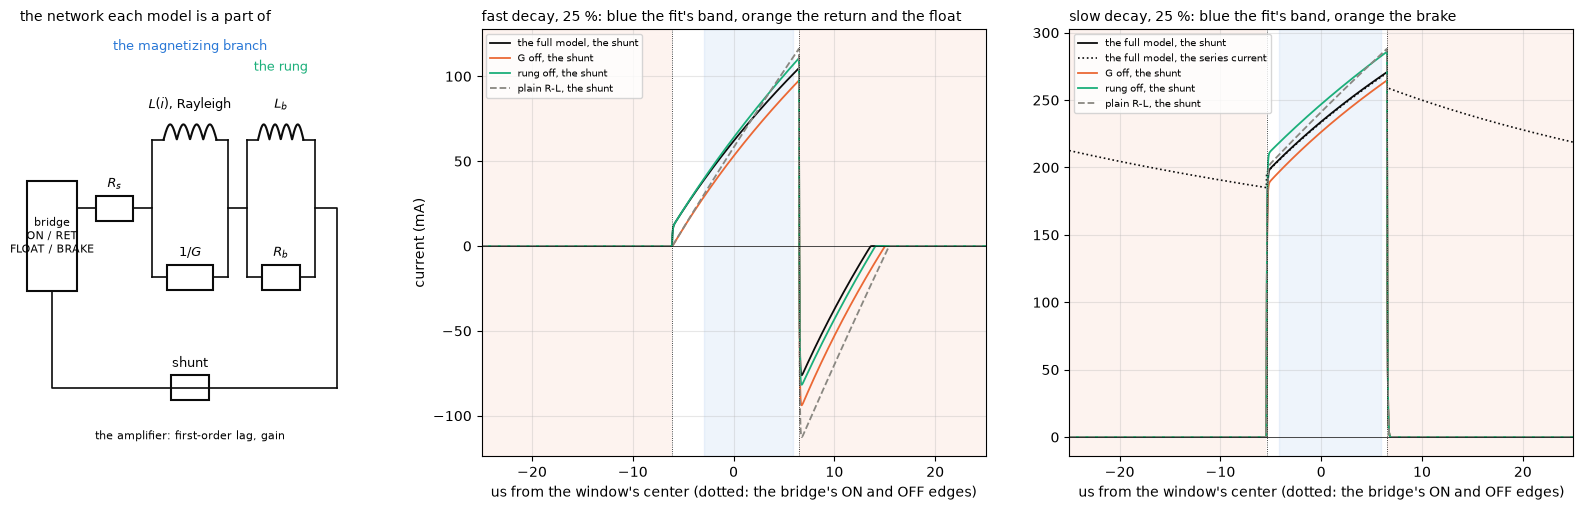

In [4]:
# the motor's joint fast + slow fit of Rayleigh + G + rung, rule 2, on its 25 % forward folds, and the same with each part switched
# off, over one period in fast decay and one in slow decay, the bridge's modes shaded and the fit's band marked
JM = JOINT[("motor", "RGb", 2)]
P_MOT = {n: v for (n, k), v in zip(JM["names"], JM["x"]) if n != "rs_slow"}
P_MOT.update(mem=2)
fig = plt.figure(figsize=(16, 5.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.05, 1.4, 1.4])
a0 = fig.add_subplot(gs[0]); a0.set_axis_off(); a0.set_xlim(0, 10); a0.set_ylim(0, 6.2)


def resistor(a, x0, x1, y, label):
    a.add_patch(Rectangle((x0, y - 0.18), x1 - x0, 0.36, fill=False, lw=1.5, color=INK)); a.text((x0 + x1) / 2, y + 0.3, label, ha="center", fontsize=9)


def coil(a, x0, x1, y, label, below=False):
    xs = np.linspace(x0, x1, 200); a.plot(xs, y + 0.22 * np.abs(np.sin((xs - x0) / (x1 - x0) * 4 * np.pi)), color=INK, lw=1.5)
    a.text((x0 + x1) / 2, y - 0.45 if below else y + 0.45, label, ha="center", fontsize=9)


def wire(a, xs, ys):
    a.plot(xs, ys, color=INK, lw=1.2)


# the bridge as a source, the series R, the magnetizing L(i) with G across it, the rung Lb || Rb, the shunt and amplifier
a0.add_patch(Rectangle((0.2, 2.4), 1.3, 1.6, fill=False, lw=1.5, color=INK)); a0.text(0.85, 3.2, "bridge\nON / RET\nFLOAT / BRAKE", ha="center", va="center", fontsize=8)
wire(a0, [1.5, 2.0], [3.6, 3.6]); resistor(a0, 2.0, 3.0, 3.6, "$R_s$"); wire(a0, [3.0, 3.5, 3.5], [3.6, 3.6, 4.6]); wire(a0, [3.5, 3.5], [3.6, 2.6])
coil(a0, 3.8, 5.2, 4.6, "$L(i)$, Rayleigh"); wire(a0, [3.5, 3.8], [4.6, 4.6]); wire(a0, [5.2, 5.5], [4.6, 4.6])
resistor(a0, 3.9, 5.1, 2.6, "$1/G$"); wire(a0, [3.5, 3.9], [2.6, 2.6]); wire(a0, [5.1, 5.5], [2.6, 2.6]); wire(a0, [5.5, 5.5], [2.6, 4.6])
wire(a0, [5.5, 6.0], [3.6, 3.6]); wire(a0, [6.0, 6.0], [2.6, 4.6])
coil(a0, 6.3, 7.5, 4.6, "$L_b$"); wire(a0, [6.0, 6.3], [4.6, 4.6]); wire(a0, [7.5, 7.8], [4.6, 4.6])
resistor(a0, 6.4, 7.4, 2.6, "$R_b$"); wire(a0, [6.0, 6.4], [2.6, 2.6]); wire(a0, [7.4, 7.8], [2.6, 2.6]); wire(a0, [7.8, 7.8], [2.6, 4.6])
a0.text(6.9, 5.6, "the rung", ha="center", fontsize=9, color=GREEN); a0.text(4.5, 5.9, "the magnetizing branch", ha="center", fontsize=9, color=BLUE)
wire(a0, [7.8, 8.4, 8.4], [3.6, 3.6, 1.0]); wire(a0, [8.4, 0.85, 0.85], [1.0, 1.0, 2.4])
resistor(a0, 4.0, 5.0, 1.0, "shunt"); a0.text(4.5, 0.25, "the amplifier: first-order lag, gain", ha="center", fontsize=8)
a0.set_title("the network each model is a part of", loc="left", fontsize=10)
for col, decay, s in ((1, "fast", "motor"), (2, "slow", "cap-11")):
    a = fig.add_subplot(gs[col])
    f = mm.pick(mm.cached_folds(s), decay, pcts=(25,), signs=(1,))[0]
    p = dict(P_MOT, rs=mm.rs_of(f) if decay == "fast" else mm.value(JM, "rs_slow", "cap-11"))   # the stall R in fast decay, capture-1's own R in slow
    modes, t0_ = mm.schedule(decay, f["half"], f["on_lag"], f["off_lag"])
    tt = np.arange(len(modes)) + t0_
    per = (tt >= 8 * mm.P - mm.ARR) & (tt < 9 * mm.P - mm.ARR)          # one period late in the burst, centered on its window
    ph = ((tt[per] + mm.ARR) % mm.P) - mm.ARR
    o = np.argsort(ph)
    for lab, q, c, ls in (("the full model", p, INK, "-"), ("G off", dict(p, g=0.0), ORANGE, "-"), ("rung off", dict(p, lb=0.0), GREEN, "-"),
                          ("plain R-L", dict(rs=p["rs"], l0=p["l0"], mem=2), MUTED, "--")):
        _t, sh, ser, _x = mm.simulate(q, f)
        a.plot(ph[o] / mm.TPU, sh[per][o], ls, color=c, lw=1.3, label=f"{lab}, the shunt")
        if lab == "the full model" and decay == "slow":
            a.plot(ph[o] / mm.TPU, ser[per][o], ":", color=INK, lw=1.2, label="the full model, the series current")
    md = modes[per][o]
    for code, name, shade in ((mm.RET, "RET", 0.08), (mm.BRAKE, "BRAKE", 0.08)):
        w = md == code
        if w.any():
            a.fill_between(ph[o] / mm.TPU, 0, 1, where=w, transform=a.get_xaxis_transform(), color=ORANGE, alpha=shade, lw=0)
    band0 = mm.band_of(s) if decay == "fast" else 60
    a.axvspan((f["on"] + band0) / mm.TPU, (f["off"] - 30) / mm.TPU, color=BLUE, alpha=0.08)
    a.axvline(f["on"] / mm.TPU, color=INK, lw=0.6, ls=":"); a.axvline(f["off"] / mm.TPU, color=INK, lw=0.6, ls=":")
    a.axhline(0, color=INK, lw=0.5); a.grid(alpha=0.3); a.set_xlim(-mm.ARR / mm.TPU, mm.ARR / mm.TPU)
    a.set_xlabel("us from the window's center (dotted: the bridge's ON and OFF edges)")
    a.set_title(f"{decay} decay, 25 %: blue the fit's band, orange {'the return and the float' if decay == 'fast' else 'the brake'}", loc="left", fontsize=10)
    a.legend(fontsize=7, loc="upper left")
fig.axes[1].set_ylabel("current (mA)")
plt.tight_layout(); plt.show()

$G$ lifts the window from its first tick, by about 12 mA there and 7 mA at its last tick in fast decay. The rung acts as a resistance in series on the window's time scale, so switching it off raises the window a little and deepens the return. The plain R-L starts from zero at the ON edge in fast decay and draws a straighter ramp. In slow decay the series current runs on through the brake and sets where the next window starts, and the shunt reads nothing there. The band leaves out the first 3.1 us of fast decay's window on the motor, where the ring's charge sits, and everything after the OFF edge.

## The board's floor

Before any model is read on a coil, the same method on the control says how small a term the board and the method can resolve. The control is bridge-states' resistor and inductor A, a powdered-iron inductor, run in the levels sitting, so the board, the wiring and the rails are the coil runs' own. Below, the ideal R-L fitted jointly to its three rails, two duties and both signs, each run's mean residual inside the band with its standard error on the left, and its chi2 per point on the right. The thing to see is how close to zero a known part reads.

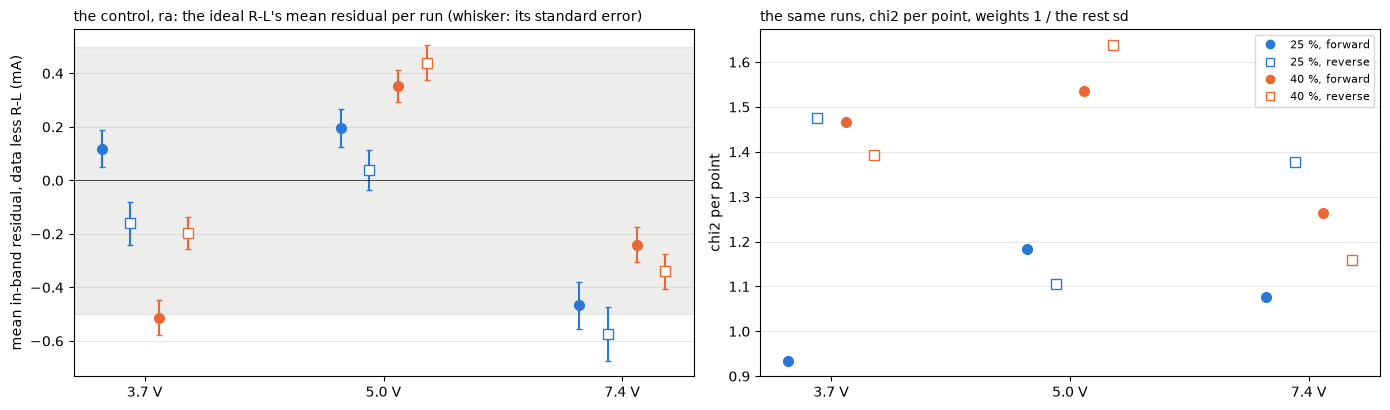

ra, ideal R-L over every rail, duty and sign: chi2/dof 1.33, L 1.033 mH, per run chi2/n 0.93 to 1.64, mean residuals -0.57 to +0.44 mA
L per rail from the rail test: 3v7 1.045, 5v0 1.024, 7v4 1.033 mH; the edge term per rail as a G: 3v7 +0.12 mA, 5v0 -0.08 mA, 7v4 -0.16 mA
ra: a G allowed to go negative fits -0.46 mS, chi2/dof 1.329 for the R-L and 1.318 with G (-0.8 %)
bs-ra: a G allowed to go negative fits -0.44 mS, chi2/dof 1.557 for the R-L and 1.558 with G (+0.1 %)
bs-rab: a G allowed to go negative fits -1.20 mS, chi2/dof 1.209 for the R-L and 1.212 with G (+0.2 %)


In [5]:
ra = FAST[("ra", "RL")]["joint"]
PF = pd.DataFrame(ra["per_fold"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for j, (lv, g) in enumerate(PF.groupby("level")):
    for k, (_, r) in enumerate(g.iterrows()):
        x = j + (k - 1.5) * 0.12
        c = BLUE if r["pct"] == 25 else ORANGE
        ax[0].errorbar(x, r["mean_ma"], yerr=r["rms_ma"] / np.sqrt(r["n"]), fmt="o" if r["sign"] > 0 else "s", ms=7, color=c, mfc=c if r["sign"] > 0 else "white", capsize=2)
        ax[1].plot(x, r["chi2n"], "o" if r["sign"] > 0 else "s", ms=7, color=c, mfc=c if r["sign"] > 0 else "white")
for a in ax:
    a.set_xticks(range(3), ["3.7 V", "5.0 V", "7.4 V"]); a.grid(alpha=0.3, axis="y")
ax[0].axhspan(-0.5, 0.5, color=MUTED, alpha=0.15); ax[0].axhline(0, color=INK, lw=0.5)
ax[0].set_ylabel("mean in-band residual, data less R-L (mA)"); ax[1].set_ylabel("chi2 per point")
ax[0].set_title("the control, ra: the ideal R-L's mean residual per run (whisker: its standard error)", loc="left", fontsize=10)
ax[1].set_title("the same runs, chi2 per point, weights 1 / the rest sd", loc="left", fontsize=10)
ax[1].legend(handles=[plt.Line2D([], [], ls="none", marker="o", color=BLUE, label="25 %, forward"), plt.Line2D([], [], ls="none", marker="s", color=BLUE, mfc="white", label="25 %, reverse"),
                      plt.Line2D([], [], ls="none", marker="o", color=ORANGE, label="40 %, forward"), plt.Line2D([], [], ls="none", marker="s", color=ORANGE, mfc="white", label="40 %, reverse")], fontsize=8)
plt.tight_layout(); plt.show()
print(f"ra, ideal R-L over every rail, duty and sign: chi2/dof {ra['chi2']:.2f}, L {ra['x'][0] * 1e3:.3f} mH, per run chi2/n {PF['chi2n'].min():.2f} to {PF['chi2n'].max():.2f}, "
      f"mean residuals {PF['mean_ma'].min():+.2f} to {PF['mean_ma'].max():+.2f} mA")
print("L per rail from the rail test:", ", ".join(f"{r['level']} {r['l0'] * 1e3:.3f}" for r in RAIL[("ra", "RL")]["G"]["rows"]), "mH; "
      "the edge term per rail as a G:", ", ".join(f"{r['level']} {r['edge_ma']:+.2f} mA" for r in RAIL[("ra", "RL")]["G"]["rows"]))
for s in ("ra", "bs-ra", "bs-rab"):
    rl, lg = FAST[(s, "RL")]["joint"], FAST[(s, "LG")]["joint"]
    print(f"{s}: a G allowed to go negative fits {mm.value(lg, 'g') * 1e3:+.2f} mS, chi2/dof {rl['chi2']:.3f} for the R-L and {lg['chi2']:.3f} with G "
          f"({(lg['chi2'] / rl['chi2'] - 1) * 100:+.1f} %)")

The ideal R-L fits the control at a chi2 per point of 1.33 over three rails, two duties and both signs, every run between 0.93 and 1.64, with mean residuals from -0.57 to +0.44 mA. The rail test below puts its edge term at +0.12, -0.08 and -0.16 mA at 3.7, 5.0 and 7.4 V. A $G$ allowed to go negative fits -0.46 mS on the levels control, -0.44 mS on bridge-states' inductor A and -1.20 mS on A and B in series, and it changes the chi2 per point by under 1 % on each. A negative $G$ is what an inductance that falls with its current reads as, and a powdered-iron core's does, so those values most likely belong to the inductors. So a term that reads like $G$ under about 0.5 mS, or an edge current under about 0.3 mA, is not separable from the board and the control's own inductor, with high confidence. A timing error in the bridge's edges would read like $G$ too, since a ramp shifted by $\Delta t$ adds $(V/L)\,\Delta t$, in proportion to the volts. The control's edge terms bound that shift at about 35 ns, under two ticks, and on the motor's 0.5 mH at 4.95 V that is under 0.4 mA of the 12 mA loss term below. The board's timing does not make the loss.

## Which model, held out

Each model's joint chi2 per point in fast decay, the mean of its held-out tests on the folds left out, and fast decay's prediction of slow decay with $R$ held under the better memory rule, on a log axis, for the bare coil, the coil in the can and the motor. The dashed line is the control's ideal R-L. The models are sorted by their joint fit. The thing to see is which models stay near the dashed line on data they were not fitted to.

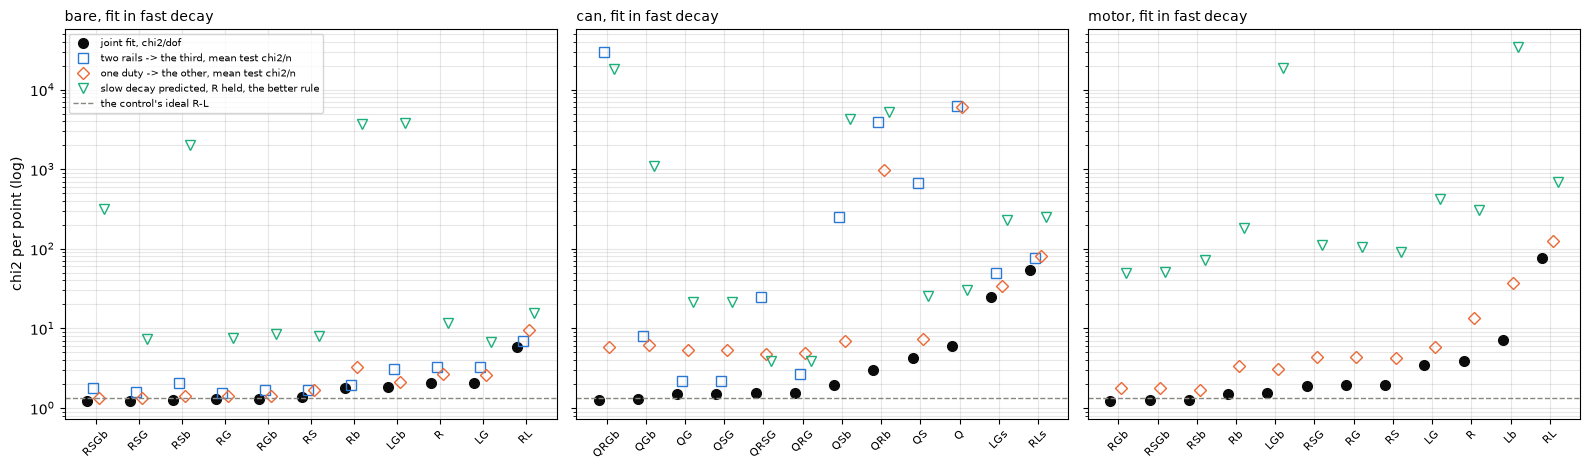

bare  RL    R-L                                    joint   5.76 | rails out 3.84 / 7.36 / 9.75   | duty 25 -> 40    11.96, 40 -> 25   6.89 | slow decay, R held, rule 1     15.5, rule 2     15.5
bare  LG    L||G                                   joint   2.07 | rails out 1.90 / 2.87 / 5.05   | duty 25 -> 40     3.20, 40 -> 25   1.99 | slow decay, R held, rule 1      6.8, rule 2      6.8
bare  LGb   L||G + rung                            joint   1.86 | rails out 1.93 / 2.60 / 4.63   | duty 25 -> 40     2.52, 40 -> 25   1.74 | slow decay, R held, rule 1   3794.3, rule 2   3794.3
bare  R     Rayleigh                               joint   2.04 | rails out 2.31 / 2.73 / 4.88   | duty 25 -> 40     2.98, 40 -> 25   2.31 | slow decay, R held, rule 1     65.9, rule 2     11.7
bare  RG    Rayleigh + G                           joint   1.28 | rails out 1.24 / 1.77 / 1.60   | duty 25 -> 40     1.39, 40 -> 25   1.39 | slow decay, R held, rule 1     30.5, rule 2      7.5
bare  RS    Rayleigh + step   

In [6]:
def ho_row(s, k):
    # the joint chi2/dof, the held-out tests pooled per kind, and the slow-decay prediction with R held under each memory rule
    tests = {t: mm.pooled(REFIT[(s, k, t)]["test"]) for t in mm.tests_of(s)}
    sl = FAST[(s, k)]["slow_pred"]
    return dict(set=s, key=k, model=mm.suite(mm.KIND[s])[k].name, joint=FAST[(s, k)]["joint"]["chi2"],
                rails=[v for t, v in tests.items() if t[0] == "rail"], duty25=tests[("duty_from", 25)], duty40=tests[("duty_from", 40)],
                slow1=mm.pooled(sl[1]), slow2=mm.pooled(sl[2]))


HO = pd.DataFrame([ho_row(s, k) for s in HELD for k in SUITE[s]])
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for a, s in zip(ax, HELD):
    g = HO[HO["set"] == s].sort_values("joint").reset_index(drop=True)
    x = np.arange(len(g))
    a.semilogy(x - 0.2, g["joint"], "o", ms=7, color=INK, label="joint fit, chi2/dof")
    if s != "motor":
        a.semilogy(x - 0.07, [np.mean(r) for r in g["rails"]], "s", ms=7, color=BLUE, mfc="none", label="two rails -> the third, mean test chi2/n")
    a.semilogy(x + 0.07, (g["duty25"] + g["duty40"]) / 2, "D", ms=6, color=ORANGE, mfc="none", label="one duty -> the other, mean test chi2/n")
    a.semilogy(x + 0.2, np.minimum(g["slow1"], g["slow2"]), "v", ms=7, color=GREEN, mfc="none", label="slow decay predicted, R held, the better rule")
    a.axhline(FAST[("ra", "RL")]["joint"]["chi2"], color=MUTED, lw=1, ls="--", label="the control's ideal R-L")
    a.set_xticks(x, g["key"], rotation=45, fontsize=8); a.set_title(f"{s}, fit in fast decay", loc="left", fontsize=10); a.grid(alpha=0.3, which="both")
ax[0].set_ylabel("chi2 per point (log)"); ax[0].legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()
for _, r in HO.iterrows():
    rails = " / ".join(f"{v:.2f}" for v in r["rails"]) if r["rails"] else "-"
    print(f"{r['set']:5s} {r['key']:5s} {r['model']:38s} joint {r['joint']:6.2f} | rails out {rails:20s} | duty 25 -> 40 {r['duty25']:8.2f}, 40 -> 25 {r['duty40']:6.2f} "
          f"| slow decay, R held, rule 1 {r['slow1']:8.1f}, rule 2 {r['slow2']:8.1f}")
print("the motor's slow decay with each capture's R refitted, chi2/dof:", ", ".join(f"{k} rule {m} {RFREE[('motor', k, m)]['chi2']:.1f}" for _, k, m in RF_IDX))

No linear network fits, and the held-out tests show it. On the bare coil R-L reads 5.76 jointly and 3.8 to 9.8 on the rails left out, and L||G 2.07 jointly and 1.90, 2.87 and 5.05 on the rails out. In the can L||G per sign reads 25 jointly and 22 to 98 on the rails out. On the motor R-L reads 77 and L||G 3.44, with 7.38 and 4.27 on the duties out. High confidence.

On the bare coil Rayleigh + G fits at 1.28 and predicts the rail left out at 1.24, 1.77 and 1.60 and the duty left out at 1.39 and 1.39, at the control's floor. With an onset step added it fits at 1.23 and predicts as well. In the can the per-sign quadratic + G fits at 1.52 and predicts the rails left out at 1.74 to 2.77. The can's test from 25 to 40 % fails for every model with a polynomial $L(i)$, 8 to 12132, since a quadratic in the current fitted up to 25 %'s currents does not reach 40 %'s. On the motor the rung is what fast decay asks for. Rayleigh + G + rung fits at 1.24 and predicts the other duty at 2.03 and 1.56, where Rayleigh + G reads 1.92 jointly and 5.25 and 3.58 on the duty out.

Slow decay separates the rest, though not as a clean hold-out, since the memory rule is picked on the slow data it is scored on. With $R$ held, the bare coil's Rayleigh + G predicts it at 7.5 under rule 2 and 30.5 under rule 1, and the motor's Rayleigh + G + rung predicts its three captures at 50 under rule 2 and 350 under rule 1. The motor reaches 4.2 under rule 2 only with each capture's $R$ refitted on the slow folds it is scored on, 4.196 ohm for fast-1, 4.304 for reversal-1 and 4.445 for capture-1. Fast-1's own fast groups run at rest-resistance's 4.497 ohm, so within one capture its slow groups refit 7 % under its fast groups. On the motor this is a test of the slow window's shape with $R$ free, not a prediction of slow decay from fast. Without the rung no motor model reaches it, 59 to 379 with $R$ refitted and 91 to 701 with it held.

### The rail test

The levels runs hold one coil at three rails, which separates a term in proportion to the volts from a fixed current. With each set's shape held at its fast-decay joint fit, $L_0$ and the edge term are refitted per rail, once as a conductance, whose edge current is $G V_\mathrm{on}$, and once as an onset step, a fixed current. A line is fitted to the three edge currents against the window's volts, its errors from its own scatter with one degree of freedom. A term in proportion to the volts falls on a line through zero, a fixed current on a flat line. The control sets the floor again.

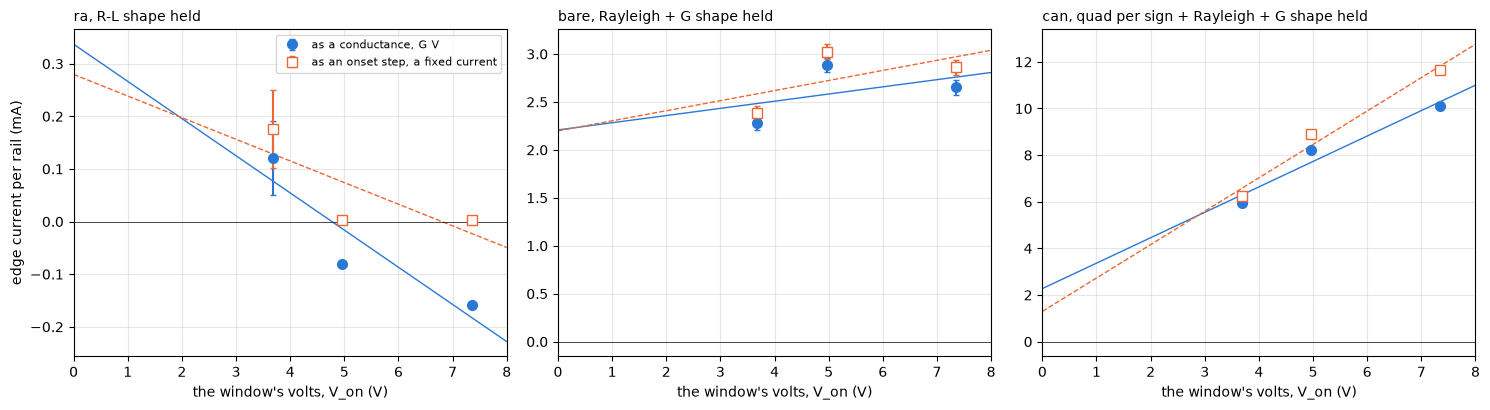

ra G   : 3v7 0.12 +/- 0.07 mA (chi2 1.26), 5v0 -0.08 (no Jacobian error) mA (chi2 1.27), 7v4 -0.16 (no Jacobian error) mA (chi2 1.17) | line +0.34 +/- 0.18 mA + -0.071 +/- 0.032 mS x V, two-sided p under t with one dof: intercept 0.31, slope 0.27
ra step: 3v7 0.18 +/- 0.07 mA (chi2 1.26), 5v0 0.00 (no Jacobian error) mA (chi2 1.27), 7v4 0.00 (no Jacobian error) mA (chi2 1.20) | line +0.28 +/- 0.19 mA + -0.041 +/- 0.035 mS x V, two-sided p under t with one dof: intercept 0.38, slope 0.45
bare G   : 3v7 2.28 +/- 0.07 mA (chi2 1.14), 5v0 2.89 +/- 0.08 mA (chi2 1.49), 7v4 2.65 +/- 0.08 mA (chi2 0.92) | line +2.21 +/- 0.80 mA + +0.075 +/- 0.145 mS x V, two-sided p under t with one dof: intercept 0.22, slope 0.70
bare step: 3v7 2.39 +/- 0.07 mA (chi2 1.14), 5v0 3.03 +/- 0.08 mA (chi2 1.49), 7v4 2.86 +/- 0.08 mA (chi2 0.92) | line +2.20 +/- 0.80 mA + +0.105 +/- 0.145 mS x V, two-sided p under t with one dof: intercept 0.22, slope 0.60
can G   : 3v7 5.93 +/- 0.08 mA (chi2 1.33), 5v0 8.23 +/- 0

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (s, k) in zip(ax, RAILS):
    for form, mk, mfc in (("G", "o", None), ("step", "s", "white")):
        rows = RAIL[(s, k)][form]["rows"]
        v = np.array([r["v_on"] for r in rows]); e = np.array([r["edge_ma"] for r in rows]); se = np.array([r["se_ma"] for r in rows])
        c = BLUE if form == "G" else ORANGE
        a.errorbar(v, e, yerr=se, fmt=mk, ms=7, color=c, mfc=mfc or c, capsize=2, label=f"as {'a conductance, G V' if form == 'G' else 'an onset step, a fixed current'}")
        ic, sl = RAIL[(s, k)][form]["intercept"], RAIL[(s, k)][form]["slope"]
        vv = np.linspace(0, 8, 10); a.plot(vv, ic[0] + sl[0] * vv, "-" if form == "G" else "--", color=c, lw=1)
    a.axhline(0, color=INK, lw=0.5); a.set_xlim(0, 8); a.grid(alpha=0.3)
    a.set_xlabel("the window's volts, V_on (V)"); a.set_title(f"{s}, {mm.suite(mm.KIND[s])[k].name} shape held", loc="left", fontsize=10)
ax[0].set_ylabel("edge current per rail (mA)"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
for (s, k), r in RAIL.items():
    for form in ("G", "step"):
        q = r[form]
        print(f"{s} {form:4s}: " + ", ".join(f"{x['level']} {x['edge_ma']:.2f} " + (f"+/- {x['se_ma']:.2f}" if np.isfinite(x['se_ma']) else "(no Jacobian error)") + f" mA (chi2 {x['chi2']:.2f})" for x in q["rows"])
              + f" | line {q['intercept'][0]:+.2f} +/- {q['intercept'][1]:.2f} mA + {q['slope'][0]:+.3f} +/- {q['slope'][1]:.3f} mS x V"
              + f", two-sided p under t with one dof: intercept {2 * stats.t.sf(abs(q['intercept'][0] / q['intercept'][1]), 1):.2f}, "
              f"slope {2 * stats.t.sf(abs(q['slope'][0] / q['slope'][1]), 1):.2f}")
for s, k in (("bare", "RG"), ("can", "QRG"), ("motor", "RGb")):
    j = FAST[(s, k)]["joint"]
    nm = [n for n, kk in j["names"]]
    c = {(a_, b_): j["corr"][nm.index(a_), nm.index(b_)] for a_ in ("l0", "g", "cr") for b_ in ("l0", "g", "cr") if a_ < b_}
    print(f"{s} {k} fast decay, correlations: " + ", ".join(f"{a_}-{b_} {v:+.2f}" for (a_, b_), v in c.items()))

On the bare coil the edge current is 2.28, 2.89 and 2.65 mA at the three rails as a $G$, and 2.39, 3.03 and 2.86 mA as a step, each far above the control's. The line through them is 2.21 $\pm$ 0.80 mA plus 0.075 $\pm$ 0.145 mS times the volts. Its errors come from one degree of freedom, so the intercept's 2.8 standard errors are a two-sided p of 0.22 under Student's t, and the three points are not monotonic, so a line describes them poorly. So the bare coil carries an edge current of 2.3 to 2.9 mA at every rail, high confidence, and whether it follows the rail is not settled, low confidence that it does not. As a $G$ it reads 0.73 mS in the joint fit, inside the control's floor, so its size is identified and its form is not. $G$ and the step trade freely on this coil.

In the can the edge current is 5.93, 8.23 and 10.10 mA, rising with the rail, a line of 2.28 $\pm$ 1.42 mA plus 1.09 $\pm$ 0.26 mS times the volts. The slope is 4 standard errors from zero, but on one degree of freedom that is a p of 0.15, so the line alone does not carry the form. The step form's miss at 7.4 V carries more of it, a chi2 per point of 3.93 against 1.35 for $G$. So in the can the edge term is mostly a conductance, moderate confidence on the form and on its size.

The correlations at each set's fast-decay optimum say which parameters trade. On the bare coil and the motor $L_0$ and $G$ run together at +0.83 and +0.96, and the Rayleigh term against both at -0.63 to -0.93. In the can the per-sign shape takes up part of what the Rayleigh term does, and its correlations with $L_0$ and $G$ are +0.52 and +0.36. So on every set the trio of $L_0$, $G$ and the Rayleigh term is identified as a whole better than one at a time.

## The motor, one model for fast and slow decay

Fast decay alone leaves the memory rule and part of the shape open, so the forms that survive are fitted to fast and slow decay together, with the memory rule fixed, the coils' $R$ held and the motor's slow decay given one $R$ per capture. Each joint fit is held out the same way, and the tests are scored on both decays. Then the motor's joint fit drawn against time in the window, data less model in 8-tick bins, for fast-1's fast groups and for the slow groups of fast-1, capture-1 and reversal-1 at the same seat. Last, every run's mean residual for the working models beside the control's.

bare  Rayleigh + G                         rule 2: chi2/dof 2.64 | rails out fast 1.21, 1.81, 2.71 / slow 3.16, 5.96, 6.53 | duty 25 -> 40 fast 3.26 slow 5.41, 40 -> 25 fast 1.77 slow 4.19
bare  Rayleigh + G                         rule 1: chi2/dof 3.15 | rails out fast 1.79, 2.55, 4.33 / slow 3.47, 5.83, 7.55 | duty 25 -> 40 fast 2.09 slow 7.43, 40 -> 25 fast 2.24 slow 4.23
bare  Rayleigh + step + G                  rule 2: chi2/dof 2.60 | rails out fast 1.51, 1.88, 2.71 / slow 2.47, 5.78, 6.57 | duty 25 -> 40 fast 2.07 slow 5.05, 40 -> 25 fast 1.70 slow 4.09
can   quad per sign + G                    rule 1: chi2/dof 5.65 | rails out fast 1.77, 2.07, 12.55 / slow 9.97, 17.81, 56.26 | duty 25 -> 40 fast 2.97 slow 57.89, 40 -> 25 fast 1.50 slow 18.31
can   quad per sign + Rayleigh + G         rule 1: chi2/dof 1.94 | rails out fast 1.53, 1.88, 2.95 / slow 2.63, 3.84, 5.39 | duty 25 -> 40 fast 2.82 slow 6.03, 40 -> 25 fast 1.50 slow 2.54
can   quad per sign + Rayleigh + G         rule 2:

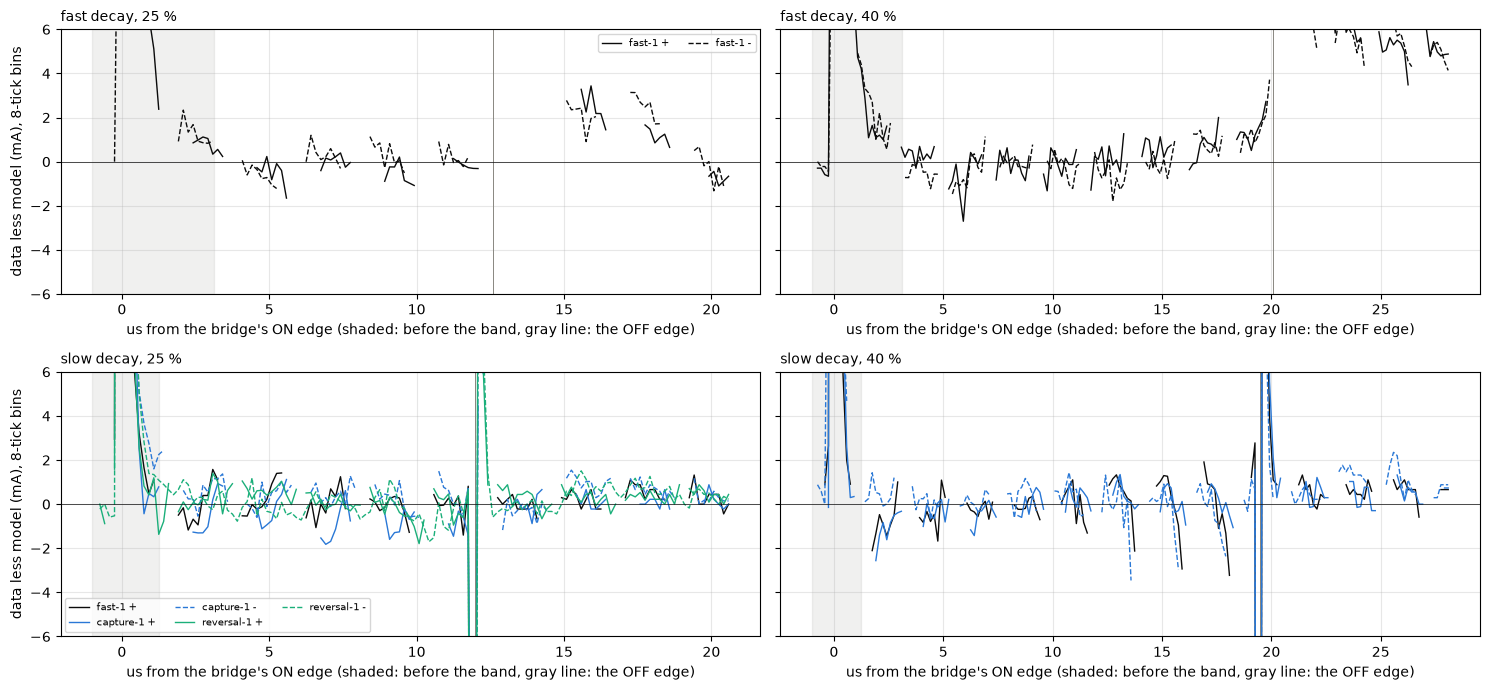

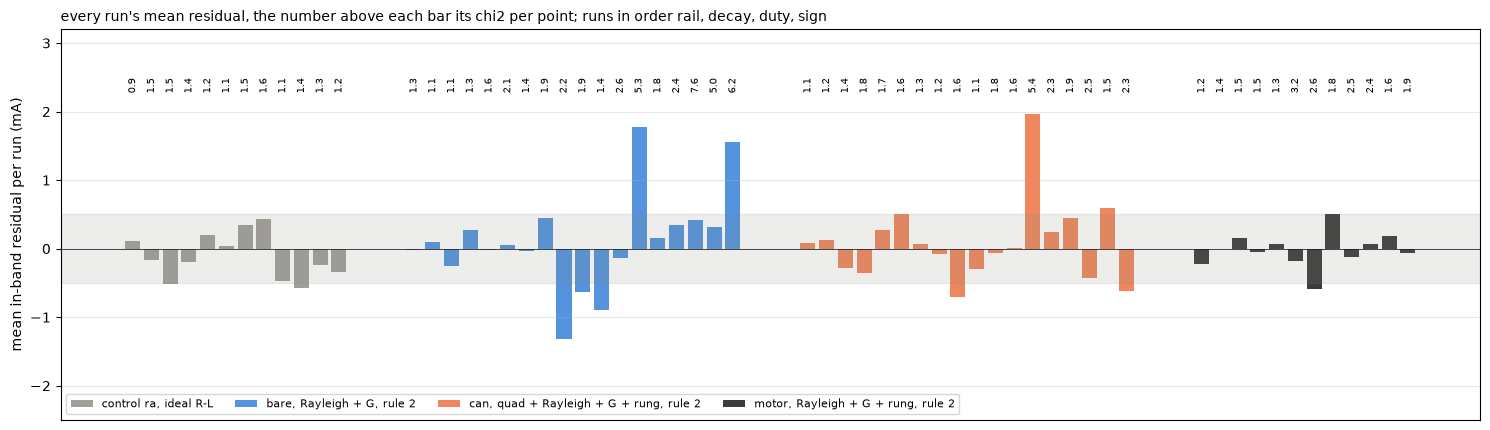

bare, Rayleigh + G, rule 2: 3v7 fast 25 +1 1.28 -0.02, 3v7 fast 25 -1 1.10 +0.10, 3v7 fast 40 +1 1.14 -0.25, 3v7 fast 40 -1 1.31 +0.28, 5v0 fast 25 +1 1.64 -0.02, 5v0 fast 25 -1 2.12 +0.05, 5v0 fast 40 +1 1.42 -0.03, 5v0 fast 40 -1 1.95 +0.45, 7v4 fast 25 +1 2.18 -1.32, 7v4 fast 25 -1 1.86 -0.63, 7v4 fast 40 +1 1.42 -0.90, 7v4 fast 40 -1 2.62 -0.14, 3v7 slow 25 +1 5.33 +1.78, 3v7 slow 40 +1 1.77 +0.16, 5v0 slow 25 +1 2.45 +0.35, 5v0 slow 40 +1 7.56 +0.42, 7v4 slow 25 +1 5.05 +0.32, 7v4 slow 40 +1 6.22 +1.55
can, quad + Rayleigh + G + rung, rule 2: 3v7 fast 25 +1 1.09 +0.08, 3v7 fast 25 -1 1.24 +0.12, 3v7 fast 40 +1 1.43 -0.28, 3v7 fast 40 -1 1.76 -0.35, 5v0 fast 25 +1 1.73 +0.27, 5v0 fast 25 -1 1.63 +0.51, 5v0 fast 40 +1 1.31 +0.06, 5v0 fast 40 -1 1.20 -0.07, 7v4 fast 25 +1 1.55 -0.71, 7v4 fast 25 -1 1.06 -0.30, 7v4 fast 40 +1 1.80 -0.06, 7v4 fast 40 -1 1.58 +0.01, 3v7 slow 25 +1 5.37 +1.96, 3v7 slow 40 +1 2.25 +0.24, 5v0 slow 25 +1 1.86 +0.45, 5v0 slow 40 +1 2.52 -0.42, 7v4 slow 25 +1

In [8]:
def jrow(s, k, m):
    j = JOINT[(s, k, m)]
    t = {tt: JREFIT[(s, k, m, tt)]["test"] for tt in mm.tests_of(s)}
    pool = lambda rows, d: mm.pooled([q for q in rows if q["decay"] == d])
    return dict(set=s, key=k, mem=m, chi2=j["chi2"], n=j["n"],
                rails=[(pool(v, "fast"), pool(v, "slow")) for tt, v in t.items() if tt[0] == "rail"],
                duty25=(pool(t[("duty_from", 25)], "fast"), pool(t[("duty_from", 25)], "slow")),
                duty40=(pool(t[("duty_from", 40)], "fast"), pool(t[("duty_from", 40)], "slow")))


JT = pd.DataFrame([jrow(*key) for key in JOINTS])
for _, r in JT.iterrows():
    rails = ("fast " + ", ".join(f"{a:.2f}" for a, b in r["rails"]) + " / slow " + ", ".join(f"{b:.2f}" for a, b in r["rails"])) if r["rails"] else "-"
    print(f"{r['set']:5s} {mm.suite(mm.KIND[r['set']])[r['key']].name:36s} rule {r['mem']}: chi2/dof {r['chi2']:.2f} | rails out {rails} | "
          f"duty 25 -> 40 fast {r['duty25'][0]:.2f} slow {r['duty25'][1]:.2f}, 40 -> 25 fast {r['duty40'][0]:.2f} slow {r['duty40'][1]:.2f}")
PJ = pd.DataFrame(JM["per_fold"])
print("the motor, rule 2, per run:", ", ".join(f"{r['set']} {r['decay']} {r['pct']} {r['sign']:+d}: {r['chi2n']:.2f} {r['mean_ma']:+.2f}" for _, r in PJ.iterrows()))
print("the motor's series R in slow decay per capture:", ", ".join(f"{k} {v:.3f} +/- {e:.3f}" for (n, k), v, e in zip(JM["names"], JM["x"], JM["sd"]) if n == "rs_slow"), "ohm")


def resid_curves(key):
    # data less the joint fit per fold, in 8-tick bins against the ticks from the bridge's ON edge
    s, k, m = key
    jm = mm.joint_model(s, k, m)
    out = []
    for f in mm.fast_folds(s) + mm.slow_folds(s):
        p = mm.params_for(jm, JOINT[key]["names"], JOINT[key]["x"], f)
        p.setdefault("rs", mm.rs_of(f))
        y = mm.model_y(jm.build(p, f), f)
        keep = f["t"] >= (mm.P - mm.ARR if f["decay"] == "fast" else mm.ARR)
        xe, r = f["x"][keep] - f["on"], (f["i"] - y)[keep]
        bins = np.arange(-40, 2 * f["half"] + 400, 8)
        idx = np.digitize(xe, bins)
        out.append((f, bins[:-1] + 4, np.array([np.mean(r[idx == q]) if (idx == q).sum() > 2 else np.nan for q in range(1, len(bins))])))
    return out


fig, ax = plt.subplots(2, 2, figsize=(15, 7), sharey=True)
COLS = {"motor": INK, "cap-11": BLUE, "rev-11": GREEN}
for f, x, r in resid_curves(("motor", "RGb", 2)):
    a = ax[0 if f["decay"] == "fast" else 1, 0 if f["pct"] == 25 else 1]
    a.plot(x / mm.TPU, r, ls="-" if f["sign"] > 0 else "--", lw=1.0, color=COLS[f["set"]],
           label=f"{ {'motor': 'fast-1', 'cap-11': 'capture-1', 'rev-11': 'reversal-1'}[f['set']]} {'+' if f['sign'] > 0 else '-'}")
    a.axvline((f["off"] - f["on"]) / mm.TPU, color=MUTED, lw=0.6)
for (i, j), a in np.ndenumerate(ax):
    a.axhline(0, color=INK, lw=0.5); a.axvspan(-1, (150 if i == 0 else 60) / mm.TPU, color=MUTED, alpha=0.12)
    a.set_ylim(-6, 6); a.grid(alpha=0.3)
    a.set_title(f"{'fast' if i == 0 else 'slow'} decay, {25 if j == 0 else 40} %", loc="left", fontsize=10)
    a.set_xlabel("us from the bridge's ON edge (shaded: before the band, gray line: the OFF edge)")
ax[0, 0].set_ylabel("data less model (mA), 8-tick bins"); ax[1, 0].set_ylabel("data less model (mA), 8-tick bins")
ax[0, 0].legend(fontsize=7, ncol=2); ax[1, 0].legend(fontsize=7, ncol=3)
plt.tight_layout(); plt.show()

# the per-run residuals of the working models, the control's R-L beside them
fig, ax = plt.subplots(figsize=(15, 4.4))
cases = [("control ra, ideal R-L", FAST[("ra", "RL")]["joint"]["per_fold"], MUTED), ("bare, Rayleigh + G, rule 2", JOINT[("bare", "RG", 2)]["per_fold"], BLUE),
         ("can, quad + Rayleigh + G + rung, rule 2", JOINT[("can", "QRGb", 2)]["per_fold"], ORANGE), ("motor, Rayleigh + G + rung, rule 2", JM["per_fold"], INK)]
x0 = 0
for lab, rows, c in cases:
    q = pd.DataFrame(rows)
    x = np.arange(len(q)) + x0
    x0 += len(q) + 3                                                    # a gap of three runs between the sets
    ax.bar(x, q["mean_ma"], color=c, alpha=0.8, label=lab)
    for xx, (_, r) in zip(x, q.iterrows()):
        ax.text(xx, 2.3, f"{r['chi2n']:.1f}", ha="center", fontsize=7, rotation=90)
ax.axhline(0, color=INK, lw=0.5); ax.axhspan(-0.5, 0.5, color=MUTED, alpha=0.15); ax.set_ylim(-2.5, 3.2)
ax.set_xticks([]); ax.set_ylabel("mean in-band residual per run (mA)"); ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8, loc="lower left", ncol=4)
ax.set_title("every run's mean residual, the number above each bar its chi2 per point; runs in order rail, decay, duty, sign", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
for lab, rows, c in cases[1:3]:
    q = pd.DataFrame(rows)
    print(f"{lab}: " + ", ".join(f"{r['level']} {r['decay']} {r['pct']} {r['sign']:+d} {r['chi2n']:.2f} {r['mean_ma']:+.2f}" for _, r in q.iterrows()))

The motor's Rayleigh + G + rung under rule 2 fits fast and slow decay together at a chi2 per point of 1.94 over twelve runs, each run between 1.25 and 3.22, and the duty held out reads 2.73 and 1.32 in fast decay and 3.55 and 2.55 in slow. Rule 1 reads 2.57, and Rayleigh + G under rule 2, without the rung, 40.0. The residual is flat within about 1.5 mA inside the band in both decays, and only the series $R$ per capture is refitted in slow decay, 4.445, 4.196 and 4.304 ohm for capture-1, fast-1 and reversal-1, where fast-1's fast groups hold rest-resistance's 4.497 ohm. In fast decay the residual climbs 1 to 2 mA in the band's first microsecond, the tail of the ring's charge, and runs several milliamps over the model in the return after the OFF edge, outside the band. So one model reproduces every locked dataset at hole 11 with slow decay's $R$ free per capture, high confidence, and each of its parameters is moderate, since $L_0$, $G$ and the Rayleigh term correlate.

On the bare coil Rayleigh + G under rule 2 fits both decays at 2.64. Its slow-decay runs read up to 7.6 per point, the largest mean residual +1.8 mA at 3.7 V and 25 %. In the can the per-sign quadratic + Rayleigh + G + rung under rule 2 fits at 1.80, and without the rung under rule 1 at 1.94, while rule 2 without the rung reads 3.90. The bare coil and the motor prefer rule 2 in slow decay, and the can without a rung prefers rule 1, so which memory rule is physical is not settled, low confidence. It changes nothing in fast decay.

### The parameters and their ranges

Each parameter's value at the joint fast and slow fit under rule 2, and its range, the union of that fit's Jacobian error, its held-out refits, the band-start and $R$ variants of the set's fast-decay fits, and the alternative joint fits that pass with their refits (the bare coil's Rayleigh + step + G under rule 2, the can's quadratic + Rayleigh + G and the same with a rung under rule 1, the motor's Rayleigh + step + G + rung under rule 2). The Jacobian errors alone are ten to a hundred times smaller than the range and are not the uncertainty. The columns `lo_from` and `hi_from` name the fit each bound comes from. `l_up_pct` and `l_down_pct` are the can's incremental inductance at 0.2 A over $L_0$ for drive sign +1 and -1, and `rb` and `tau_us` the rung's $R_b$ and $L_b/R_b$.

In [9]:
# each parameter's value at the joint fast + slow fit, rule 2, and its range: the union of that fit's Jacobian error, its held-out
# refits, the band-start and R variants of the set's fast-decay fits, and the alternative joint fits that pass, with their refits
PRIMARY = {"bare": ("bare", "RG", 2), "can": ("can", "QRGb", 2), "motor": ("motor", "RGb", 2)}
ALTS = {"bare": [("bare", "RSG", 2)], "can": [("can", "QRG", 1), ("can", "QRGb", 1)], "motor": [("motor", "RSGb", 2)]}


def union(s):
    # every fit in the range's union for one set, as (label, fit, with its Jacobian error)
    out = [("joint, rule 2", JOINT[PRIMARY[s]], True)]
    out += [(f"held out {t[0]} {t[1]}", JREFIT[PRIMARY[s] + (t,)]["fit"], False) for t in mm.tests_of(s)]
    out += [(f"{k} fast decay, {w[0]} {w[1]}", VAR[(ss, k, w)], False) for (ss, k, w) in V_IDX if ss == s]
    for a in ALTS[s]:
        out.append((f"{a[1]} rule {a[2]}", JOINT[a], True))
        out += [(f"{a[1]} rule {a[2]}, held out {t[0]} {t[1]}", JREFIT[a + (t,)]["fit"], False) for t in mm.tests_of(s)]
    return out


def l_change(fit, sign, i=0.2):
    # the incremental L at i amps over L0, in percent, from the fit's per-sign shape and its Rayleigh term counted from zero
    v = lambda n: mm.values(fit, n).get(sign, mm.values(fit, n).get(None, 0.0))
    return ((1 + v("a1") * sign * i + v("a2") * i * i + v("cr") * i) - 1) * 100


DERIVED = {"rb": lambda f: 1 / mm.value(f, "gb"), "tau_us": lambda f: mm.value(f, "lb") * mm.value(f, "gb") * 1e6,
           "l_up_pct": lambda f: l_change(f, 1), "l_down_pct": lambda f: l_change(f, -1)}
SCALE = {"l0": 1e3, "g": 1e3, "lb": 1e3, "cr": 1, "a1": 1, "rb": 1, "tau_us": 1, "l_up_pct": 1, "l_down_pct": 1}


def par(fit, name):
    # one parameter of one fit with its Jacobian error (nan where it has none), or None where the fit does not carry it
    if name in DERIVED:
        try:
            return DERIVED[name](fit), np.nan
        except (ValueError, KeyError):
            return None
    if (name, None) not in fit["names"]:
        return None
    i = fit["names"].index((name, None))
    return float(fit["x"][i]), float(fit["sd"][i])


PARAMS = {"bare": ["l0", "cr", "g"], "can": ["l0", "l_up_pct", "l_down_pct", "cr", "g", "lb", "rb"],
          "motor": ["l0", "cr", "a1", "g", "lb", "rb", "tau_us"]}
PT = []
for s, names in PARAMS.items():
    U = union(s)
    for n in names:
        v0 = par(U[0][1], n)
        lo, hi, lo_by, hi_by = np.inf, -np.inf, "", ""
        for lab, f, jac in U:
            q = par(f, n)
            if q is None:
                continue
            a, b = (q[0] - q[1], q[0] + q[1]) if jac and np.isfinite(q[1]) else (q[0], q[0])
            if a < lo:
                lo, lo_by = a, lab
            if b > hi:
                hi, hi_by = b, lab
        PT.append(dict(set=s, param=n, value=v0[0] * SCALE[n], lo=lo * SCALE[n], hi=hi * SCALE[n], lo_from=lo_by, hi_from=hi_by))
PT = pd.DataFrame(PT)
with pd.option_context("display.float_format", "{:.4g}".format, "display.max_colwidth", 60):
    print(PT.to_string(index=False))
G_FORMS = {k: mm.value(FAST[("motor", k)]["joint"], "g") * 1e3 for k in ("LG", "LGb", "RG", "RSG", "RGb", "RSGb")}
print("the motor's G in fast decay by form:", ", ".join(f"{k} {v:.2f}" for k, v in G_FORMS.items()), "mS")
print("the motor's sign term a1 at the joint fit", f"{mm.value(JM, 'a1'):.3f} per A")
cc = FAST[("coil-can-1", "LGs")]["joint"]
print("coil-can-1, L||G per sign: L0", ", ".join(f"{k:+d} {v * 1e3:.3f}" for k, v in mm.values(cc, "l0").items()), "mH, G",
      ", ".join(f"{k:+d} {v * 1e3:.2f}" for k, v in mm.values(cc, "g").items()), "mS; quad + G:",
      f"G {mm.value(FAST[('coil-can-1', 'QG')]['joint'], 'g') * 1e3:.2f} mS; L0 over every model",
      f"{min(min(mm.values(FAST[('coil-can-1', k)]['joint'], 'l0').values()) for k in SUITE['coil-can-1']) * 1e3:.3f} to "
      f"{max(max(mm.values(FAST[('coil-can-1', k)]['joint'], 'l0').values()) for k in SUITE['coil-can-1']) * 1e3:.3f} mH")
fit_cc = [k for k in SUITE["coil-can-1"] if FAST[("coil-can-1", k)]["joint"]["chi2"] < 2]
print(f"coil-can-1, the models with chi2/dof under 2 ({', '.join(fit_cc)}): L0 "
      f"{min(min(mm.values(FAST[('coil-can-1', k)]['joint'], 'l0').values()) for k in fit_cc) * 1e3:.3f} to "
      f"{max(max(mm.values(FAST[('coil-can-1', k)]['joint'], 'l0').values()) for k in fit_cc) * 1e3:.3f} mH")
nr = {k: FAST[("coil-noring-1", k)]["joint"] for k in ("LG", "RG")}
print(f"coil-noring-1: L||G chi2/dof {nr['LG']['chi2']:.2f}, G {mm.value(nr['LG'], 'g') * 1e3:.2f} mS; Rayleigh + G chi2/dof {nr['RG']['chi2']:.2f}, "
      f"Rayleigh {mm.value(nr['RG'], 'cr'):+.2f} per A, G {mm.value(nr['RG'], 'g') * 1e3:.2f} mS")

  set      param   value        lo      hi                            lo_from                            hi_from
 bare         l0  0.5718    0.5591  0.5803              held out duty_from 25      RSG rule 2, held out rail 5v0
 bare         cr  0.5552     0.388   1.004      RSG rule 2, held out rail 5v0              held out duty_from 25
 bare          g  0.7279    0.3326  0.7848          RSG fast decay, R R + 0.1                  held out rail 7v4
  can         l0  0.3408    0.3184   0.348              held out duty_from 25     QRGb rule 1, held out rail 5v0
  can   l_up_pct   52.26     49.21   59.47     QRGb rule 1, held out rail 5v0              held out duty_from 25
  can l_down_pct  -12.24    -13.35  -9.959     QRGb rule 1, held out rail 5v0      QRG rule 1, held out rail 7v4
  can         cr   1.461     1.269   1.874 QRGb rule 1, held out duty_from 40 QRGb rule 1, held out duty_from 25
  can          g   1.453     1.068   1.711              held out duty_from 25           QRG fast

The motor at hole 11 reads $L_0$ 0.505 mH, a Rayleigh term of 2.9 per A and a sign term of 0.073 per A, $G$ 2.29 mS in this joint fit, and a rung of 0.240 mH with 6.1 ohm, a time constant of 39 us. Across the forms that carry a $G$ the motor's fast-decay $G$ spans 1.77 to 4.00 mS, so $G$ is identified within one form and not across forms. The fast-decay fit of the same form, the one the spinning motor's section holds its $L$ model at, reads $G$ 2.49 mS. The bare coil reads $L_0$ 0.572 mH with a Rayleigh term of 0.56 per A, about 6 % more $L$ per 100 mA. The coil in the can at the levels sitting reads $L_0$ 0.341 mH, its incremental $L$ at 0.2 A 52 % over $L_0$ for drive sign +1 and 12 % under it for -1, a magnet-biased shape, and $G$ 1.45 mS. Its rung, 0.045 mH, appears only under rule 2 and goes to zero under rule 1, so it is marginal. The coil in the can at the other sitting, coil-can-1, reads $L_0$ 0.61 and 0.69 mH by sign under L||G, with $G$ 3.0 and 3.4 mS, and 1.87 mS under the quadratic + G, and its $L_0$ spans 0.45 to 0.69 mH over the models that fit it under 2 per point. With one rail it does not separate them. The bare coil at its other sitting, coil-noring-1, the neighboring coil with the disc on, fits L||G at 1.56 with $G$ 1.15 mS, and with a Rayleigh term it reads -0.26 per A, so that coil shows no Rayleigh rise.

## inductance's open items

Inductance left two numbers no model of its own explained. Its ripple $L$, read inside one window, sits at about 0.77 of its period fit, read over the burst's period pairs, where bridge-states' fixed inductors read 0.97 to 1.01. And its period fit slides up as more period pairs enter. Here the same estimators, unchanged except that the edge volt-ticks are left out of both sides (about 1 % of $L$), run on hole 11's slow-decay bursts of capture-1, fast-1 and reversal-1, once as measured and once with the shunt samples replaced by each model's prediction, the taps kept as measured and each capture's $R$ from its slow-decay refit under the same memory rule. A model that lands on the measured ratio and slide explains them. The dots are the medians over the bursts, the whiskers the 16th to 84th percentiles.

50 bursts through the estimators, data and 6 models
                    l  l_rip  ratio  slide_pct     r3   rmax
model      pct                                              
data       25   0.785  0.604  0.770      8.116  4.633  4.184
           40   0.845  0.617  0.732      5.568  4.690  4.376
RGb rule 2 25   0.781  0.615  0.788      8.386  4.663  4.204
           40   0.832  0.628  0.761      7.313  4.849  4.437
RG rule 2  25   0.621  0.630  1.013      1.850  4.645  4.539
           40   0.679  0.652  0.968      1.201  4.836  4.776
RG rule 1  25   0.663  0.633  0.953      8.817  4.823  4.444
           40   0.742  0.661  0.897     10.482  5.217  4.681
LG rule 1  25   0.643  0.691  1.072      0.627  4.528  4.486
           40   0.668  0.711  1.063      0.478  4.810  4.787
RL rule 1  25   0.554  0.554  1.002      0.969  4.717  4.650
           40   0.561  0.575  1.024      0.915  5.001  4.960
RSG rule 1 25   0.665  0.629  0.944      8.979  4.832  4.441
           40   0.747  0.662  0.8

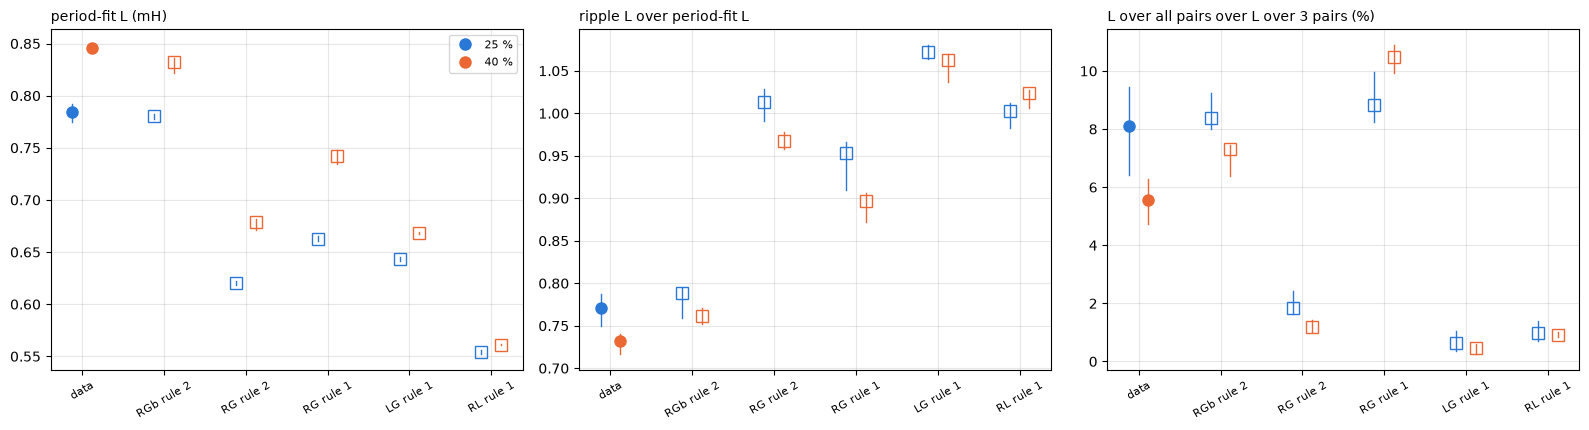

In [10]:
# inductance's estimators on hole 11's slow-decay bursts, as measured and with the shunt replaced by each model, every model the
# motor's fast-decay fit with each capture's R from its slow-decay R refit under the same memory rule
IND_MODELS = {}
for k, m in (("RGb", 2), ("RG", 2), ("RG", 1), ("LG", 1), ("RL", 1), ("RSG", 1)):
    rs = mm.values(RFREE[("motor", k, m)], "rs")
    IND_MODELS[f"{k} rule {m}"] = {s: dict(params_of(FAST[("motor", k)]["joint"]), kc=0.9, mem=m, rs=rs[s]) for s in mm.IND_RUNS}
IR = pd.DataFrame([r for rows in mm.run_parallel([(mm.job_ind, (s, IND_MODELS, part, 4), {}) for s in mm.IND_RUNS for part in range(4)]) for r in rows])
IR["ratio"] = IR["l_rip"] / IR["l"]
IR["slide_pct"] = (IR["lmax"] / IR["l3"] - 1) * 100
print(f"{IR[IR['model'] == 'data'].shape[0]} bursts through the estimators, data and {len(IND_MODELS)} models")
ORDER = ["data", "RGb rule 2", "RG rule 2", "RG rule 1", "LG rule 1", "RL rule 1", "RSG rule 1"]
MED = IR.groupby(["model", "pct"])[["l", "l_rip", "ratio", "slide_pct", "r3", "rmax"]].median().loc[ORDER]
print(MED.round(3).to_string())
SD = IR[IR["model"] == "data"].groupby("pct")[["l", "ratio", "slide_pct"]].std()
print("the data's burst-to-burst sd:", ", ".join(f"{p} %: L {r['l']:.3f} mH, ratio {r['ratio']:.3f}, slide {r['slide_pct']:.1f} %" for p, r in SD.iterrows()))
NB_IND = IR[IR["model"] == "data"].groupby("pct").size()
print("Rayleigh + G + rung less the data, in the data's sd and in its standard error, sd over the root of the bursts: " + "; ".join(
    f"{p} % ({NB_IND[p]} bursts): " + ", ".join(f"{c} {(MED.loc[('RGb rule 2', p), c] - MED.loc[('data', p), c]) / SD.loc[p, c]:+.1f} sd, "
                                                f"{(MED.loc[('RGb rule 2', p), c] - MED.loc[('data', p), c]) / SD.loc[p, c] * np.sqrt(NB_IND[p]):+.0f} se"
                                                for c in ("l", "ratio", "slide_pct")) for p in SD.index))
IND_R = results.read("2-motor", "inductance", pair=mm.MOTOR.key)            # for comparison: its all-hole values
print("inductance's own reads over the twelve holes: period-fit L", ", ".join(f"{k} % {v['value']:.3f}" for k, v in IND_R["l_mh_by_duty"].items()),
      "mH, ripple over fit", ", ".join(f"{k} % {v['value']:.3f}" for k, v in IND_R["ripple_over_fit"].items()))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for a, col, lab in zip(ax, ("l", "ratio", "slide_pct"), ("period-fit L (mH)", "ripple L over period-fit L", "L over all pairs over L over 3 pairs (%)")):
    for j, m in enumerate(ORDER[:6]):
        for pct, c in ((25, BLUE), (40, ORANGE)):
            g = IR[(IR["model"] == m) & (IR["pct"] == pct)][col]
            x = j + (0.12 if pct == 40 else -0.12)
            a.plot(x, g.median(), "o" if m == "data" else "s", ms=8, color=c, mfc=c if m == "data" else "none", label=f"{pct} %" if j == 0 else None)
            a.plot([x, x], [g.quantile(0.16), g.quantile(0.84)], "-", color=c, lw=1)
    a.set_xticks(range(6), ORDER[:6], rotation=30, fontsize=8); a.set_title(lab, loc="left", fontsize=10); a.grid(alpha=0.3)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Through inductance's own estimators the motor model gives a period-fit $L$ of 0.781 and 0.832 mH at 25 and 40 % against the data's 0.785 and 0.845, a ripple $L$ of 0.615 and 0.628 against 0.604 and 0.617, a ripple over fit of 0.788 and 0.761 against 0.770 and 0.732, and a slide from 3 pairs to all pairs of +8.4 and +7.3 % against +8.1 and +5.6 %. The burst-to-burst sd of the data is 0.006 to 0.008 mH in $L$, 0.013 to 0.022 in the ratio and 0.8 to 1.6 points in the slide, so the model sits within 1 sd at 25 % in all three. At 40 %, over 12 bursts, it sits 2.3 sd off in $L$, 2.2 in the ratio and 2.1 in the slide, 7 to 8 standard errors each, so at 40 % it reproduces their size and not their value. Every model without the rung gives a ratio of 0.90 to 1.07 and a slide of 0.5 to 10.6 %, and none gives both the gap and the slide. The current-dependent $L$ with Rayleigh memory (rule 1) gives a slide but not the gap. The values here are hole 11's, one of the three holes that read low in $L$, and inductance's twelve holes read 0.808 and 0.883 mH with a ratio of 0.765 and 0.713.

So over one window of 12 to 20 us the motor shows $L_0$ with the rung's $R_b$ in series, the ripple $L$. Over 50 us periods and the half millisecond of a burst it shows $L_0$ plus $L_b$ plus the Rayleigh rise, the period fit. As more periods enter the fit, the rung's inductance and its fading resistance show as $L$ rising and $R$ falling. High confidence that the rung model reproduces both items at 25 % and their size at 40 %, moderate on their values at 40 %, and moderate that a single rung is the mechanism, since a ladder with more rungs would too.

## The window offset

Teardown and inductance read the motor's offset at the fast-decay ON edge as a line through the window from a band start of 100 to 250 ticks to 20 ticks before the commanded end, read at the ON edge 8 ticks after the commanded start, and as a quadratic from 150. The same reads run here on fast-1's folds, on each model's prediction at the same samples, and on the model with its parts switched off in every order, so each part gets its Shapley share, its contribution averaged over every order the parts could be added in. The parts are the plain R-L curvature, the current-dependent $L$, the loss across $L$ ($G$ or the onset step) and the rung. Each bar stacks a model's shares, the black tick is the data's read, at 25 and 40 %. The thing to see is how much of the read each part owns.

key              LG            RG           RGb            RS           RSG           RSb       
pct              25     40     25     40     25     40     25     40     25     40     25     40
data_line     17.89  23.07  17.89  23.07  17.89  23.07  17.89  23.07  17.89  23.07  17.89  23.07
data_line_lo  17.33  21.98  17.33  21.98  17.33  21.98  17.33  21.98  17.33  21.98  17.33  21.98
data_line_hi  19.68  25.87  19.68  25.87  19.68  25.87  19.68  25.87  19.68  25.87  19.68  25.87
model_line    20.60  21.91  18.15  22.12  17.97  22.91  18.04  22.12  18.08  22.16  18.03  22.85
rl_line        1.19   2.56   1.80   3.81   1.90   4.02   1.75   3.71   1.86   3.94   1.77   3.76
L(i)_line       NaN    NaN   3.42   5.48   2.89   4.55   3.01   4.87   3.63   5.75   2.29   3.66
rung_line       NaN    NaN    NaN    NaN   1.18   2.43    NaN    NaN    NaN    NaN   1.32   2.60
loss_line     19.41  19.35  12.93  12.83  12.00  11.91  13.27  13.54  12.59  12.46  12.64  12.84
data_quad     12.45  14.72  12

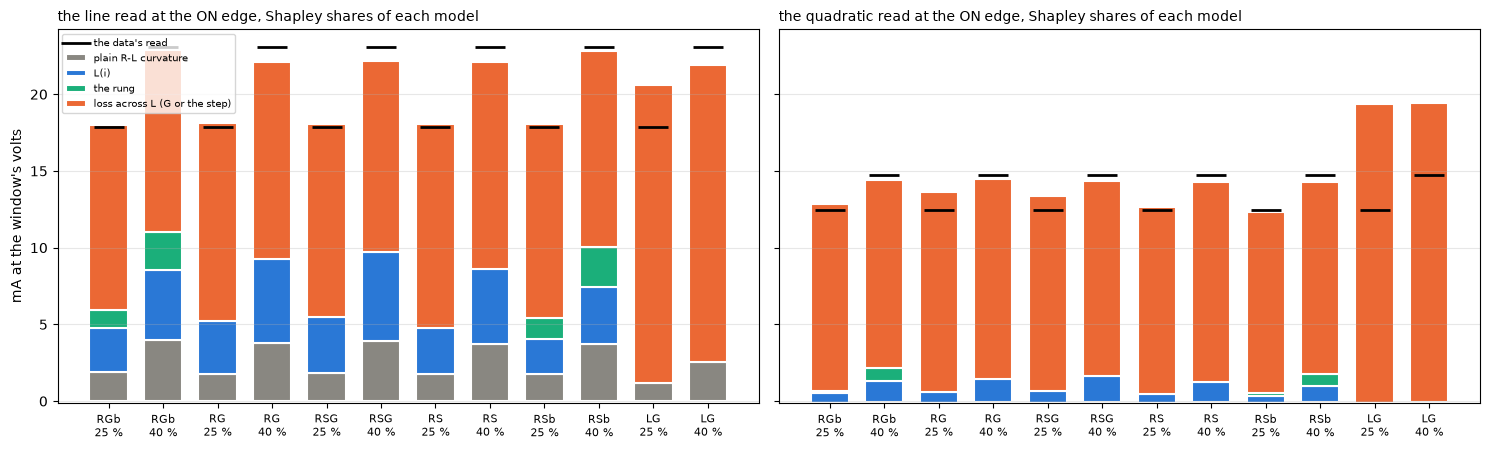

V_on over the four folds 4.94 to 4.96 V
teardown's reads of the same windows, for comparison: line 25 % 18.0 (17.5 to 19.7), 40 % 23.2 (22.1 to 26.0) mA, quadratic 25 % 12.8, 40 % 14.8 mA


In [11]:
OF = OFFSET.groupby(["key", "pct"]).mean(numeric_only=True)
cols = ["data_line", "data_line_lo", "data_line_hi", "model_line", "rl_line", "L(i)_line", "rung_line", "loss_line", "data_quad", "model_quad", "rl_quad",
        "L(i)_quad", "rung_quad", "loss_quad", "edge_ma"]
print(OF.reindex(columns=cols).round(2).T.to_string())
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
parts = [("rl", "plain R-L curvature", MUTED), ("L(i)", "L(i)", BLUE), ("rung", "the rung", GREEN), ("loss", "loss across L (G or the step)", ORANGE)]
keys = ["RGb", "RG", "RSG", "RS", "RSb", "LG"]
for a, read in zip(ax, ("line", "quad")):
    xt = []
    for j, (k, pct) in enumerate([(k, p) for k in keys for p in (25, 40)]):
        g = OF.loc[(k, pct)]
        bottom = 0.0
        for name, lab, c in parts:
            v = g.get(f"{name}_{read}", np.nan)
            if not np.isfinite(v):
                continue
            a.bar(j, v, 0.7, bottom=bottom, color=c, edgecolor="white", lw=1.5, label=lab if (j == 0 or (name == "rung" and k == "RGb" and pct == 25)) else None)
            bottom += v
        a.plot(j, g[f"data_{read}"], "k_", ms=22, mew=2, label="the data's read" if j == 0 else None)
        xt.append(f"{k}\n{pct} %")
    a.set_xticks(range(len(xt)), xt, fontsize=8); a.grid(alpha=0.3, axis="y")
    a.set_title(f"the {'line' if read == 'line' else 'quadratic'} read at the ON edge, Shapley shares of each model", loc="left", fontsize=10)
ax[0].set_ylabel("mA at the window's volts"); ax[0].legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()
print(f"V_on over the four folds {OFFSET['v_on'].min():.2f} to {OFFSET['v_on'].max():.2f} V")
TD_OFF = mm.TD["window_offset_ma"]["motor, fast-1 hole 11"]; TD_Q = mm.TD["window_offset_quad_ma"]["motor, fast-1 hole 11"]
print("teardown's reads of the same windows, for comparison: line", ", ".join(f"{k} {v['value']:.1f} ({v['lo']:.1f} to {v['hi']:.1f})" for k, v in TD_OFF.items()),
      "mA, quadratic", ", ".join(f"{k} {v['value']:.1f}" for k, v in TD_Q.items()), "mA")

On the data fold the line reads 17.9 and 23.1 mA at 25 and 40 %, against the teardown's 18.0 and 23.2 read burst by burst on the same windows, and the quadratic 12.5 and 14.7 against its 12.8 and 14.8. The motor model reads 18.0 and 22.9 by the line and 12.9 and 14.4 by the quadratic. Of its line read, 12.0 and 11.9 mA is the loss term, 1.9 and 4.0 the plain R-L curvature, 2.9 and 4.6 the current-dependent $L$ and 1.2 and 2.4 the rung. Under the other forms that pass, the loss share is 12.5 to 13.5 mA, the current-dependent $L$ 2.3 to 5.8 and the curvature 1.7 to 3.9. L||G puts 19.4 mA into the loss and reads 20.6 and 21.9 by the line, missing both duties. The model's own current at the edge, from ON+10 to ON+60 over a plain R-L, is 11.9 and 12.2 mA under Rayleigh + G + rung, 11.8 to 12.8 mA under the forms with a $G$, and 7.8 to 8.0 mA under the step forms, whose step is still building there.

So about 12 mA of the motor's offset at 4.95 V is a loss at the edge, the same at both duties, high confidence on that split. The rest of the line read, and its 29 % rise from 25 to 40 %, is the ramp's shape, the curvature, the current-dependent $L$ and the rung, which trade with the model, moderate confidence on how they split. The quadratic reads close to the loss alone, since it takes most of the curvature out.

## The reading term

On the spinning motor the current never stops, since slow decay brakes through the low side between windows. In steady continuous conduction the period mean of the voltage across the magnetizing inductance is zero. A loss across it carries $G v_L$ in the window, about $G(1 - D)V$ with $D$ the duty, and takes the same back between windows. The shunt sees only the window, and the crest sample sits in it. A meter in series sees both halves and averages the loss current to zero. The ramp's curvature, from $R/L$, the rung and $L(i)$, adds a smaller part that depends on the loop's resistance, so the meter's own burden enters bemf-coast's term. At 100 % nothing switches and both parts vanish. This section tests that picture.

### The coast as a meter

Capture-1 ran with no meter in the loop, so its mean current has to come from somewhere else. The coast after each spin decelerates the rotor by the drag it had at the cut, and $J\alpha/K_t$, the inertia times the deceleration over the torque constant, is that drag as a current, with speed-torque's $J$ and $K_t = K_e$ from bemf-coast. The coast reduction is bemf-coast's, unchanged. The speed at the cut is pinned by the spin's own count below 300 rev/s, and above it read from a line through three 5 ms windows. Where a meter was in the loop, the drag at the cut is set against the meter's mean. The figure draws every spin with a known mean, the drive's mean against the coast's drag by the 5 ms windows.

102 spins. capture-1's EMF slope against bemf-coast's own, max |difference| 0.0000 V/s over 60 spins; the board's current against its i_spin_a, max |difference| 0.000 mA
                         n    rev_s  mean_ma  drag_pin  drag_win  mean_over_pin  mean_over_win
run          level duty                                                                       
high-1       5.0   60    6  269.075   66.170    67.346    65.675          0.983          1.008
                   80    6  375.339   75.310    74.835    79.048          1.006          0.953
                   100   6  480.152   81.514    65.519    85.175          1.244          0.957
meter-1      5.0   30    6   98.297   49.582    49.716    46.291          0.997          1.071
             7.4   20    6   96.484   48.576    49.291    45.793          0.985          1.061
                   40    6  262.563   67.041    70.870    68.068          0.946          0.985
speed-torque 5.0   100   6  549.490  109.855    99.791   109.600      

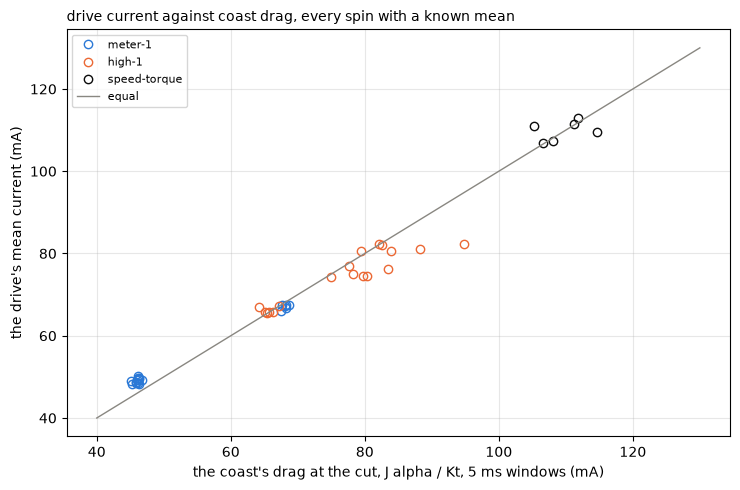

In [12]:
# bemf-coast's coast reduction on its capture-1, meter-1 and high-1 cycles and on speed-torque's run-ups, each cycle on its own process
CT = mm.coast_table(mm.run_parallel(mm.coast_jobs()))
ref = pd.DataFrame(mm.BEMF["cycles"])
c1 = CT[CT["run"] == "capture-1"].merge(ref[["k", "direction", "dedt_v_per_s", "i_spin_a"]].rename(columns={"direction": "dir", "dedt_v_per_s": "dedt_ref"}), on=["k", "dir"])
print(f"{len(CT)} spins. capture-1's EMF slope against bemf-coast's own, max |difference| {np.nanmax(np.abs(c1['dedt_v_per_s'] - c1['dedt_ref'])):.4f} V/s "
      f"over {c1['dedt_ref'].notna().sum()} spins; the board's current against its i_spin_a, max |difference| {np.nanmax(np.abs(c1['i_board_ma'] - c1['i_spin_a'] * 1e3)):.3f} mA")
SP, MO, C_SCALE, C_SD = mm.spin_points(CT)
known = CT[CT["run"].isin(["meter-1", "high-1", "speed-torque"])].copy()
known["mean_ma"] = np.where(known["run"] == "speed-torque", known["i_board_ma"], known["meter_ma"])
KN = known.groupby(["run", "level", "duty"]).agg(n=("dir", "size"), rev_s=("spin_rev_s", "mean"), mean_ma=("mean_ma", "mean"),
                                                 drag_pin=("drag_pin_ma", "mean"), drag_win=("drag_win_ma", "mean"))
KN["mean_over_pin"], KN["mean_over_win"] = KN["mean_ma"] / KN["drag_pin"], KN["mean_ma"] / KN["drag_win"]
print(KN.round(3).to_string())
R_M, R_M_SD = float(MO["meter_ohm"].mean()), float(MO["meter_ohm"].std())
R_MOT = mm.RR["r_term_median_ohm"]["value"]
n_met = int((CT["run"].isin(["meter-1", "high-1"]) & (CT["duty"] < 100)).sum())
print(f"capture-1's true mean = {C_SCALE:.4f} (sd {C_SD:.4f}) x its coast's pinned drag at the cut, the meter runs' own ratio over their {n_met} spins at partial duty")
print(MO.round(3).to_string())
print(f"the meter and its leads {R_M:.2f} ohm (sd {R_M_SD:.2f}), the motor's loop R {R_MOT:.3f} ohm (rest-resistance's median)")
fig, ax = plt.subplots(figsize=(7.5, 5))
for run, c in (("meter-1", BLUE), ("high-1", ORANGE), ("speed-torque", INK)):
    g = known[known["run"] == run]
    ax.plot(g["drag_win_ma"], g["mean_ma"], "o", color=c, ms=6, mfc="none", label=run)
xx = np.linspace(40, 130, 10); ax.plot(xx, xx, "-", color=MUTED, lw=1, label="equal")
ax.set_xlabel("the coast's drag at the cut, J alpha / Kt, 5 ms windows (mA)"); ax.set_ylabel("the drive's mean current (mA)")
ax.set_title("drive current against coast drag, every spin with a known mean", loc="left", fontsize=10); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The reduction reproduces bemf-coast's own EMF slope on all 60 of capture-1's spins and its board current to the printed difference. The drive's mean current equals the coast's drag at the cut at every point with a known mean, the ratio 0.95 to 1.07 by the 5 ms windows over 20 to 100 %, and 0.984 with an sd of 0.031 by the pinned read over the meter runs' 30 spins at partial duty. So capture-1's period mean is 0.984 times its coast's pinned drag, and capture-1's ten rungs measure the reading term with no meter in the loop. The pairing of each meter point with capture-1 at the same rail and duty puts the meter and its leads at 8.87 ohm, sd 0.62.

### The loss, refitted on the spinning motor

The locked motor's $L$ model is held, and only $G$ is refitted to the 18 spinning points with a known mean, capture-1's ten, meter-1's three, high-1's 60 and 80 %, and spinning-1's three. The $L$ model held is each form's fast-decay fit at hole 11, so the central model's own locked $G$ is that fit's 2.49 mS. The joint fast and slow fit's 2.29 mS is printed beside it. The model runs to steady state at each point, a back-EMF solved so the period mean of the series current equals the measured mean, and its crest sample, 31 ticks after the crest by sample-timing's instant, less that mean is the predicted term. The term is close to linear in $G$, so two runs per point, at 0 and 2 mS, give it for any $G$. The same is done for each other $L$ form. Each point's error is its own spread, the in-drive offset's half range, and for capture-1 the coast-to-meter scale. The figure draws the term per volt against $1 - D$, measured and modeled, on the left, and every point's residual under each $L$ form on the right.

216 steady states
Rayleigh + G + rung, rule 2 (its fast-decay G 2.49 mS): all 3.35 +/- 0.07 mS (chi2/dof 1.3); no meter 3.45 +/- 0.10 mS (chi2/dof 0.7); meter 3.27 +/- 0.12 mS (chi2/dof 1.8); 5 V 3.23 +/- 0.16 mS (chi2/dof 1.7); 7.4 V 3.40 +/- 0.08 mS (chi2/dof 0.9); rms 1.29 mA
Rayleigh + G, rule 2 (its fast-decay G 2.66 mS): all 3.65 +/- 0.06 mS (chi2/dof 0.8); no meter 3.73 +/- 0.10 mS (chi2/dof 0.4); meter 3.60 +/- 0.09 mS (chi2/dof 1.2); 5 V 3.59 +/- 0.12 mS (chi2/dof 1.1); 7.4 V 3.68 +/- 0.07 mS (chi2/dof 0.5); rms 0.99 mA
Rayleigh + step + G, rule 2 (its fast-decay G 1.77 mS): all 2.97 +/- 0.07 mS (chi2/dof 1.3); no meter 3.04 +/- 0.10 mS (chi2/dof 1.0); meter 2.92 +/- 0.10 mS (chi2/dof 1.7); 5 V 2.70 +/- 0.13 mS (chi2/dof 1.2); 7.4 V 3.08 +/- 0.07 mS (chi2/dof 0.6); rms 1.24 mA
L||G, rule 1 (its fast-decay G 4.00 mS): all 4.51 +/- 0.08 mS (chi2/dof 1.7); no meter 4.40 +/- 0.10 mS (chi2/dof 1.1); meter 4.57 +/- 0.12 mS (chi2/dof 2.4); 5 V 4.44 +/- 0.14 mS (chi2/dof 1.4); 7.4 V 4

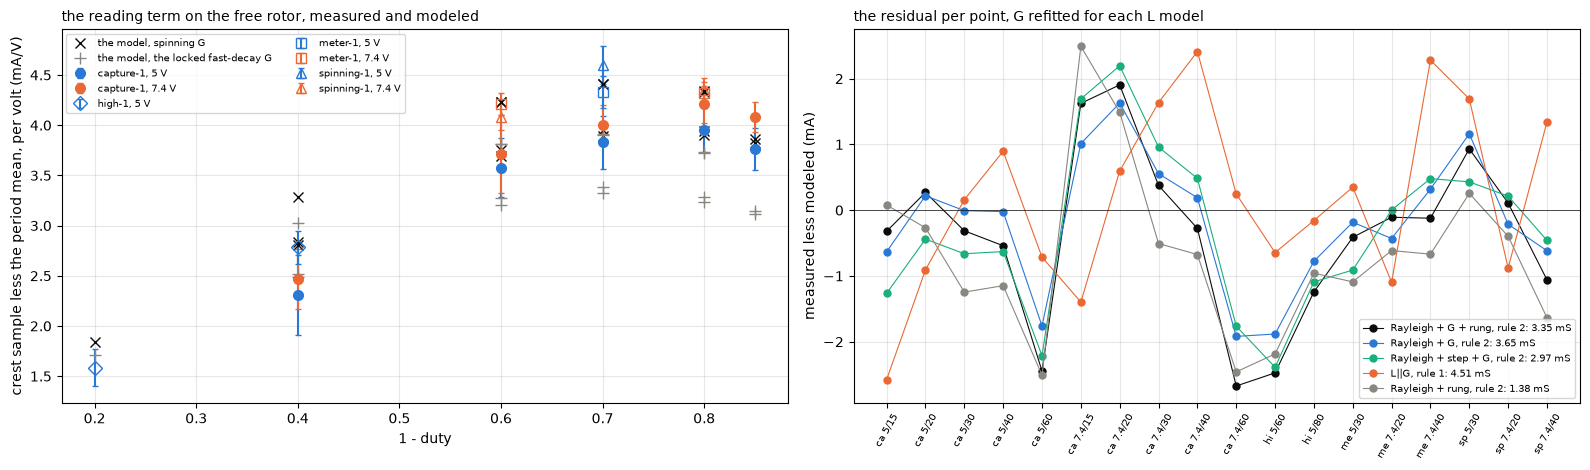

In [13]:
# the crest sample less the period mean at every spinning point under each L model: the motor's fast-decay fit with its own G and with
# G at 0 and 2 mS (the term is close to linear in G), and the joint fast + slow fit with its own G, each on its own process
PTS = SP[SP["duty"] < 100].reset_index(drop=True)
zero_ma = (mm.CS["drive_offset_counts"]["hi"] - mm.CS["drive_offset_counts"]["lo"]) / 2 / mm.CPA * 1e3
PTS["sig"] = np.sqrt(np.nan_to_num(PTS["mean_err"], nan=0.5) ** 2 + zero_ma ** 2
                     + np.where(PTS["run"] == "capture-1", (C_SD / C_SCALE * PTS["mean"]) ** 2 / 6, 0.0))
L_MODELS = [("RGb", 2), ("RG", 2), ("RSG", 2), ("LG", 1), ("Rb", 2)]
P_FAST = {km: dict(params_of(FAST[("motor", km[0])]["joint"]), kc=0.9, mem=km[1]) for km in L_MODELS}
P_JOINT = {n: v for (n, k), v in zip(JM["names"], JM["x"]) if n != "rs_slow"}
P_JOINT.update(mem=2)
rs_pt = lambda r: R_MOT + (R_M if r["loop"] == "meter" else 0.0)
jobs, tags = [], []
for _, r in PTS.iterrows():
    for km in L_MODELS:
        for gg in (0.0, 0.002):
            jobs.append((mm.steady_both, (dict(P_FAST[km], g=gg, rs=rs_pt(r)), r["duty"], r["v_on"], r["mean"]), {})); tags.append(("lin", km, gg, r.name))
    jobs.append((mm.steady_both, (dict(P_FAST[("RGb", 2)], rs=rs_pt(r)), r["duty"], r["v_on"], r["mean"]), {})); tags.append(("locked fast", None, None, r.name))
    jobs.append((mm.steady_both, (dict(P_JOINT, rs=rs_pt(r)), r["duty"], r["v_on"], r["mean"]), {})); tags.append(("locked joint", None, None, r.name))
OUT = dict(zip(tags, mm.run_parallel(jobs, chunksize=4)))
print(f"{len(jobs)} steady states")
GS = {}
for km in L_MODELS:
    a = np.array([OUT[("lin", km, 0.0, i)]["crest_less_mean"] for i in PTS.index])
    b = (np.array([OUT[("lin", km, 0.002, i)]["crest_less_mean"] for i in PTS.index]) - a) / 0.002   # term = a + b G
    res = {}
    for name, sel in (("all", np.ones(len(PTS), bool)), ("no meter", (PTS["run"] == "capture-1").to_numpy()), ("meter", (PTS["run"] != "capture-1").to_numpy()),
                      ("5 V", (PTS["level"] == 5.0).to_numpy()), ("7.4 V", (PTS["level"] == 7.4).to_numpy())):
        w = 1 / PTS["sig"].to_numpy()[sel] ** 2
        y = PTS["gap"].to_numpy()[sel] - a[sel]
        G = np.sum(w * b[sel] * y) / np.sum(w * b[sel] ** 2)
        chi2 = np.sum(w * (y - b[sel] * G) ** 2) / max(sel.sum() - 1, 1)
        res[name] = (G, np.sqrt(1 / np.sum(w * b[sel] ** 2) * max(chi2, 1)), chi2)
    GS[km] = dict(a=a, b=b, res=res, resid=PTS["gap"].to_numpy() - (a + b * res["all"][0]), g_locked=P_FAST[km].get("g", 0.0))
for km, r in GS.items():
    print(f"{mm.suite('iron')[km[0]].name}, rule {km[1]} (its fast-decay G {r['g_locked'] * 1e3:.2f} mS): "
          + "; ".join(f"{k} {v[0] * 1e3:.2f} +/- {v[1] * 1e3:.2f} mS (chi2/dof {v[2]:.1f})" for k, v in r["res"].items())
          + f"; rms {np.sqrt(np.mean(r['resid'] ** 2)):.2f} mA")
G_SPIN, G_SPIN_SE = GS[("RGb", 2)]["res"]["all"][:2]
G_MET = GS[("RGb", 2)]["res"]["meter"][0]
PTS["locked_fast"] = [OUT[("locked fast", None, None, i)]["crest_less_mean"] for i in PTS.index]
PTS["locked_joint"] = [OUT[("locked joint", None, None, i)]["crest_less_mean"] for i in PTS.index]
PTS["spin"] = GS[("RGb", 2)]["a"] + GS[("RGb", 2)]["b"] * G_SPIN
PTS["meter_only"] = GS[("RGb", 2)]["a"] + GS[("RGb", 2)]["b"] * G_MET
print(PTS[["run", "level", "duty", "v_on", "mean", "gap", "sig", "locked_fast", "locked_joint", "spin", "meter_only"]].round(2).to_string())
g_fast, g_joint = P_FAST[("RGb", 2)]["g"], P_JOINT["g"]
print(f"G_spin {G_SPIN * 1e3:.2f} +/- {G_SPIN_SE * 1e3:.2f} mS (the fit's own error) against the locked motor's fast-decay fit, the same L model, "
      f"{g_fast * 1e3:.2f} mS ({(G_SPIN / g_fast - 1) * 100:+.0f} %), and against the joint fast + slow fit {g_joint * 1e3:.2f} mS ({(G_SPIN / g_joint - 1) * 100:+.0f} %)")
print("measured less the locked fast-decay fit's term:", ", ".join(f"{r['run'][:2]}{r['level']:g}/{r['duty']} {r['gap'] - r['locked_fast']:+.1f}" for _, r in PTS.iterrows()), "mA")
print("measured less the locked joint fit's term:", ", ".join(f"{r['run'][:2]}{r['level']:g}/{r['duty']} {r['gap'] - r['locked_joint']:+.1f}" for _, r in PTS.iterrows()), "mA")
s1 = SP[SP["run"] == "spinning-1"]
print("spinning-1's window line, the locked fast-decay fit against bemf-coast's read: ON edge",
      ", ".join(f"{OUT[('locked fast', None, None, i)]['on_edge']:.1f} / {r['on_edge_meas']:.1f}" for i, r in PTS[PTS['run'] == 'spinning-1'].iterrows()),
      "mA, OFF edge", ", ".join(f"{OUT[('locked fast', None, None, i)]['off_edge']:.1f} / {r['off_edge_meas']:.1f}" for i, r in PTS[PTS['run'] == 'spinning-1'].iterrows()), "mA")
h100 = CT[(CT["run"] == "high-1") & (CT["duty"] == 100)]
D100 = h100["i_board_ma"] - h100["meter_ma"]                            # spin by spin, nothing switching
print(f"high-1 at 100 %, nothing switching: the board less the meter {D100.mean():+.2f} mA, sd {D100.std():.2f} over {len(D100)} spins")
RT = mm.BEMF["reading_term_by_duty"]
mp = PTS[PTS["run"].isin(["meter-1", "high-1"])].assign(per_v=lambda d: d["spin"] / d["v_on"])
print("bemf-coast's reading term with the meter in the loop, against the model with the spinning G at the meter points, mA/V:",
      ", ".join(f"{k} {v['value'] * 1e3:.2f} / {mp[mp['duty'] == int(k.split()[0])]['per_v'].mean() if int(k.split()[0]) < 100 else 0.0:.2f}" for k, v in RT.items()))

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
MK = {"capture-1": "o", "meter-1": "s", "high-1": "D", "spinning-1": "^"}
for run, g in PTS.groupby("run"):
    for lv, c in ((5.0, BLUE), (7.4, ORANGE)):
        h = g[g["level"] == lv]
        if len(h):
            ax[0].errorbar(1 - h["duty"] / 100, h["gap"] / h["v_on"], yerr=h["sig"] / h["v_on"], fmt=MK[run], color=c, mfc="none" if run != "capture-1" else c,
                           ms=7, capsize=2, label=f"{run}, {lv:g} V")
ax[0].plot(1 - PTS["duty"] / 100, PTS["spin"] / PTS["v_on"], "x", color=INK, ms=7, label="the model, spinning G")
ax[0].plot(1 - PTS["duty"] / 100, PTS["locked_fast"] / PTS["v_on"], "+", color=MUTED, ms=8, label="the model, the locked fast-decay G")
ax[0].set_xlabel("1 - duty"); ax[0].set_ylabel("crest sample less the period mean, per volt (mA/V)"); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=7, ncol=2)
ax[0].set_title("the reading term on the free rotor, measured and modeled", loc="left", fontsize=10)
for km, c in zip(L_MODELS, (INK, BLUE, GREEN, ORANGE, MUTED)):
    r = GS[km]
    ax[1].plot(np.arange(len(PTS)), r["resid"], "o-", lw=0.8, ms=5, color=c, label=f"{mm.suite('iron')[km[0]].name}, rule {km[1]}: {r['res']['all'][0] * 1e3:.2f} mS")
ax[1].axhline(0, color=INK, lw=0.5)
ax[1].set_xticks(range(len(PTS)), [f"{a[:2]} {b:g}/{c}" for a, b, c in zip(PTS["run"], PTS["level"], PTS["duty"])], rotation=60, fontsize=7)
ax[1].set_ylabel("measured less modeled (mA)"); ax[1].set_title("the residual per point, G refitted for each L model", loc="left", fontsize=10); ax[1].grid(alpha=0.3); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

With the locked motor's $L$ model and $G$ refitted, one $G$ draws all 18 spinning points at a chi2 per point of 1.3 and an rms of 1.3 mA, $G_\mathrm{spin}$ 3.35 $\pm$ 0.07 mS. Fitted to the meter points alone, 3.27 $\pm$ 0.12 mS, it predicts capture-1's meter-free points within -2.5 to +2.3 mA. Per rail it reads 3.23 $\pm$ 0.16 mS at 5.0 V and 3.40 $\pm$ 0.08 mS at 7.4 V, so the term follows the volts as the picture says. With the meter in the loop the model per volt reads 4.34, 4.41 and 4.23 mA/V at 20, 30 and 40 % against bemf-coast's 4.32, 4.33 and 4.21, and 3.29 and 1.84 at 60 and 80 % against 2.78 and 1.58. Spinning-1's window line, read as bemf-coast reads it, matches too, the locked fast-decay model reading the ON edge at 28.5, 31.3 and 28.4 mA against 30.6, 30.0 and 26.3, and the OFF edge at 102.4, 113.3 and 146.6 against 103.9, 113.3 and 141.9. The 60 % points sit 1.8 to 2.7 mA under every form but L||G at both rails, the one pattern left, either a fall slightly steeper than $1 - D$ or a coast scale that reads high at 60 %, where its spread is largest. Core loss under rectangular voltages is known to depend on the duty beyond the volt-seconds alone [5], so a one-$G$ law is the simplest form and not the only one. L||G misses them by less and the low-duty points by more.

The data therefore identify a loss that the crest sample reads inside the window and a meter averages away, falling with $1 - D$ to zero at 100 %, and predict it to about 1.5 mA by the board's current zero, high confidence. The zero itself moves the 7.4 V points by 3 to 4.6 mA, below. Where that loss sits is moderate at most. A $G$ across $L$ draws the points at 1.3 under Rayleigh + G + rung, 0.8 under Rayleigh + G, 1.3 with a step and 1.7 under L||G, with $G_\mathrm{spin}$ from 2.97 to 4.51 mS by form. The Rayleigh + rung form, whose locked fit carries its loss in the rung and no $G$, draws them at 1.5 with only 1.38 mS of $G$ added. So the points say the loss is there and how it scales, and not whether it sits across $L$ or in the rung.

By the board's zero the spinning motor reads more loss than the locked one. Against the locked fast-decay fit of the same $L$ model, 2.49 mS, $G_\mathrm{spin}$ is 34 % higher, and against the joint fast and slow fit, 2.29 mS, 46 % higher. The locked fast-decay fit's own $G$ under-predicts the term by 1.8 to 6.8 mA at 15 to 40 % and over-predicts the 60 and 80 % points by up to 1.2 mA, and the joint fit's by 1.1 to 6.8 mA and up to 1.9 mA. The 0.07 mS on $G_\mathrm{spin}$ is the fit's own error and not the gap's. The gap also carries the current's zero, the coast scale and the locked $G$'s own range, which the next cell takes in turn.

### The prediction

The crest sample less the period mean on the free motor in slow decay, with no meter in the loop on the left and the meter in series on the right, at the speed where the drive's volts meet the drag of capture-1's coasts, fitted as $a + b\sqrt{\omega}$. The central model is Rayleigh + G + rung with the spinning $G$, and the band is the other $L$ forms, each with its own spinning $G$, and the central $G$'s standard error. The thing to see is how the term holds at a few milliamps per volt to about 40 % and falls to zero at 100 %.

### The current's zero under the gap

The spinning points and the locked folds read their current over two different zeros. The crest sample on the spinning motor is read over the torque-off zero plus current-scale's in-drive offset, 5.3 counts, stage 1's zero for a driven bridge at 100 %, and spinning-1's three points take bemf-coast's read on the same zero. The locked folds read each burst over its own pre-step zero, the open or braked bridge. Bemf-coast found the open bridge's zero rising with the rail, about 6 counts over the torque-off zero at 5 V and 9 to 10.5 at 7.4 V, and left open which zero a switching drive sits on. The cell moves each spinning point's gap by its own difference of the two zeros, from bemf-coast's result, and refits $G$ with the same $L$ models and weights. Then it refits $G$ at the coast scale's spread by group, 0.946 to 1.006 in the table above, and sets the gap to the locked fit against $G_\mathrm{spin}$'s error, the coast scale and the locked $G$'s own range together.


In [14]:
# G_spin under the open bridge's zero in place of the in-drive offset, and under the coast scale's spread by group; the
# term stays a + b G at each point, only the measured gap moves
OZ_RUNG = pd.DataFrame(mm.BEMF["cycles"]).groupby(["level", "duty"])["open_zero_counts"].mean()


def open_shift_ma(r):
    # the board zero less the open bridge's zero at one point, mA: capture-1 per rung, meter-1 per point, spinning-1 its
    # between-window zero; high-1 has none in bemf-coast's result and takes the 5 V level's open zero
    pt = f"{r['level']:g} V {r['duty']} %"
    if r["run"] == "spinning-1":
        s_ = mm.BEMF["spinning_by_point"][pt]["slow"]
        return s_["crest_sample_board_zero_over_meter_ma"]["value"] - s_["crest_sample_over_meter_ma"]["value"]
    oz = {"capture-1": lambda: OZ_RUNG.loc[(r["level"], r["duty"])], "meter-1": lambda: mm.BEMF["meter_by_point"][pt]["open_zero_counts"]["value"],
          "high-1": lambda: mm.BEMF["open_zero_counts_by_level"][f"{r['level']:g} V"]["value"]}[r["run"]]()
    return (oz - mm.CS["drive_offset_counts"]["value"]) / mm.CPA * 1e3


def fit_g(y, sel, km=("RGb", 2)):
    # the cell above's weighted fit of term = a + b G to the gaps y over the points sel: G, its se, chi2/dof
    a, b, w = GS[km]["a"][sel], GS[km]["b"][sel], 1 / PTS["sig"].to_numpy()[sel] ** 2
    G = np.sum(w * b * (y[sel] - a)) / np.sum(w * b ** 2)
    chi2 = np.sum(w * (y[sel] - a - b * G) ** 2) / max(sel.sum() - 1, 1)
    return G, np.sqrt(max(chi2, 1) / np.sum(w * b ** 2)), chi2


PTS["open_shift"] = [open_shift_ma(r) for _, r in PTS.iterrows()]
GAP = {"board zero": PTS["gap"].to_numpy(), "open zero": (PTS["gap"] - PTS["open_shift"]).to_numpy()}
ALL, MET = np.ones(len(PTS), bool), (PTS["run"] != "capture-1").to_numpy()
print("the board zero less the open zero per point:", ", ".join(f"{r['run'][:2]}{r['level']:g}/{r['duty']} {r['open_shift']:.2f}" for _, r in PTS.iterrows()), "mA")
GZ = {(z, s): fit_g(y, sel) for z, y in GAP.items() for s, sel in (("all", ALL), ("meter", MET), ("5 V", (PTS["level"] == 5.0).to_numpy()),
                                                                     ("7.4 V", (PTS["level"] == 7.4).to_numpy()))}
for z in GAP:
    g_all = GZ[(z, "all")][0]
    print(f"{z}: G_spin {g_all * 1e3:.2f} +/- {GZ[(z, 'all')][1] * 1e3:.2f} mS (chi2/dof {GZ[(z, 'all')][2]:.1f}), the meter points alone "
          f"{GZ[(z, 'meter')][0] * 1e3:.2f} +/- {GZ[(z, 'meter')][1] * 1e3:.2f}, 5 V {GZ[(z, '5 V')][0] * 1e3:.2f}, 7.4 V {GZ[(z, '7.4 V')][0] * 1e3:.2f} mS; "
          f"over the locked fast-decay fit {(g_all / g_fast - 1) * 100:+.0f} %, over the joint fit {(g_all / g_joint - 1) * 100:+.0f} %; "
          "by L form " + ", ".join(f"{km[0]} {fit_g(GAP[z], ALL, km)[0] * 1e3:.2f}" for km in L_MODELS if km[0] != "Rb") + " mS")
c7 = ((PTS["run"] == "capture-1") & (PTS["level"] == 7.4) & (PTS["duty"] <= 30)).to_numpy()
a_, b_ = GS[("RGb", 2)]["a"], GS[("RGb", 2)]["b"]
print("capture-1 at 7.4 V up to 30 %, measured and modeled term by the board zero / by the open zero: " + ", ".join(
    f"{du} % {GAP['board zero'][i]:.1f} / {GAP['open zero'][i]:.1f} and {a_[i] + b_[i] * GZ[('board zero', 'all')][0]:.1f} / "
    f"{a_[i] + b_[i] * GZ[('open zero', 'all')][0]:.1f}" for i, du in zip(np.flatnonzero(c7), PTS.loc[c7, "duty"])) + " mA")
oz5 = (mm.BEMF["open_zero_counts_by_level"]["5 V"]["value"] - mm.CS["drive_offset_counts"]["value"]) / mm.CPA * 1e3
print(f"high-1 at 100 % on 5 V, nothing switching, the board less the meter: {D100.mean():+.2f} mA (se {D100.std() / np.sqrt(len(D100)):.2f}) "
      f"by the board zero, {D100.mean() - oz5:+.2f} by the 5 V open zero")
# the coast-to-meter scale by group: capture-1's mean is the coast's drag times the scale
SC_GROUPS = KN.loc[KN.index.get_level_values("duty") < 100, "mean_over_pin"]
c1m = (PTS["run"] == "capture-1").to_numpy()
G_SCALE = {s: fit_g(GAP["board zero"] - np.where(c1m, PTS["mean"] * (s / C_SCALE - 1), 0.0), ALL)[0] for s in (SC_GROUPS.min(), SC_GROUPS.max())}
print("G_spin at the coast scale's group extremes:", ", ".join(f"{s:.3f} {g * 1e3:.2f} mS" for s, g in G_SCALE.items()), f"against {C_SCALE:.3f} {G_SPIN * 1e3:.2f}")
g_lo_lock, g_hi_lock = (PT[(PT["set"] == "motor") & (PT["param"] == "g")][c].iloc[0] * 1e-3 for c in ("lo", "hi"))
sys_g = np.hypot(G_SPIN_SE, max(abs(g - G_SPIN) for g in G_SCALE.values()))
print(f"the gap to the locked fast-decay fit, {(G_SPIN - g_fast) * 1e3:.2f} mS, over G_spin's se and the coast scale together {sys_g * 1e3:.2f} mS: "
      f"{(G_SPIN - g_fast) / sys_g:.1f} sigma; over those and half the locked G's own range {g_lo_lock * 1e3:.2f} to {g_hi_lock * 1e3:.2f} mS: "
      f"{(G_SPIN - g_fast) / np.hypot(sys_g, (g_hi_lock - g_lo_lock) / 2):.1f} sigma; "
      "G_spin over the locked fast-decay G by form " + ", ".join(f"{km[0]} {(GS[km]['res']['all'][0] / GS[km]['g_locked'] - 1) * 100:+.0f} %"
                                                               for km in L_MODELS if GS[km]["g_locked"] > 0))


the board zero less the open zero per point: ca5/15 0.55, ca5/20 0.69, ca5/30 0.79, ca5/40 0.66, ca5/60 0.75, ca7.4/15 3.19, ca7.4/20 3.47, ca7.4/30 3.59, ca7.4/40 3.19, ca7.4/60 3.41, hi5/60 0.69, hi5/80 0.69, me5/30 1.14, me7.4/20 3.56, me7.4/40 3.64, sp5/30 1.09, sp7.4/20 4.62, sp7.4/40 4.62 mA
board zero: G_spin 3.35 +/- 0.07 mS (chi2/dof 1.3), the meter points alone 3.27 +/- 0.12, 5 V 3.23, 7.4 V 3.40 mS; over the locked fast-decay fit +34 %, over the joint fit +46 %; by L form RGb 3.35, RG 3.65, RSG 2.97, LG 4.51 mS
open zero: G_spin 2.69 +/- 0.11 mS (chi2/dof 3.1), the meter points alone 2.46 +/- 0.16, 5 V 2.94, 7.4 V 2.59 mS; over the locked fast-decay fit +8 %, over the joint fit +18 %; by L form RGb 2.69, RG 3.03, RSG 2.35, LG 3.89 mS
capture-1 at 7.4 V up to 30 %, measured and modeled term by the board zero / by the open zero: 15 % 29.8 / 26.6 and 28.2 / 24.3, 20 % 30.7 / 27.2 and 28.8 / 25.1, 30 % 29.2 / 25.6 and 28.8 / 25.7 mA
high-1 at 100 % on 5 V, nothing switching, the

The two zeros part by 0.55 to 1.14 mA at 5 V and 3.19 to 4.62 mA at 7.4 V. By the open bridge's zero one $G$ draws all 18 points at 2.69 $\pm$ 0.11 mS, a chi2 per point of 3.1, and the meter points alone at 2.46 $\pm$ 0.16 mS, against the locked fast-decay fit's 2.49. Capture-1's term at 7.4 V and 15 to 30 % falls from 29.2 to 30.7 mA measured and 28.2 to 28.8 modeled to 25.6 to 27.2 measured and 24.3 to 25.7 modeled, so the no-meter grid's 29 mA at 7.4 V up to 30 % would read about 25 to 26 mA. The 5 V term moves by under 1.2 mA. So the gap to the locked $G$ sits in the zero. By the board's zero it is 0.86 mS, by the open zero 0.20 mS over every point and none on the meter points alone.

Two things lean to the board's zero, neither at the rail where the zeros part most. High-1 at 100 % on 5 V, where nothing switches, reads the board 0.13 mA under the meter by the board's zero, se 0.20, and 0.82 mA under it by the open zero, so at full duty on 5 V the board's zero is the better one by about 0.7 mA. And one $G$ draws the points at 1.3 per point by the board's zero against 3.1 by the open zero, where 5 V and 7.4 V read 2.94 and 2.59 mS against 3.23 and 3.40, so by the open zero the term follows the volts less cleanly. The dropout rows, read in the brush drop's section below, settle it at 7.4 V. A period with the brush path open carries no winding current while the bridge drives, so its crest sample reads the zero a driven bridge sits on directly, on the motor at the rail of each run, and it reads the open bridge's zero at both rails, 9.0 counts at 7.4 V against the open zero's 9.09 and the board's 5.26. The two leans are at 5 V or pool both rails, where the zeros part by under a count, and the 5 V one stays as a tension of about 0.7 mA. A DMM in series at 7.4 V, the board's crest sample against the meter at 100 % and at the meter points' duties, is the confirmation.

By the board's zero the gap also carries more than the fit's 0.07 mS. The coast scale's spread by group moves $G_\mathrm{spin}$ from 3.22 to 3.57 mS, and the locked $G$'s own range runs 2.14 to 2.69 mS. With the coast scale carried the gap is 3.7 sigma, and with the locked range's half-width as well 2.4 sigma. Its size depends on the form, $G_\mathrm{spin}$ over its locked fast-decay $G$ from +13 % under L||G to +68 % with a step. So the spinning motor's extra loss is low to moderate confidence by the board's zero and absent from the meter points by the open zero and by the dropout rows' zero, which reads 2.79 mS over every point and 2.62 mS on the meter points. If it is real, its cause is open. The locked seat is one rotor angle, and the loss of small loops is known to grow with the bias they ride on [4], so a seat at one bias need not read the loss of a rotor that sweeps through every bias. Hole 11 is one of the three holes that read low in $L$ in inductance, and the coil in the can moved its $G$ by about two times between sittings. Rotation could also add loss in the rotating teeth. One hole does not separate them. The grid, `g_spin_ms` and the terms by rail are still published by the board's zero in this results file, with `g_spin_open_zero_ms` and the dropout zero, `drive_zero_counts_by_rail`, beside them, so a later stage that reads the open zero has both. `g_spin_ms`'s bounds carry the $L$ forms and the coast scale, 2.84 to 4.73 mS.

418 steady states; drag curve 20.4 + 1.353 sqrt(w) mA

crest sample less the period mean, no meter, mA (the model range in brackets):
  3.7 V: 10 % 13.6 (13.3-16.4), 15 % 14.0 (13.8-15.9), 20 % 14.2 (14.0-15.7), 30 % 14.2 (13.7-15.3), 40 % 13.4 (12.3-14.2), 50 % 12.1 (10.7-12.6), 60 % 10.3 (8.9-10.5), 70 % 8.1 (7.0-8.2), 80 % 5.7 (4.9-5.7), 90 % 3.1 (2.8-3.3)
  5 V: 10 % 18.4 (18.1-22.1), 15 % 19.0 (18.7-21.5), 20 % 19.4 (19.1-20.7), 30 % 19.4 (18.6-20.0), 40 % 18.4 (16.6-18.7), 50 % 16.5 (14.4-16.7), 60 % 14.0 (12.0-14.1), 70 % 10.9 (9.4-11.0), 80 % 7.6 (6.6-7.7), 90 % 4.2 (3.7-4.2)
  7.4 V: 10 % 27.3 (26.9-32.7), 15 % 28.3 (27.9-31.7), 20 % 29.0 (28.4-30.6), 30 % 29.1 (27.4-29.5), 40 % 27.6 (24.5-27.9), 50 % 24.8 (21.3-25.0), 60 % 20.9 (17.7-21.1), 70 % 16.3 (13.8-16.4), 80 % 11.3 (9.7-11.4), 90 % 6.1 (5.4-6.2)
  8.4 V: 10 % 31.1 (30.5-37.1), 15 % 32.3 (31.4-36.0), 20 % 33.1 (32.0-34.7), 30 % 33.2 (31.0-33.6), 40 % 31.6 (27.8-31.9), 50 % 28.3 (24.1-28.6), 60 % 23.8 (20.0-24.1), 70 % 

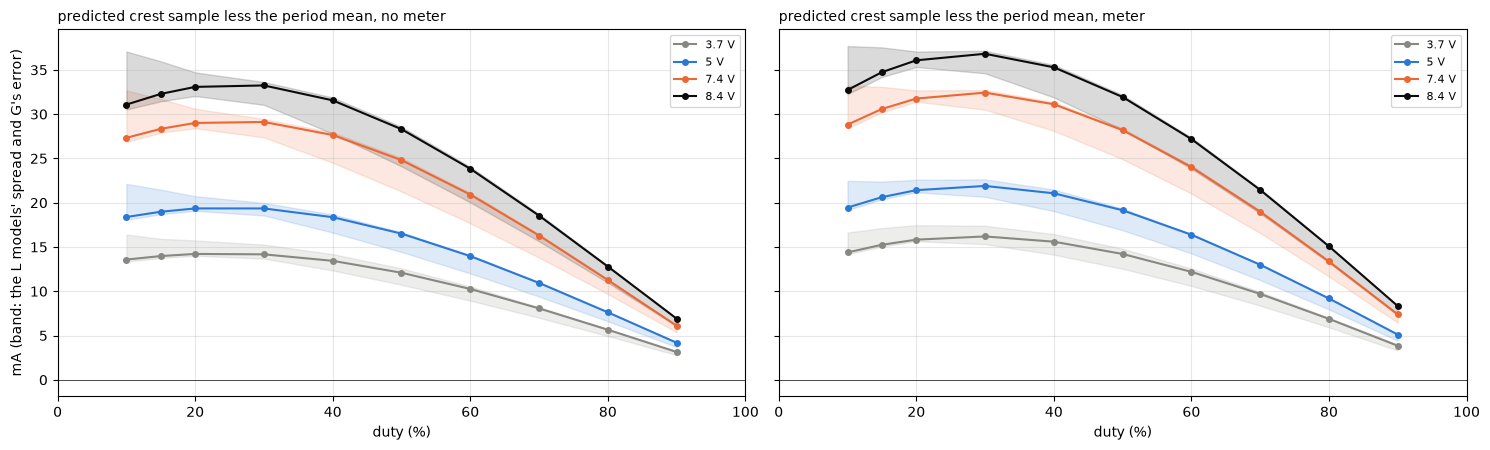

In [15]:
# the prediction: the crest sample less the period mean on the free motor in slow decay, by duty and rail, with no meter in the loop
# and with the meter in series, at the speed where the drive meets capture-1's coast drag, a + b sqrt(w)
c1 = CT[CT["run"] == "capture-1"]
w = 2 * np.pi * c1["spin_rev_s"].to_numpy()
y = C_SCALE * np.where(c1["spin_rev_s"] < 300, c1["drag_pin_ma"], c1["drag_win_ma"])
ok = np.isfinite(w) & np.isfinite(y)
CD = np.linalg.lstsq(np.c_[np.ones(ok.sum()), np.sqrt(w[ok])], y[ok], rcond=None)[0]
drag = lambda om: CD[0] + CD[1] * np.sqrt(max(om, 0.0))
GRID_MODELS = [("RGb", 2), ("RG", 2), ("LG", 1), ("RSG", 2)]
cells, jobs, tags = [], [], []
for loop, rext in (("no meter", 0.0), ("meter", R_M)):
    for v in (3.7, 5.0, 7.4, 8.4):
        for du in (10, 15, 20, 30, 40, 50, 60, 70, 80, 90):
            sh = mm.share(du)
            lo_, hi_ = 0.0, sh * v / mm.KE
            for _ in range(60):                                         # the speed where the drive's volts meet the drag's current
                om = 0.5 * (lo_ + hi_)
                if sh * v - mm.KE * om - drag(om) * 1e-3 * (R_MOT + rext) > 0:
                    lo_ = om
                else:
                    hi_ = om
            cell = dict(loop=loop, rail=v, duty=du, rev_s=om / 2 / np.pi, mean_ma=drag(om))
            cells.append(cell)
            for km in GRID_MODELS:
                p = dict(P_FAST[km], g=GS[km]["res"]["all"][0], rs=R_MOT + rext)
                jobs.append((mm.steady_both, (p, du, v, cell["mean_ma"]), {})); tags.append((len(cells) - 1, km[0]))
            p = dict(P_FAST[("RGb", 2)], g=G_SPIN + G_SPIN_SE, rs=R_MOT + rext)
            jobs.append((mm.steady_both, (p, du, v, cell["mean_ma"]), {})); tags.append((len(cells) - 1, "RGb_gse"))
SENS = [(v, du, im) for v, du in ((5.0, 30), (7.4, 30), (5.0, 60)) for im in (30, 50, 70, 100, 150, 200)]
for v, du, im in SENS:
    jobs.append((mm.steady_both, (dict(P_FAST[("RGb", 2)], g=G_SPIN, rs=R_MOT), du, v, im), {})); tags.append(("sens", (v, du, im)))
res = dict(zip(tags, mm.run_parallel(jobs, chunksize=4)))
print(f"{len(jobs)} steady states; drag curve {CD[0]:.1f} + {CD[1]:.3f} sqrt(w) mA")
for i, cell in enumerate(cells):
    for km in GRID_MODELS:
        cell[km[0]] = res[(i, km[0])]["crest_less_mean"]
    cell["gse"] = res[(i, "RGb_gse")]["crest_less_mean"] - cell["RGb"]
    vals = [cell[km[0]] for km in GRID_MODELS]
    cell["lo"], cell["hi"] = min(vals) - abs(cell["gse"]), max(vals) + abs(cell["gse"])
GRID = pd.DataFrame(cells)
for loop in ("no meter", "meter"):
    t = GRID[GRID["loop"] == loop]
    print(f"\ncrest sample less the period mean, {loop}, mA (the model range in brackets):")
    for v, g in t.groupby("rail"):
        print(f"  {v:g} V: " + ", ".join(f"{r['duty']} % {r['RGb']:.1f} ({r['lo']:.1f}-{r['hi']:.1f})" for _, r in g.iterrows()))
    g = t[t["rail"] == 5.0]
    print("  5 V speed and mean: " + ", ".join(f"{r['duty']} % {r['rev_s']:.0f} rev/s {r['mean_ma']:.0f} mA" for _, r in g.iterrows()))
per_v = GRID[GRID["loop"] == "no meter"].assign(per_v=lambda d: d["RGb"] / d["rail"])
nm, wm = GRID[GRID["loop"] == "no meter"].reset_index(drop=True), GRID[GRID["loop"] == "meter"].reset_index(drop=True)
add = wm["RGb"] - nm["RGb"]
print(f"the meter adds {add.min():.1f} to {add.max():.1f} mA ({nm.loc[add.idxmin(), 'rail']:g} V {nm.loc[add.idxmin(), 'duty']} % to "
      f"{nm.loc[add.idxmax(), 'rail']:g} V {nm.loc[add.idxmax(), 'duty']} %); the band's width {(GRID['hi'] - GRID['lo']).min():.1f} to {(GRID['hi'] - GRID['lo']).max():.1f} mA")
print("no meter, per volt at 10 to 30 %:", f"{per_v[per_v['duty'] <= 30]['per_v'].min():.2f} to {per_v[per_v['duty'] <= 30]['per_v'].max():.2f} mA/V")
print("the term against the mean current at fixed duty and rail:", "; ".join(
    f"{v:g} V {du} %: " + ", ".join(f"{im} mA {res[('sens', (v, du, im))]['crest_less_mean']:.1f}" for (vv, dd, im) in SENS if (vv, dd) == (v, du))
    for v, du in ((5.0, 30), (7.4, 30), (5.0, 60))))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for a, loop in zip(ax, ("no meter", "meter")):
    for v, c in ((3.7, MUTED), (5.0, BLUE), (7.4, ORANGE), (8.4, INK)):
        g = GRID[(GRID["loop"] == loop) & (GRID["rail"] == v)]
        a.fill_between(g["duty"], g["lo"], g["hi"], color=c, alpha=0.15)
        a.plot(g["duty"], g["RGb"], "-o", ms=4, color=c, label=f"{v:g} V")
    a.axhline(0, color=INK, lw=0.5); a.set_xlabel("duty (%)"); a.grid(alpha=0.3); a.legend(fontsize=8); a.set_xlim(0, 100)
    a.set_title(f"predicted crest sample less the period mean, {loop}", loc="left", fontsize=10)
ax[0].set_ylabel("mA (band: the L models' spread and G's error)")
plt.tight_layout(); plt.show()

With no meter, the term per volt of the rail is nearly the same on every rail at a given duty, 3.7 to 4.0 mA/V at 10 to 30 % from 3.7 to 8.4 V, flat to 40 %, then falling close to linearly to zero at 100 %. The meter in the loop adds 0.7 to 3.7 mA through its resistance, most at 30 to 40 % on the higher rails. At fixed duty and rail the term moves with the mean current by about 0.5 mA per 100 mA, so speed enters only weakly, through the current. The band is 0.5 to 6.6 mA wide, widest at low duty and high rail, where the forms part most. The grid is on the board's zero. By the open bridge's zero the 7.4 V cells up to 30 % read about 3 to 4 mA lower and the 5 V cells under 1 mA lower, and the band does not carry that.

## The 100 % excess

Speed-torque's run-ups at 100 % settled about 20 mA over no-load-current's term-out curve. At 100 % nothing switches, so the window model's term is zero there. The figure sets capture-1's coast drag, which carries no reading term, its crest samples, which do, speed-torque's drive and coast at 100 %, high-1's meter, and no-load-current's term-out curves against speed.

capture-1's coast drag, a + b ln w: rms 3.17 mA over 60 spins (64 to 510 rev/s), at speed-torque's 549 rev/s 95.6 mA
capture-1's coast drag, a + b sqrt w: rms 2.35 mA over 60 spins (64 to 510 rev/s), at speed-torque's 549 rev/s 101.6 mA
capture-1's coast drag, a + b w: rms 3.13 mA over 60 spins (64 to 510 rev/s), at speed-torque's 549 rev/s 107.1 mA
capture-1's coast drag, a + b w + c w^2: rms 2.36 mA over 60 spins (64 to 510 rev/s), at speed-torque's 549 rev/s 99.7 mA
speed-torque at 100 %: 549 rev/s (540 to 558), the board 109.9 mA (sd 2.3 over 6), the coast's drag at the cut by 5 ms windows 109.6 mA (sd 3.6, se 1.5)
no-load-current's term-out curve there: 5 V 89.8 mA, 7.4 V 94.2 mA
capture-1 per rung, the coast's true mean less i_spin_meter_a: 5 V 15 % +2.8, 5 V 20 % +1.8, 5 V 30 % +2.4, 5 V 40 % +3.1, 5 V 60 % +2.3, 7.4 V 15 % +1.8, 7.4 V 20 % +0.8, 7.4 V 30 % +2.3, 7.4 V 40 % +3.6, 7.4 V 60 % +2.3 mA, mean +2.3
capture-1's coast drag at 470 to 490 rev/s: 100.5 to 102.2 mA over 3 s

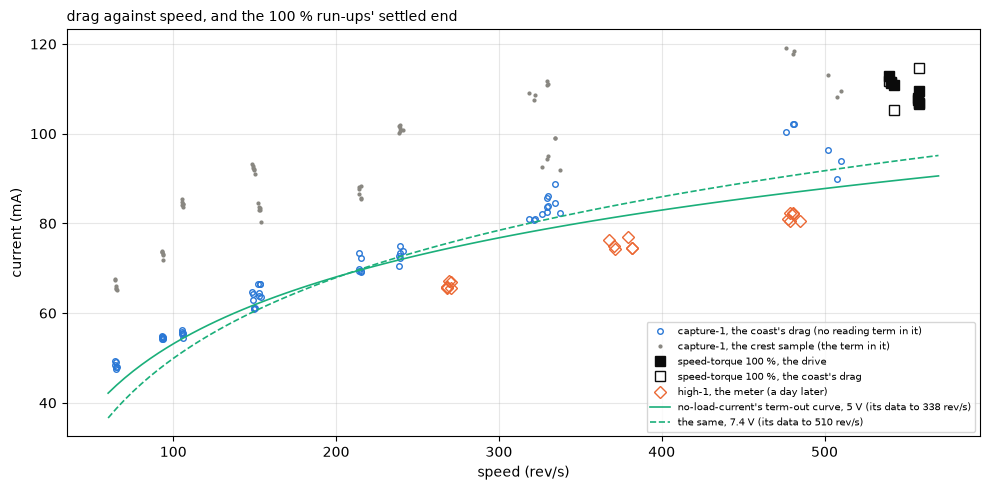

In [16]:
st = CT[CT["run"] == "speed-torque"]
w_st = 2 * np.pi * st["spin_rev_s"].mean()
c1 = CT[CT["run"] == "capture-1"].copy()
c1["drag"] = np.where(c1["spin_rev_s"] < 300, c1["drag_pin_ma"], c1["drag_win_ma"])   # pinned below 300 rev/s, the 5 ms windows above
ok = c1["drag"].notna() & c1["spin_rev_s"].notna()
w = 2 * np.pi * c1.loc[ok, "spin_rev_s"].to_numpy(); y = c1.loc[ok, "drag"].to_numpy()
FORMS = {"a + b ln w": lambda x: np.c_[np.ones_like(x), np.log(x / (2 * np.pi * 100))], "a + b sqrt w": lambda x: np.c_[np.ones_like(x), np.sqrt(x)],
         "a + b w": lambda x: np.c_[np.ones_like(x), x], "a + b w + c w^2": lambda x: np.c_[np.ones_like(x), x, x ** 2]}
AT_ST = {}
for name, X in FORMS.items():
    c, *_ = np.linalg.lstsq(X(w), y, rcond=None)
    AT_ST[name] = float((X(np.array([w_st])) @ c)[0])
    print(f"capture-1's coast drag, {name}: rms {np.sqrt(np.mean((y - X(w) @ c) ** 2)):.2f} mA over {len(y)} spins "
          f"({c1.loc[ok, 'spin_rev_s'].min():.0f} to {c1.loc[ok, 'spin_rev_s'].max():.0f} rev/s), at speed-torque's {w_st / 2 / np.pi:.0f} rev/s {AT_ST[name]:.1f} mA")
print(f"speed-torque at 100 %: {st['spin_rev_s'].mean():.0f} rev/s ({st['spin_rev_s'].min():.0f} to {st['spin_rev_s'].max():.0f}), the board {st['i_board_ma'].mean():.1f} mA "
      f"(sd {st['i_board_ma'].std():.1f} over {len(st)}), the coast's drag at the cut by 5 ms windows {st['drag_win_ma'].mean():.1f} mA "
      f"(sd {st['drag_win_ma'].std():.1f}, se {st['drag_win_ma'].std() / np.sqrt(len(st)):.1f})")
print(f"no-load-current's term-out curve there: 5 V {mm.nlc_curve(st['spin_rev_s'].mean()):.1f} mA, 7.4 V {mm.nlc_curve(st['spin_rev_s'].mean(), '7.4 V'):.1f} mA")
cap = SP[SP["run"] == "capture-1"].copy()
ref_m = pd.DataFrame(mm.BEMF["cycles"]).groupby(["level", "duty"])["i_spin_meter_a"].mean() * 1e3
cap["i_spin_meter"] = [ref_m.loc[(r.level, r.duty)] for r in cap.itertuples()]
cap["coast_less_termout"] = cap["mean"] - cap["i_spin_meter"]
print("capture-1 per rung, the coast's true mean less i_spin_meter_a:", ", ".join(f"{r.level:g} V {r.duty} % {r.coast_less_termout:+.1f}" for r in cap.itertuples()),
      f"mA, mean {cap['coast_less_termout'].mean():+.1f}")
hi1 = CT[CT["run"] == "high-1"]
near = c1[(c1["spin_rev_s"] >= 470) & (c1["spin_rev_s"] <= 490)]["drag"]
print(f"capture-1's coast drag at 470 to 490 rev/s: {near.min():.1f} to {near.max():.1f} mA over {len(near)} spins, against high-1's meter at 100 % "
      f"{hi1[hi1['duty'] == 100]['meter_ma'].min():.1f} to {hi1[hi1['duty'] == 100]['meter_ma'].max():.1f} mA at "
      f"{hi1[hi1['duty'] == 100]['spin_rev_s'].min():.0f} to {hi1[hi1['duty'] == 100]['spin_rev_s'].max():.0f} rev/s")
h100 = hi1[hi1["duty"] == 100]
print(f"high-1 at 100 %, a day later: {h100['spin_rev_s'].mean():.0f} rev/s, the meter {h100['meter_ma'].mean():.1f} mA, the coast {h100['drag_win_ma'].mean():.1f} mA "
      f"(sd {h100['drag_win_ma'].std():.1f}, se {h100['drag_win_ma'].std() / np.sqrt(len(h100)):.1f})")
print(f"speed-torque's settled current {mm.SPT['no_load_current_a']['value'] * 1e3:.1f} mA ({mm.SPT['no_load_current_a']['lo'] * 1e3:.1f} to "
      f"{mm.SPT['no_load_current_a']['hi'] * 1e3:.1f}) at {mm.SPT['no_load_speed_rev_s']['value']:.0f} rev/s")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(c1["spin_rev_s"], c1["drag"], "o", ms=4, color=BLUE, mfc="none", label="capture-1, the coast's drag (no reading term in it)")
ax.plot(c1["spin_rev_s"], c1["i_board_ma"], ".", ms=4, color=MUTED, label="capture-1, the crest sample (the term in it)")
ax.plot(st["spin_rev_s"], st["i_board_ma"], "s", ms=7, color=INK, label="speed-torque 100 %, the drive")
ax.plot(st["spin_rev_s"], st["drag_win_ma"], "s", ms=7, color=INK, mfc="none", label="speed-torque 100 %, the coast's drag")
ax.plot(hi1["spin_rev_s"], hi1["meter_ma"], "D", ms=6, color=ORANGE, mfc="none", label="high-1, the meter (a day later)")
ws = np.linspace(60, 570, 100)
ax.plot(ws, mm.nlc_curve(ws), "-", color=GREEN, lw=1.2, label="no-load-current's term-out curve, 5 V (its data to 338 rev/s)")
ax.plot(ws, mm.nlc_curve(ws, "7.4 V"), "--", color=GREEN, lw=1.2, label="the same, 7.4 V (its data to 510 rev/s)")
ax.set_xlabel("speed (rev/s)"); ax.set_ylabel("current (mA)"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
ax.set_title("drag against speed, and the 100 % run-ups' settled end", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

At speed-torque's settled end, 549 rev/s, the drive reads 109.9 mA, sd 2.3 over six run-ups, and the coast's drag at the cut 109.6 mA, se 1.5. High-1 reads the board 0.13 mA under the meter at 100 %, sd 0.49 over six spins. The drive's mean equals the coast's drag at every point with a known mean, so a current the drive carries that does not turn the rotor would have to be under about 3 mA. So the +20 mA is drag the rotor has at 549 rev/s, high confidence. No-load-current's term-out curve reads 89.8 mA there at 5.0 V and 94.2 mA at 7.4 V, and three things put it low, moderate confidence on the split. Its 5.0 V data stop at 338 rev/s, and its log form flattens past them. Capture-1's own coast drag, which carries no term, extrapolates to 95.6 to 107.1 mA by form, 99.7 and 101.6 mA by the two that fit best. Its spin currents take bemf-coast's meter-run term out, which reads 0.8 to 3.6 mA low, mean 2.3, against capture-1's coast. And the rest, about 4 to 8 mA, is drag that moved between sittings and with the run's age. High-1, a day after capture-1, reads its meter at 80.6 to 82.4 mA at 477 to 485 rev/s, where capture-1's coast drag reads 100.5 to 102.2 mA, and no-load-current's early-run excess is 4 mA at 200 to 300 ms. At the meter runs' own speeds the drag is a function of speed alone over 40 to 100 % duty, meter-1 at 7.4 V 40 % reading 67.0 mA at 263 rev/s and high-1 at 5.0 V 60 % 66.2 mA at 269 rev/s, so the partial-duty curve is not wrong in kind.

## The motor from one coil

The coil runs read one coil, and the motor is three coils in a delta, one across the terminals and two in series beside it. With the coil states measured here, bare and in the can at two sittings, one coil's $R$ by hand less the lead zero, and a mutual inductance $M = -k\sqrt{L_iL_j}/2$ between every pair, the delta's small-signal terminal impedance gives its $L$ at high and low frequency and the loss it carries, each coil's $G$ times the square of its share of the terminal volts. Every combination of the three states runs over a coupling $k$ from 0 to 0.95, where $k = 1$ would be three teeth whose fluxes sum to zero. A rung fitted to each case's impedance over 1 to 100 kHz says whether the delta itself makes the motor's rung. The figure draws the delta's $L$ and loss against $k$ with the motor's values as bands, and each case's rung against the motor's.

one coil 6.010 ohm; coil states L0 bare 0.562, can, levels sitting 0.341, can, coil-can-1 0.651 mH, G bare 0.48, can, levels sitting 1.46, can, coil-can-1 3.22 mS
the delta over every combination and k: L_hf 0.228 to 0.640 mH, G_term 0.72 to 5.18 mS, R_dc 4.007 to 4.007 ohm
cases with a fitted rung Lb of 0.15 to 0.30 mH: 4 of 360, Rb 15.9 to 38.0 ohm, tau 5 to 10 us, k 0.90 to 0.95
over every case: rung Lb 0.0000 to 0.240 mH, Rb 0.00 to 38.03 ohm, tau 5 to 103 us
equal coils: bare: G_term / G_coil 1.50, can, coil-can-1: G_term / G_coil 1.50, can, levels sitting: G_term / G_coil 1.50


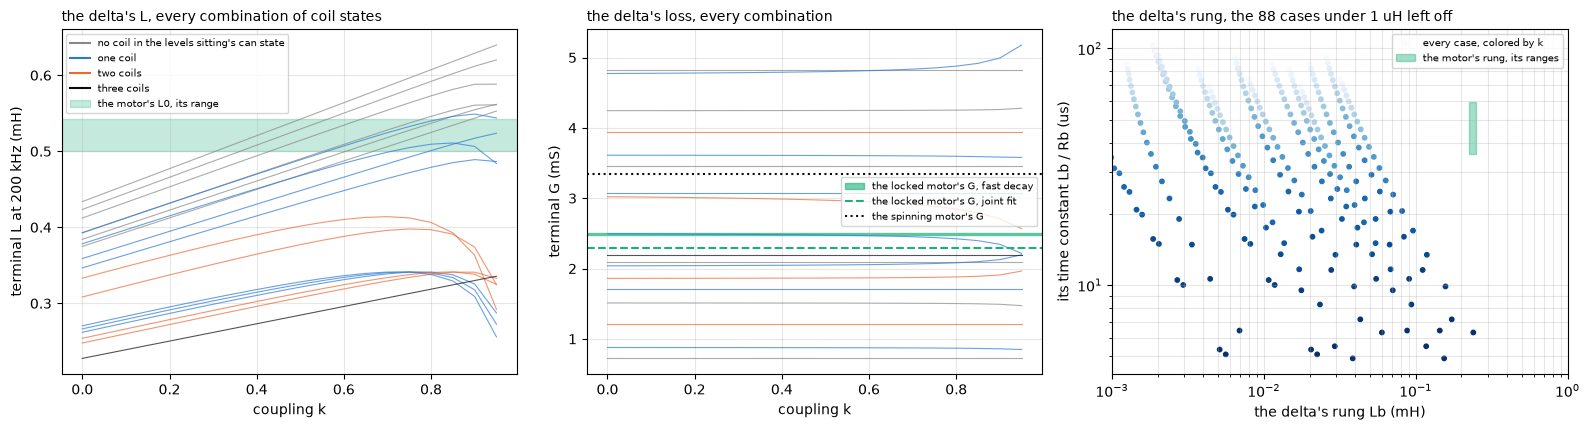

In [17]:
R_COIL = float(mm.hand("remaining pad pair ohm")[0]) - mm.LEAD_ZERO   # one coil alone, by hand, less the lead zero
cc = FAST[("coil-can-1", "LGs")]["joint"]
STATES = {"bare": mm.value(FAST[("bare", "RG")]["joint"], "l0"), "can, levels sitting": mm.value(FAST[("can", "QG")]["joint"], "l0"),
          "can, coil-can-1": float(np.mean(list(mm.values(cc, "l0").values())))}
G_COIL = {"bare": mm.value(FAST[("bare", "RG")]["joint"], "g"), "can, levels sitting": mm.value(FAST[("can", "QG")]["joint"], "g"),
          "can, coil-can-1": float(np.mean(list(mm.values(cc, "g").values())))}
DL = mm.delta_cases(STATES, G_COIL, R_COIL)
DZ = mm.delta_rungs(STATES, R_COIL, DL["combo"].unique())
mot = FAST[("motor", "RGb")]["joint"]
print(f"one coil {R_COIL:.3f} ohm; coil states L0", ", ".join(f"{k} {v * 1e3:.3f}" for k, v in STATES.items()), "mH, G", ", ".join(f"{k} {v * 1e3:.2f}" for k, v in G_COIL.items()), "mS")
print(f"the delta over every combination and k: L_hf {DL.l_hf.min():.3f} to {DL.l_hf.max():.3f} mH, G_term {DL.g_term.min():.2f} to {DL.g_term.max():.2f} mS, "
      f"R_dc {DL.r_dc.min():.3f} to {DL.r_dc.max():.3f} ohm")
near = DZ[(DZ["lb"] > 0.15) & (DZ["lb"] < 0.30)]
print(f"cases with a fitted rung Lb of 0.15 to 0.30 mH: {len(near)} of {len(DZ)}, Rb {near.rb.min():.1f} to {near.rb.max():.1f} ohm, tau {near.tau_us.min():.0f} to {near.tau_us.max():.0f} us, "
      f"k {near.k.min():.2f} to {near.k.max():.2f}")
print(f"over every case: rung Lb {DZ.lb.min():.4f} to {DZ.lb.max():.3f} mH, Rb {DZ.rb.min():.2f} to {DZ.rb.max():.2f} ohm, tau {DZ.tau_us.min():.0f} to {DZ.tau_us.max():.0f} us")
eq = DL[DL["combo"].apply(lambda c: len(set(c)) == 1)]
print("equal coils:", ", ".join(f"{c[0]}: G_term / G_coil {(g['g_term'] / (G_COIL[c[0]] * 1e3)).mean():.2f}" for c, g in eq.groupby("combo")))
M_L = PT[(PT["set"] == "motor") & (PT["param"] == "l0")].iloc[0]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for c, g in DL.groupby("combo"):
    col = {0: MUTED, 1: BLUE, 2: ORANGE, 3: INK}[sum(x == "can, levels sitting" for x in c)]
    ax[0].plot(g["k"], g["l_hf"], "-", color=col, lw=0.8, alpha=0.7)
    ax[1].plot(g["k"], g["g_term"], "-", color=col, lw=0.8, alpha=0.7)
ax[0].axhspan(M_L["lo"], M_L["hi"], color=GREEN, alpha=0.25, label="the motor's L0, its range")
ax[1].axhspan(G_FORMS["RGb"] - 0.01, G_FORMS["RGb"] + 0.01, color=GREEN, alpha=0.6, label="the locked motor's G, fast decay")
ax[1].axhline(PT[(PT["set"] == "motor") & (PT["param"] == "g")]["value"].iloc[0], color=GREEN, lw=1.5, ls="--", label="the locked motor's G, joint fit")
ax[1].axhline(G_SPIN * 1e3, color=INK, lw=1.5, ls=":", label="the spinning motor's G")
for a, lab in zip(ax[:2], ("terminal L at 200 kHz (mH)", "terminal G (mS)")):
    a.set_xlabel("coupling k"); a.set_ylabel(lab); a.grid(alpha=0.3)
ax[1].legend(fontsize=7)
ax[0].set_title("the delta's L, every combination of coil states", loc="left", fontsize=10)
ax[1].set_title("the delta's loss, every combination", loc="left", fontsize=10)
ax[0].legend(handles=[plt.Line2D([], [], color=MUTED, label="no coil in the levels sitting's can state"), plt.Line2D([], [], color=BLUE, label="one coil"),
                      plt.Line2D([], [], color=ORANGE, label="two coils"), plt.Line2D([], [], color=INK, label="three coils"),
                      Rectangle((0, 0), 1, 1, color=GREEN, alpha=0.25, label="the motor's L0, its range")], fontsize=7, loc="upper left")
ax[2].scatter(DZ["lb"], DZ["tau_us"], s=10, c=DZ["k"], cmap="Blues", label="every case, colored by k")
ax[2].add_patch(Rectangle((PT[(PT["set"] == "motor") & (PT["param"] == "lb")]["lo"].iloc[0], PT[(PT["set"] == "motor") & (PT["param"] == "tau_us")]["lo"].iloc[0]),
                          PT[(PT["set"] == "motor") & (PT["param"] == "lb")]["hi"].iloc[0] - PT[(PT["set"] == "motor") & (PT["param"] == "lb")]["lo"].iloc[0],
                          PT[(PT["set"] == "motor") & (PT["param"] == "tau_us")]["hi"].iloc[0] - PT[(PT["set"] == "motor") & (PT["param"] == "tau_us")]["lo"].iloc[0],
                          color=GREEN, alpha=0.4, label="the motor's rung, its ranges"))
ax[2].set_xscale("log"); ax[2].set_yscale("log"); ax[2].set_xlim(1e-3, 1); ax[2].set_xlabel("the delta's rung Lb (mH)"); ax[2].set_ylabel("its time constant Lb / Rb (us)"); ax[2].grid(alpha=0.3, which="both")
ax[2].legend(fontsize=7); ax[2].set_title(f"the delta's rung, the {int((DZ['lb'] < 1e-3).sum())} cases under 1 uH left off", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

The delta's terminal $L$ spans 0.23 to 0.64 mH over every combination, and the motor's 0.50 to 0.54 mH needs the higher-$L$ states on most coils and a coupling of 0.5 or more. With equal coils the terminal $L$ is $(2/3)(L - M)$ and the terminal loss 1.5 times one coil's. Over every case the loss spans 0.7 to 5.2 mS, and the locked motor's 2.3 to 2.5 and the spinning motor's 3.4 both sit inside. Equal coils make no rung. Unequal coils do, since the high-frequency split of the current by $L$ differs from the DC split by $R$, but only 4 of 360 cases reach a rung of 0.15 to 0.30 mH, all at a coupling of 0.90 to 0.95, with $R_b$ of 16 to 38 ohm and a time constant of 5 to 10 us, against the motor's 4 to 7 ohm and 36 to 59 us. So the delta of these coils is consistent with the motor's $L$ and loss and is not a test of them, since the two can sittings differ by two times in $L$ and the motor's coil angles are unknown. The motor's rung is most likely not the delta's own redistribution of current, low to moderate confidence, which leaves eddy paths in the can and the magnets as the remaining candidate.

## The brush drop

The sections above read the spinning motor's current. This one reads its volts. A turning motor's terminal voltage is expected to be the copper's drop and the back-EMF, $v = R\,i + K_e\,\omega$, plus $L\,di/dt$ while the current moves. On the free motor it carries more than that, a voltage set by the speed and not by the current. The textbook equation of a DC machine has a place for a voltage of that kind, $V = E + I R + V_b$, where $V_b$ is the brush drop, the volts lost at the brush contacts, which the textbook model holds constant. A brush maker's data sheet gives the drop against current density and counts its loss as the current times the drop [8]. This notebook and the ones after it call the excess the brush drop, $V_b(\omega)$. Here it depends on the speed, and the name follows the leading reading of what it is, which holds at moderate confidence and is set out at the end of this section. Contact drops that rise with the commutator's speed were measured on large machines long ago [7].

The tool is the running resistance read from the motor's own coasts. At the instant the bridge lets go, the current stops and the terminals show the EMF alone, so the voltage the drive held just before the cut, less that EMF, over the current, is the resistance of the turning motor,

$$R_\mathrm{run} = \frac{\bar V - E_0}{i}$$

with $\bar V$ the period-mean motor voltage before the cut, $E_0$ the coast's EMF carried back to the cut, and $i$ the period-mean current. Four things can bias it, and each is taken in turn below, the voltage, the current, the EMF at the cut, and how far each of them moves $R$.

Bemf-coast's capture-1 is the main table, 60 free spins in slow decay from 15 to 60 % at 5.0 and 7.4 V, 64 to 510 rev/s, with no meter. Speed-torque's six run-ups at 100 % on 5.0 V, each chained to its coast, are the clean case, since at 100 % nothing switches. Meter-1 and high-1 carry the meter in series between the bridge and the motor, so the taps read the meter's drop as well and those runs are read for differences only. Spinning-1's bursts on the spinning motor test the voltage construction.

The reduction is the coast reduction above, widened to the pre-cut means over several windows, the EMF at the cut by several reads, the coast's drag three ways, the spin's speed by its own current ripple, the dropout rate and where in the ripple the cut lands. The cell below runs it on every cycle and checks it against the reduction above, spin by spin.

In [18]:
# this section's machinery sits beside the notebook in brush_drop.py, on motor_model.py's constants and coast reduction
import brush_drop as bd

q = results.quantity
# motor-model's own spinning results from this run, in the results file's form, handed to the module: the coast's scale
# to the meter, the crest term by rail and duty with no meter, and the 100 % term
bd.carry(coast_over_meter=q(C_SCALE, C_SCALE - C_SD, C_SCALE + C_SD, "ratio"),
         crest_less_mean_ma={f"{v:g} V": {f"{r['duty']} %": q(r["RGb"], r["lo"], r["hi"], "mA") for _, r in g.iterrows()}
                             for v, g in GRID[GRID["loop"] == "no meter"].groupby("rail")},
         full_duty_term_ma=q(0.0, D100.mean() - D100.std(), D100.mean() + D100.std(), "mA"))
# the widened per-spin reduction of capture-1, speed-torque's run-ups, meter-1 and high-1, one job per cycle folder
TB = bd.reduce_tables(mm.run_parallel(bd.reduce_jobs()))
print(", ".join(f"{run} {len(T)} spins, {int(T['e_cut'].notna().sum())} turned" for run, T in TB.items()))
# the widened reduction against the coast reduction above, spin by spin on capture-1
chk = TB["capture-1"].merge(CT[CT["run"] == "capture-1"], on=["k", "dir"], suffixes=("", "_ct"))
print(f"against the coast reduction above, over {len(chk)} spins: crest current max |difference| "
      f"{(chk['i_crest_200'] - chk['i_board_ma']).abs().max():.1e} mA, EMF slope {(chk['dedt'] - chk['dedt_v_per_s']).abs().max():.1e} V/s, "
      f"spin speed {(chk['spin_rev_s'] - chk['spin_rev_s_ct']).abs().max():.1e} rev/s, coast speed {(chk['coast_rev_s'] - chk['coast_rev_s_ct']).abs().max():.1e} rev/s")
# capture-1's running R per spin by the three currents, with its per-spin budget and rung-common systematics
C1, DRAG_NOISE = bd.per_spin(TB["capture-1"])
E0_NOISE = bd.e0_noise(C1)
print(f"slow-decay tap edges at the rail: 5 V ON {bd.edge_lags(5.0)[0]:.2f}, OFF {bd.edge_lags(5.0)[1]:.2f} ticks; 7.4 V ON {bd.edge_lags(7.4)[0]:.2f}, "
      f"OFF {bd.edge_lags(7.4)[1]:.2f} ticks (sample-timing); brake loop {bd.R_BRK:.3f} ohm (bridge-states)")
print(f"locked R {bd.R_LOCKED:.3f} ohm ({bd.R_LOCKED_LO:.3f} to {bd.R_LOCKED_HI:.3f} over the holes) at {bd.R_LOCKED_AMPS:.2f} A, run-up R {bd.R_RUNUP:.3f} ohm "
      f"at {bd.R_RUNUP_AMPS:.2f} A, ohms range {bd.R_OHMS:.3f} ohm (rest-resistance)")

capture-1 60 spins, 60 turned, speed-torque 6 spins, 6 turned, meter-1 18 spins, 18 turned, high-1 18 spins, 18 turned
against the coast reduction above, over 60 spins: crest current max |difference| 9.9e-14 mA, EMF slope 9.2e-14 V/s, spin speed 0.0e+00 rev/s, coast speed 1.2e-13 rev/s
slow-decay tap edges at the rail: 5 V ON 38.76, OFF 13.70 ticks; 7.4 V ON 42.00, OFF 15.00 ticks (sample-timing); brake loop 0.301 ohm (bridge-states)
locked R 4.455 ohm (4.384 to 4.531 over the holes) at 0.78 A, run-up R 4.182 ohm at 0.91 A, ohms range 4.100 ohm (rest-resistance)


### The voltage

Before the cut the bridge switches, so the motor's period-mean voltage is built from the window's volts. In slow decay the bridge drives for a share of the period and brakes through its low side for the rest,

$$\bar V = s\,V_\mathrm{crest} - (1 - s)\,R_\mathrm{brk}\,i + \delta, \qquad s = \frac{2h - t_\mathrm{on} + t_\mathrm{off}}{P}$$

with $h$ the applied half window in ticks, $P$ the period, $t_\mathrm{on}$ and $t_\mathrm{off}$ sample-timing's slow-decay tap lags at the rung's rail on the line between its 3.7 and 7.4 V values, $R_\mathrm{brk}$ bridge-states' low-side loop, and $\delta$ the volt-ticks at the edges that the construction does not hold. At 100 % the share is one and nothing else enters.

$\delta$ is measured on the spinning motor. Spinning-1 samples each tap through about 20 whole periods at three points, and the comb of its 208-tick stride covers the period, so the mean over the comb's phases is each tap's period mean. Set against the construction from the same fold, the difference is $\delta$. The cell reads it per burst, folds the driven tap at each edge to see where the volt-ticks sit, and then tests whether the fold carries over to capture-1, which had no meter in the loop, with the rung pairs of the two rails that turn at about the same speed. An edge term that differs between the rails shows in their difference. The figure draws the driven tap at each edge as a fraction of its swing, against the step the construction assumes.

the fold's delta, period mean less the construction, mV: 5 V -1.9 +/- 1.5 (sd 3.8), 7.4 V +19.2 +/- 1.7 (sd 5.9), all +12.2 +/- 2.7 (sd 11.4)
            bursts  delta_mv  sd_mv
level duty                         
5.0   30         6     -1.87   3.77
7.4   20         6     20.57   6.52
      40         6     17.76   5.42
5 V 30 %: ON edge half crossing -0.1 ticks from the construction, dip -0.09 of the swing before it, -6.4 mV of period mean; OFF edge half crossing +3.9 ticks, +9.1 mV, the fall from 0.7 to 0.1 of the swing 8.7 V/us, which at 104 mA needs 12.0 nF
7.4 V 20 %: ON edge half crossing -1.3 ticks from the construction, dip -0.04 of the swing before it, -2.9 mV of period mean; OFF edge half crossing +4.9 ticks, +21.0 mV, the fall from 0.7 to 0.1 of the swing 10.7 V/us, which at 113 mA needs 10.6 nF
7.4 V 40 %: ON edge half crossing -1.5 ticks from the construction, dip -0.05 of the swing before it, +0.3 mV of period mean; OFF edge half crossing +3.9 ticks, +17.5 mV, the fall fr

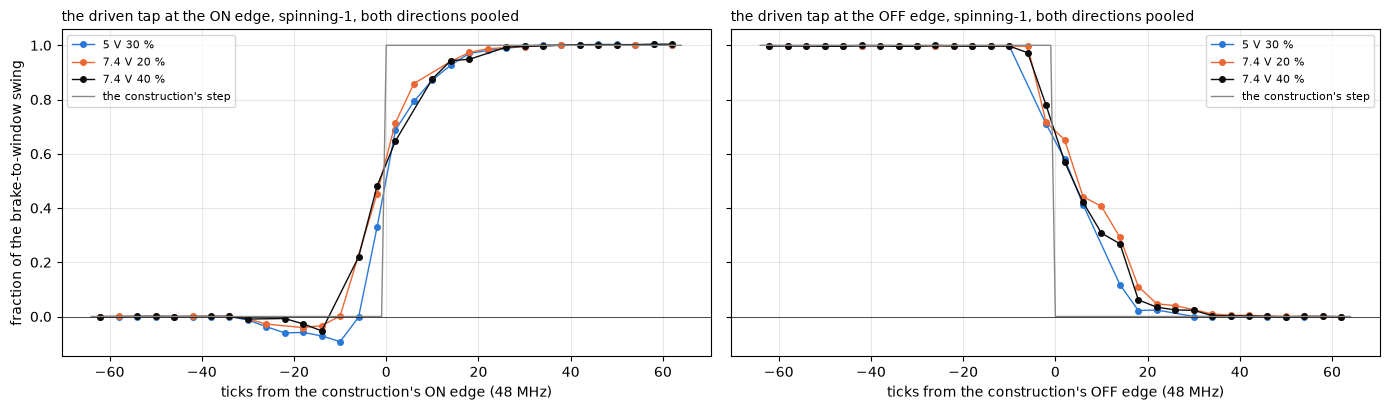

In [19]:
# the edge term on the spinning motor: spinning-1's bursts, the period mean of the tap difference less the share construction
E_FOLD = bd.edge_fold()
EC = bd.edge_correction(E_FOLD)
print("the fold's delta, period mean less the construction, mV: " + ", ".join(
    f"{k if k == 'all' else f'{k:g} V'} {v[0]:+.1f} +/- {v[1]:.1f} (sd {v[2]:.1f})" for k, v in EC.items()))
print(E_FOLD.groupby(["level", "duty"]).agg(bursts=("delta_mv", "size"), delta_mv=("delta_mv", "mean"), sd_mv=("delta_mv", "std")).round(2).to_string())
SHAPE, PROFILES = bd.edge_shape()
for r in SHAPE.itertuples():
    print(f"{r.level:g} V {r.duty} %: ON edge half crossing {r.on_half_ticks:+.1f} ticks from the construction, dip {r.on_dip:+.2f} of the swing before it, "
          f"{r.on_mv:+.1f} mV of period mean; OFF edge half crossing {r.off_half_ticks:+.1f} ticks, {r.off_mv:+.1f} mV, the fall from 0.7 to 0.1 of the "
          f"swing {r.off_v_per_us:.1f} V/us, which at {r.off_edge_ma:.0f} mA needs {r.off_c_nf:.1f} nF")
# the same test on capture-1, no meter: rung pairs of the two rails that turn at about the same speed
for col, lab in (("R_b", "route b"), ("R_a", "route a")):
    D, m, s = bd.matched_pairs(C1, col)
    print(f"capture-1, {lab}: 7.4 V less 5.0 V at matched speed " + ", ".join(f"{r.pair} {r.d_mv:+.1f} +/- {r.se_mv:.1f} mV" for r in D.itertuples())
          + f"; weighted {m:+.1f} +/- {s:.1f} mV")
fold_d, fold_se = EC[7.4][0] - EC[5.0][0], np.hypot(EC[7.4][1], EC[5.0][1])
_, mb, sb = bd.matched_pairs(C1, "R_b")
print(f"the fold says {fold_d:+.1f} +/- {fold_se:.1f} mV with the meter in the loop, capture-1 {mb:+.1f} +/- {sb:.1f}: "
      f"{(mb - fold_d) / np.hypot(sb, fold_se):+.1f} sigma apart")
print("R per tick of ON width by rung, ohm: " + ", ".join(f"{lv:g} V {du} % {g['edge_ohm_per_tick'].mean():.3f}" for (lv, du), g in C1.groupby(["level", "duty"])))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for (lv, du), c in zip(bd.SPUN_POINTS, (BLUE, ORANGE, INK)):
    for a, edge in zip(ax, ("on", "off")):
        x, f = PROFILES[(lv, du, edge)]
        ok = np.isfinite(f)
        a.plot(x[ok], f[ok], "o-", ms=4, lw=1, color=c, label=f"{lv:g} V {du} %")
for a, edge in zip(ax, ("ON", "OFF")):
    x = np.arange(-64, 65)
    a.plot(x, (x >= 0) if edge == "ON" else (x < 0), "-", color=MUTED, lw=1, label="the construction's step")
    a.axhline(0, color=INK, lw=0.5); a.grid(alpha=0.3); a.legend(fontsize=8)
    a.set_xlabel(f"ticks from the construction's {edge} edge (48 MHz)")
    a.set_title(f"the driven tap at the {edge} edge, spinning-1, both directions pooled", loc="left", fontsize=10)
ax[0].set_ylabel("fraction of the brake-to-window swing")
plt.tight_layout(); plt.show()

The thing to see is the driven tap dipping under zero before the ON edge and falling late after the OFF edge. On the spinning motor the period mean sits against the construction by -1.9 $\pm$ 1.5 mV at 5 V and +19.2 $\pm$ 1.7 mV at 7.4 V, the same at 20 and 40 %. The fold puts the volt-ticks in two places. Before each ON edge the driven tap dips 0.04 to 0.09 of its swing, where the current the inductance holds keeps that terminal on a body diode through the dead time, worth +0.3 to -6.4 mV of period mean. After each OFF edge the tap falls slowly, its half crossing 3.9 to 4.9 ticks late with a tail of 25 to 30 ticks, worth +9.1 mV at 5 V and +17.5 to +21.0 mV at 7.4 V. From 0.7 to 0.1 of the swing it falls at 8.7 to 11.9 V/us, which at bemf-coast's OFF-edge current of 104 to 142 mA is what a fall limited by 10.6 to 12.0 nF gives, close to the 7 to 11 nF the teardown read for the gray disc across the terminals.

The fold does not carry over to capture-1. There the rung pairs put 7.4 V less 5 V at -0.3 $\pm$ 3.5 mV by route a and -9.6 $\pm$ 2.3 mV by route b, against the fold's +21.0 $\pm$ 2.3 mV, 9.4 sigma apart. Within the meter's wiring the fold holds, since meter-1's own matched pair, further down, reads 7.4 V less 5.0 V at -23.1 mV of V - E through the construction, which is the fold's +21 mV left out of it. So the OFF-edge tail most likely belongs to the wiring with the meter, moderate confidence, and its mechanism is open. The same pairs put the two rails, which run at different duties and window volts, together by route a at matched speed and about 10 mV apart by route b, so a rail term of up to that size sits in the construction, taken up with $V_b$ below. The main read takes $\delta$ = 0 with a band of $\pm$5 mV, which brackets the fold's dead-time dip and its 5 V tail and does not bracket its +19 mV at 7.4 V. Per mV of $\delta$ the running R moves by $1/i$, 0.010 to 0.021 ohm, and per tick of ON width by 0.025 to 0.054 ohm.

The analytic construction stands in for running motor-model's slow-decay steady state backward. Both are the same volt-second balance, which the cell below checks at 5 V 30 % by running the simulator at the analytic R and reading back the R its own EMF implies over whole periods.

In [20]:
# the analytic construction against motor-model's own slow-decay steady state at 5 V 30 %: the simulator run at the analytic R,
# its averaging mask against whole PWM periods, and the R its own EMF implies over whole periods
g = C1[(C1["level"] == 5.0) & (C1["duty"] == 30)]
duty, v_on, i_t, e0 = float(g["duty_applied_pct"].mean()), g["v_on"].mean(), g["i_b"].mean(), g["e_cut"].mean()
s_ = mm.share(duty)                                                     # the share at the two rails' mean edges, as steady() uses
r_an = (s_ * v_on - (1 - s_) * bd.R_BRK * i_t * 1e-3 - e0) / (i_t * 1e-3)
l0 = PT[(PT["set"] == "motor") & (PT["param"] == "l0")]["value"].iloc[0] * 1e-3
st_ = mm.steady(dict(l0=l0, mem=1, rs=r_an), duty, v_on, i_t, r_on=0.0)
ser, ph_ = st_["ser"], st_["ph"]
tr = np.flatnonzero((ph_[1:] == -mm.P // 2) & (ph_[:-1] != -mm.P // 2)) + 1    # the troughs inside the mask
a, b = tr[0], tr[-1]                                                    # trough to trough, whole periods
half = int(mm.BOARD.drive_ticks(int(round(duty / 100 * 32768))))
on = (ph_[a:b] >= -half + mm.SLOW_ON) & (ph_[a:b] < half + mm.SLOW_OFF)
r_whole = (on.mean() * v_on - st_["emf"] - (1 - on.mean()) * bd.R_BRK * ser[a:b][~on].mean() * 1e-3) / (ser[a:b].mean() * 1e-3)
print(f"analytic R {r_an:.4f} ohm; the simulator at that R: mask {len(ser) / mm.P:.1f} periods, whole periods inside it {(b - a) / mm.P:.0f}, their mean "
      f"{ser[a:b].mean() - i_t:+.2f} mA over the target, worth {r_an * (ser[a:b].mean() - i_t):.1f} mV of EMF; the R its EMF implies over whole periods {r_whole:.4f} ohm; E0 less its EMF {(e0 - st_['emf']) * 1e3:+.1f} mV")
# the same mask under the central model at the spinning G: its mean over whole periods against its 16.5 at the spinning
# points, with G refitted on whole periods, and at the grid's corners; then 7.4 V's own slow-decay edges at 7.4 V
p_c = dict(P_FAST[("RGb", 2)], g=G_SPIN)
gn = GRID[GRID["loop"] == "no meter"].set_index(["rail", "duty"])
CORNERS = [(v, du) for v in (3.7, 5.0, 7.4, 8.4) for du in (10, 30, 60, 90)]
E74 = dict(on_lag=mm.ST["tap_on_edge_lag_7v4"]["value"], off_lag=mm.ST["off_edge_lag_7v4"]["value"])
jobs = ([(mm.steady_both, (dict(p_c, rs=rs_pt(r)), r["duty"], r["v_on"], r["mean"]), {}) for _, r in PTS.iterrows()]
        + [(mm.steady_both, (dict(p_c, rs=R_MOT), du, v, gn.loc[(v, du), "mean_ma"]), {}) for v, du in CORNERS]
        + [(mm.steady_both, (dict(p_c, rs=R_MOT), du, 7.4, gn.loc[(7.4, du), "mean_ma"]), E74) for du in (15, 20, 30)])
MB = mm.run_parallel(jobs, chunksize=2)
bias_pts = np.array([m["mean_whole"] - m["mean"] for m in MB[:len(PTS)]])
bias_cor = {c: m["mean_whole"] - m["mean"] for c, m in zip(CORNERS, MB[len(PTS):len(PTS) + len(CORNERS)])}
G_WHOLE = fit_g(PTS["gap"].to_numpy() + bias_pts, ALL)[0]
print(f"the whole periods' mean over the mask's at the {len(PTS)} spinning points {bias_pts.min():+.2f} to {bias_pts.max():+.2f} mA, mean {bias_pts.mean():+.2f}; "
      f"G_spin refitted on whole periods {G_WHOLE * 1e3:.2f} mS against {G_SPIN * 1e3:.2f}")
print("the same at the grid's corners, no meter: " + "; ".join(f"{v:g} V " + ", ".join(f"{du} % {bias_cor[(v, du)]:+.2f}" for du in (10, 30, 60, 90))
                                                               for v in (3.7, 5.0, 7.4, 8.4)) + " mA")
print(f"7.4 V's own slow-decay edges, {E74['on_lag']:.1f} and {E74['off_lag']:.1f} ticks against {mm.SLOW_ON:.1f} and {mm.SLOW_OFF:.1f}, at 7.4 V: " + ", ".join(
    f"{du} % {m['crest_less_mean'] - gn.loc[(7.4, du), 'RGb']:+.2f}" for du, m in zip((15, 20, 30), MB[len(PTS) + len(CORNERS):])) + " mA on the term")

analytic R 4.4489 ohm; the simulator at that R: mask 16.5 periods, whole periods inside it 15, their mean +0.76 mA over the target, worth 3.4 mV of EMF; the R its EMF implies over whole periods 4.4490 ohm; E0 less its EMF +4.3 mV


the whole periods' mean over the mask's at the 18 spinning points +0.38 to +1.01 mA, mean +0.69; G_spin refitted on whole periods 3.51 mS against 3.35
the same at the grid's corners, no meter: 3.7 V 10 % +0.20, 30 % +0.48, 60 % +0.55, 90 % +0.24; 5 V 10 % +0.27, 30 % +0.63, 60 % +0.73, 90 % +0.32; 7.4 V 10 % +0.39, 30 % +0.89, 60 % +1.03, 90 % +0.47; 8.4 V 10 % +0.44, 30 % +1.00, 60 % +1.14, 90 % +0.52 mA
7.4 V's own slow-decay edges, 42.0 and 15.0 ticks against 39.5 and 14.0, at 7.4 V: 15 % -0.33, 20 % -0.30, 30 % -0.24 mA on the term


Run at the analytic R, the simulator's balance over whole periods gives the analytic R back to 1e-4 ohm. Its solved EMF sits 4.3 mV under $E_0$ because `steady()` averages over 16.5 periods, so its mean over whole periods runs 0.76 mA over its target, which accounts for 3.4 of the 4.3 mV. That offset is the averaging mask, not the window model, high confidence. Under the central model at the spinning $G$ the mask's mean runs 0.38 to 1.01 mA under the whole periods' at the 18 spinning points, so the modeled term reads that much high, and $G_\mathrm{spin}$ refitted on whole periods is 3.51 mS against 3.35. The fit absorbed it at those points, about 0.16 mS of $G$. At the grid's corners the bias runs from 0.20 to 1.14 mA, so the cells away from the fitted points, 10 and 90 % and 8.4 V, keep up to about 0.5 mA of it. Averaging whole periods would move the published grid by more than its rounding, so `steady()` keeps its mask and this stays a limitation. The simulator also runs slow decay's edges at the mean of sample-timing's 3.7 and 7.4 V lags, 39.5 and 14.0 ticks, at every rail. At 7.4 V's own 42.0 and 15.0 ticks the 7.4 V term reads 0.24 to 0.33 mA lower, a second small limitation of the grid.

### The current

Two routes give the period-mean current with no meter in the loop. Route a is the coast's drag at the cut, $J\alpha/K_t$ with the speed pinned by the spin's own count, times the coast-to-meter scale found above. Route b is the crest sample less the crest term of the grid above at the rung's rail and duty. The two are not independent at the rung level, since $G_\mathrm{spin}$ was fitted to points that include capture-1's ten rungs with route a's current as their truth, so they differ only by the model's residuals. At 100 % the board's current needs no term. The cell prints both per rung.

In [21]:
# the two currents per rung: route a, the coast's pinned drag times the coast-to-meter scale, and route b, the crest sample
# less the crest term of the grid above
RA = bd.rung_table(C1, "R_a", "err_a_ohm")
RB = bd.rung_table(C1, "R_b", "err_b_ohm")
cs, csd = bd.c_scale()
print(f"route a: drag x {cs:.4f} (sd {csd:.4f} over 30 meter spins, se {csd / np.sqrt(30) / cs * 100:.1f} %); the pinned drag's own scatter per spin "
      f"{DRAG_NOISE * 100:.2f} %. Route b: the crest term's band {C1['term_err'].min():.1f} to {C1['term_err'].max():.1f} mA")
print(pd.DataFrame(dict(level=RA["level"], duty=RA["duty"], rev_s=RA["rev_s"], i_a_ma=RA["i_a"], i_b_ma=RA["i_b"],
                        a_over_b=RA["i_a"] / RA["i_b"])).round(3).to_string(index=False))
st_dc = TB["speed-torque"]
print(f"at 100 % the board's current less the coast's drag: 5 ms windows {(st_dc['i_crest_50'] - st_dc['drag_win_ma']).mean():+.1f} mA "
      f"(sd {(st_dc['i_crest_50'] - st_dc['drag_win_ma']).std():.1f}), pinned x {cs:.3f} {(st_dc['i_crest_50'] - cs * st_dc['drag_pin_ma']).mean():+.1f} mA "
      f"(sd {(st_dc['i_crest_50'] - cs * st_dc['drag_pin_ma']).std():.1f})")

route a: drag x 0.9839 (sd 0.0305 over 30 meter spins, se 0.6 %); the pinned drag's own scatter per spin 2.35 %. Route b: the crest term's band 0.7 to 1.9 mA
 level  duty   rev_s  i_a_ma  i_b_ma  a_over_b
   5.0    15  64.721  47.583  47.163     1.009
   5.0    20  93.537  53.666  53.791     0.998
   5.0    30 152.881  64.175  63.648     1.008
   5.0    40 214.574  69.404  68.611     1.012
   5.0    60 332.151  83.987  81.324     1.033
   7.4    15 105.605  54.560  56.060     0.973
   7.4    20 149.255  61.486  63.201     0.973
   7.4    30 239.386  71.843  71.950     0.999
   7.4    40 325.161  82.729  82.161     1.007
   7.4    60 492.922  96.354  93.417     1.031
at 100 % the board's current less the coast's drag: 5 ms windows -1.3 mA (sd 2.8), pinned x 0.984 +5.0 mA (sd 4.5)


Route a over route b runs 0.973 to 1.033 by rung, low at 7.4 V 15 and 20 % and high at 60 %, which is the crest term's own split by rail and its 60 % misses above. The pinned drag scatters 2.35 % from spin to spin, the coast scale's standard error is 0.6 % and the meter's class 0.8 %. Route b's own noise is 0.2 to 0.6 % a spin and its band 1.6 to 3.7 % of R. At 100 % the board's current sits -1.3 mA, sd 2.8, from the coast's 5 ms-window drag and +5.0 mA from the pinned drag times the scale.

### The EMF at the cut

$E_0$ is bemf-coast's read, a line through the one-period boxcar of the coast over the whole ripple cycles nearest 10 ms from 1 ms, open rows bridged, carried back to the cut. The cell measures its noise from spin to spin, as $E_0$ over $K_e$ times the spin's own ripple count, whose 200 ms count is good to a few hundredths of a percent, and its spread over other reasonable reads, a 5 and a 20 ms window, a quadratic, a start at 2 ms and no bridging. It then asks whether a reading depends on where in the 6/rev cycle the cut lands, by a term at one cycle in the cut's phase.

In [22]:
# the EMF at the cut: its own noise, its spread over other reads, the first cycles after the cut, and the cut's phase
ke_win = C1["e_win"] / (2 * np.pi * C1["coast_rev_s"])
g = ke_win.groupby([C1["level"], C1["duty"], C1["dir"]])
print(f"E0 over Ke x the spin's count, within rung and direction: sd {E0_NOISE * 100:.2f} % of E; the coast window's own Ke: sd "
      f"{np.sqrt((g.var() * (g.size() - 1)).sum() / (g.size() - 1).sum()) / ke_win.mean() * 100:.2f} %; the line fit's own se, median "
      f"{(C1['e_cut_se'] / C1['e_cut']).median() * 100:.2f} %")
EA = C1.groupby(["level", "duty"]).apply(lambda h: pd.Series(dict(
    rev_s=h["spin_rev_s"].mean(), **{a: ((h[f"e_cut_{a}"] - h["e_cut"]) / h["e_cut"]).mean() * 100 for a in ("5ms", "20ms", "quad20", "from2ms", "unbridged")},
    alt_sd_mv=h["e_alt_sd"].mean() * 1e3, alt_sd_pct_r=(h["sys_Ealt_ohm"] / h["R_b"]).mean() * 100,
    one_pct_e_ohm=(0.01 * h["e_cut"] / (h["i_b"] * 1e-3)).mean())), include_groups=False)
print("the other reads against the 10 ms line, % of E0, and the spread as mV and as % of R; one_pct_e_ohm is 1 % of E0 in ohm of R:")
print(EA.round(3).to_string())
STF, TERM_ERR = bd.full_duty(TB["speed-torque"], E0_NOISE)
for lab, D in (("capture-1", C1), ("speed-torque 100 %", STF)):
    d1 = (D["e_first1_fit"] - D["e_cut"]) / D["e_cut"] * 100
    print(f"{lab}: the first ripple cycle after the cut reads {d1.mean():+.2f} % of E0 (se {d1.std() / np.sqrt(len(d1)):.2f})")
print(f"E0 over Ke x the spin's count at 100 %: {(STF['ke_cut'].mean() / mm.KE - 1) * 100:+.2f} %; bemf-coast's spin route on capture-1 "
      f"{mm.BEMF['ke_spin_route_pct_diff']['value']:+.2f} %")
ph = C1["phase_cut"].to_numpy()
rbar = np.hypot(np.cos(2 * np.pi * ph).mean(), np.sin(2 * np.pi * ph).mean())
print(f"the cut's phase in the 6/rev cycle over {len(ph)} cuts: histogram in fifths {np.histogram(ph, bins=5, range=(0, 1))[0].tolist()}, "
      f"Rayleigh p about {np.exp(-len(ph) * rbar ** 2):.2f}")
ke_c = C1["e_cut"] / (2 * np.pi * C1["spin_rev_s"])
for lab, y, unit in (("E0 over the spin's count", (ke_c / ke_c.groupby([C1["level"], C1["duty"]]).transform("mean") - 1) * 100, "%"),
                     ("the first cycle less E0", (C1["e_first1_fit"] - C1["e_cut"]) / C1["e_cut"] * 100, "%"),
                     ("the first three cycles less E0", (C1["e_first3"] - C1["e_cut"]) / C1["e_cut"] * 100, "%"),
                     ("the pre-cut V_on, 200 ms", (C1["v_on_200"] / C1.groupby(["level", "duty"])["v_on_200"].transform("mean") - 1) * 100, "%"),
                     ("the pre-cut crest current, 200 ms", (C1["i_crest_200"] / C1.groupby(["level", "duty"])["i_crest_200"].transform("mean") - 1) * 100, "%"),
                     ("R_run, route b", C1["R_b"] - C1.groupby(["level", "duty"])["R_b"].transform("mean"), "ohm")):
    amp, se, _ = bd.phase_fit(ph, y.to_numpy())
    print(f"  1/cycle term in the cut's phase, {lab}: {amp:.3f} +/- {se:.3f} {unit} ({amp / se:.1f} sigma)")

E0 over Ke x the spin's count, within rung and direction: sd 0.53 % of E; the coast window's own Ke: sd 0.19 %; the line fit's own se, median 1.03 %
the other reads against the 10 ms line, % of E0, and the spread as mV and as % of R; one_pct_e_ohm is 1 % of E0 in ohm of R:
              rev_s    5ms   20ms  quad20  from2ms  unbridged  alt_sd_mv  alt_sd_pct_r  one_pct_e_ohm
level duty                                                                                           
5.0   15     64.721  0.000 -1.384  -1.933   -0.362      0.000      5.052         2.507          0.101
      20     93.537  0.762 -0.531  -0.674   -0.403      0.000      4.700         2.010          0.128
      30    152.881  1.066 -0.672  -0.111   -0.469      0.000      7.905         2.791          0.177
      40    214.574  0.150 -0.229  -0.063   -0.212      0.000      4.192         1.310          0.230
      60    332.151 -0.015  0.036   0.059   -0.021     -0.057      4.846         1.046          0.299
7.4   15    

$E_0$ scatters 0.53 % of E from spin to spin. The coast window's own $K_e$ scatters 0.19 %, so the extrapolation to the cut owns most of that, and the line's own standard error of about 1 % overstates it. The other reads spread 3 to 15 mV by rung, carried as a systematic of 1.0 to 2.9 % of R. $E_0$ over $K_e$ times the spin's count is -0.20 % on capture-1 and -0.09 % at 100 %, so the EMF at the cut is the drive's speed times the coast's $K_e$ to a few tenths of a percent. The first ripple cycle after the cut reads 0.69 $\pm$ 0.22 % under $E_0$, a 3-sigma effect of the cut's transient, and from the second cycle on the coast sits on the line. Tap settling is the likely cause, low confidence, and $E_0$ does not use the first millisecond. The cuts land evenly over the ripple cycle. A read over the first one to three cycles carries about 1 % of E in the cut's phase, while $E_0$'s 10 ms of whole cycles and the pre-cut means carry none, high confidence. The running R's 2.0 sigma term in the phase is not a finding.

### How far each moves R

$R_\mathrm{run}$ is a difference of two large voltages over a small current, so 1 % of $E_0$ is 0.10 to 0.39 ohm, 2.3 to 5.3 % of R by rung. The budget of one reading follows from the terms above. Its random part is $E_0$'s noise, the pre-cut voltage's standard error and the current's, spin by spin, and route a adds the pinned drag's 2.35 %. Its rung-common part is the edge band, the EMF zero's $\pm$1.2 counts, the brake loop, the crest term's band, the terminal chain and the spread of the $E_0$ reads, which a rung's six spins share and do not average away.

### The 100 % run-ups, the clean case

At 100 % both taps are static, so the tap difference is the DC motor voltage with no share, brake or edge term. The EMF zero cancels in V - E, since both carry it in full, and the crest sample is the DC current, the 100 % term being zero within -0.6 to +0.4 mA. So $(V - E_0)/i$ over the run-up's last 50 ms needs nothing modeled. The cell prints it run-up by run-up, by its alternative reads, with its budget and the excess over the locked R as volts. The figure sets each run-up's chord against the locked R.

 k  dir   rev_s   v_v    i_ma  e0_v  chord_ohm  budget_ohm  excess_mv  dropouts_per_s
 0    1 543.280 4.891 109.162 3.941      8.702       0.242    463.589           935.0
 0   -1 560.939 4.890 105.248 4.134      7.184       0.248    287.189           495.0
 1    1 543.376 4.891 109.264 4.019      7.976       0.258    384.683           925.0
 1   -1 555.752 4.890 110.224 4.070      7.434       0.228    328.270           415.0
 2    1 541.470 4.888 110.090 3.983      8.223       0.236    414.823           980.0
 2   -1 557.921 4.892 105.541 4.076      7.731       0.257    345.672           525.0
  last 100 ms: 7.751 ohm, sd 0.491, se 0.200; +1 8.124, -1 7.377
  last 50 ms: 7.875 ohm, sd 0.549, se 0.224; +1 8.300, -1 7.449
  last 20 ms: 7.935 ohm, sd 0.556, se 0.227; +1 8.357, -1 7.512
  last 10 ms: 7.924 ohm, sd 0.590, se 0.241; +1 8.381, -1 7.467
  E0 by a quadratic: 7.824 ohm, sd 0.466, se 0.190; +1 8.160, -1 7.487
  E0 from the first cycle: 8.097 ohm, sd 0.839, se 0.343; +1 8.731, -1

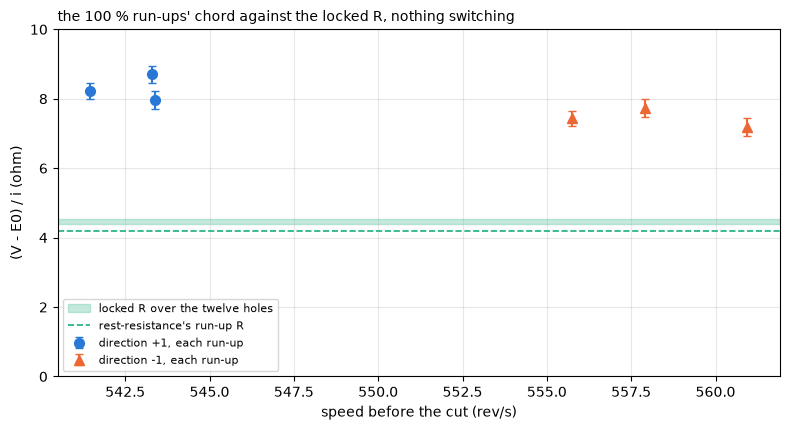

In [23]:
# speed-torque's six run-ups at 100 %: (V - E0)/i over the last 50 ms with nothing modeled, per run-up and by read
print(STF[["k", "dir", "spin_rev_s", "v", "i", "e_cut", "R", "err", "excess_mv", "dropouts_per_s"]].rename(
    columns={"spin_rev_s": "rev_s", "v": "v_v", "i": "i_ma", "e_cut": "e0_v", "R": "chord_ohm", "err": "budget_ohm"}).round(3).to_string(index=False))
for col, lab in (("R_100", "last 100 ms"), ("R_50", "last 50 ms"), ("R_20", "last 20 ms"), ("R_10", "last 10 ms"), ("R_quad20", "E0 by a quadratic"),
                 ("R_first1", "E0 from the first cycle"), ("R_drag_win", "the coast's 5 ms-window drag as the current")):
    x = STF[col]
    print(f"  {lab}: {x.mean():.3f} ohm, sd {x.std():.3f}, se {x.std() / np.sqrt(len(x)):.3f}; +1 {x[STF['dir'] > 0].mean():.3f}, -1 {x[STF['dir'] < 0].mean():.3f}")
by = STF.groupby("dir")["R"]
print(f"per-run-up budget: E0 {np.sqrt((STF['err_E'] ** 2).mean()):.3f}, current {np.sqrt((STF['err_i'] ** 2).mean()):.3f}, total "
      f"{np.sqrt((STF['err'] ** 2).mean()):.3f} ohm, against the within-direction sd {np.sqrt(by.var().mean()):.3f}; "
      f"+1 less -1 {by.mean()[1] - by.mean()[-1]:+.3f} +/- {np.hypot(by.std()[1], by.std()[-1]) / np.sqrt(3):.3f} ohm")
print(f"systematics: the current's {bd.CPA_CLASS_PCT:g} % class {STF['R'].mean() * bd.CPA_CLASS_PCT / 100:.3f} ohm, the 100 % term's band "
      f"+/-{TERM_ERR:.2f} mA {STF['R'].mean() * TERM_ERR / STF['i'].mean():.3f} ohm")
X100 = STF["excess_mv"]
print(f"excess over {bd.R_LOCKED:.3f} x i: {X100.mean():.0f} mV (sd {X100.std():.0f}), +1 {X100[STF['dir'] > 0].mean():.0f}, -1 {X100[STF['dir'] < 0].mean():.0f}, "
      f"at {STF['i'].mean():.1f} mA and {STF['spin_rev_s'].mean():.0f} rev/s; the chord {STF['R'].mean() / bd.R_LOCKED * 100 - 100:+.0f} % over the locked R and "
      f"{STF['R'].mean() / bd.R_RUNUP * 100 - 100:+.0f} % over the run-up R")
print(f"speed-torque's own run-up line, R {mm.SPT['r_rotating_ohm']['value']:.3f} ohm and V0 {mm.SPT['v0_rotating_v']['value']:+.3f} V, at {STF['i'].mean():.0f} mA "
      f"gives {mm.SPT['r_rotating_ohm']['value'] + mm.SPT['v0_rotating_v']['value'] / (STF['i'].mean() * 1e-3):.2f} ohm")
H100 = TB["high-1"][TB["high-1"]["duty"] == 100]
r_loop = (H100["v_on_200"] - H100["e_cut"]) / (H100["meter_ma"] * 1e-3)
print(f"high-1 at 100 %, the meter in series: loop R by the meter's current {r_loop.mean():.2f} ohm (se {r_loop.std() / np.sqrt(len(r_loop)):.2f}) at "
      f"{H100['spin_rev_s'].mean():.0f} rev/s, less the paired meter R {R_M:.2f}: the motor {r_loop.mean() - R_M:.2f} +/- "
      f"{np.hypot(r_loop.std() / np.sqrt(len(r_loop)), R_M_SD):.2f} ohm")

fig, ax = plt.subplots(figsize=(8, 4.4))
for d, mk in ((1, "o"), (-1, "^")):
    h = STF[STF["dir"] == d]
    ax.errorbar(h["spin_rev_s"], h["R"], yerr=h["err"], fmt=mk, color=BLUE if d > 0 else ORANGE, ms=7, capsize=3, label=f"direction {d:+d}, each run-up")
ax.axhspan(bd.R_LOCKED_LO, bd.R_LOCKED_HI, color=GREEN, alpha=0.25, label="locked R over the twelve holes")
ax.axhline(bd.R_RUNUP, color=GREEN, ls="--", lw=1.2, label="rest-resistance's run-up R")
ax.set_xlabel("speed before the cut (rev/s)"); ax.set_ylabel("(V - E0) / i (ohm)"); ax.set_ylim(0, 10); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("the 100 % run-ups' chord against the locked R, nothing switching", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

The thing to see is every run-up sitting near twice the locked R. The six read $(V - E_0)/i$ = 7.88 ohm, sd 0.55, se 0.22, against the locked 4.455, an excess of 371 mV over $4.455\,i$ at 108 mA and 550 rev/s, +77 % over the locked R and +88 % over the run-up R. The reads over 10 to 100 ms, $E_0$ by a quadratic or by the first cycle, and the current by the coast's drag land from 7.75 to 8.10 ohm. The budget of one run-up is 0.25 ohm against a within-direction sd of 0.33, and the current's 2 % class adds 0.16 ohm shared by all six. Direction +1 reads 0.85 $\pm$ 0.27 ohm over -1, 3.2 sigma, and +1 drops out 925 to 980 times a second against 415 to 525. With nothing switching and nothing modeled, the gap between the pre-cut volts and the EMF is physics in the motor and not an artifact of the reduction, high confidence.

Speed-torque's own run-up line, 3.81 ohm with +0.43 V, gives 7.79 ohm at 108 mA, the same thing read as a line. Its intercept is most likely this excess seen at the run-up's low-current, high-speed end, moderate confidence from the run-up test below, and not a fixed drop, since the free spins put the excess near zero below 160 rev/s. High-1 at 100 % with the meter in series reads a loop of 18.07 ohm by the meter's own current at 480 rev/s, which leaves 9.20 $\pm$ 0.67 ohm for the motor through the paired meter R, the excess again.

### Capture-1 per rung

The same chord at partial duty, every spin of capture-1 through the construction and both currents. The cell prints the rung means by route and direction against the per-spin budget, the budget of one reading by route b, the pooled R below 160 rev/s against the locked, run-up and ohms R, the slope with speed inside the low band, and the trends with direction and time order. The figure draws the chord against speed with the 100 % ends beside it on the left, and the scatter from spin to spin against the per-spin budget on the right.

route a, mean, sd and se over six spins, by direction, and the rms per-spin budget (ohm):
 level  duty   rev_s  mean    sd    se  plus  minus  budget  sd_over_budget
   5.0    15  64.721 4.256 0.106 0.043 4.287  4.225   0.113           0.938
   5.0    20  93.537 4.370 0.049 0.020 4.413  4.328   0.123           0.400
   5.0    30 152.881 4.427 0.121 0.049 4.500  4.354   0.140           0.864
   5.0    40 214.574 4.636 0.118 0.048 4.674  4.598   0.163           0.721
   5.0    60 332.151 5.380 0.557 0.227 5.843  4.917   0.203           2.747
   7.4    15 105.605 4.153 0.075 0.030 4.202  4.105   0.122           0.612
   7.4    20 149.255 4.387 0.130 0.053 4.433  4.342   0.138           0.943
   7.4    30 239.386 4.680 0.157 0.064 4.732  4.628   0.169           0.927
   7.4    40 325.161 5.357 0.762 0.311 6.005  4.709   0.199           3.836
   7.4    60 492.922 7.138 1.280 0.522 8.279  5.998   0.266           4.818
route b, mean, sd and se over six spins, by direction, and the rms per-spi

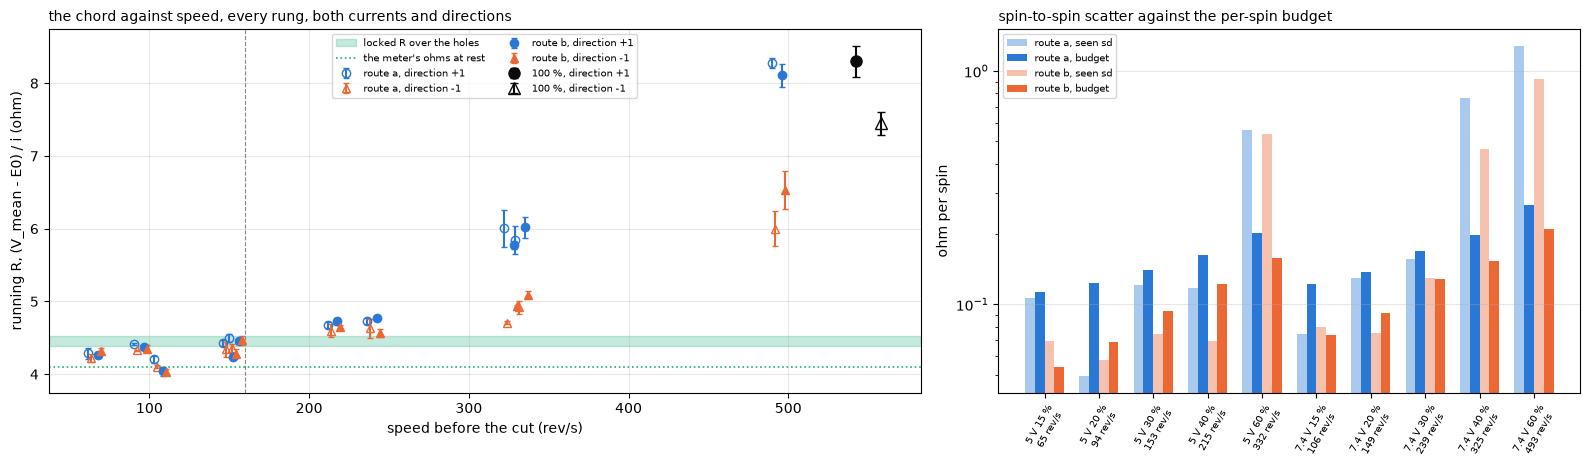

In [24]:
# capture-1's running R per rung by both currents, both directions, against the per-spin budget, and pooled below 160 rev/s
for lab, t in (("route a", RA), ("route b", RB)):
    print(f"{lab}, mean, sd and se over six spins, by direction, and the rms per-spin budget (ohm):")
    print(t[["level", "duty", "rev_s", "mean", "sd", "se", "plus", "minus", "budget", "sd_over_budget"]].round(3).to_string(index=False))
for lab, t in (("a", RA), ("b", RB)):
    for band, sel in (("all", t["rev_s"] > 0), (f"under {bd.SLOW_BAND:.0f} rev/s", t["rev_s"] < bd.SLOW_BAND)):
        psd, bud, ratio = bd.scatter_vs_budget(t[sel])
        print(f"route {lab}, {band}: pooled within-rung sd {psd:.3f} ohm, rms budget {bud:.3f}, ratio {ratio:.2f}")
BT = bd.budget_table(C1)
print("one reading's budget, route b, % of the rung's R:")
print(BT[["level", "duty", "rev_s", "random_b_pct", "E0_pct", "V_pct", "ib_pct", "drag_pct", "seen_sd_pct", "delta_pct", "zero_pct", "term_pct", "Ealt_pct", "sys_b_pct"]].round(2).to_string(index=False))
LOWR = {r: bd.pooled_low(C1, r) for r in ("a", "b")}
for r, p in LOWR.items():
    print(f"route {r} under {bd.LOW:.0f} rev/s: pooled {p['pooled']:.3f} ohm, stat {p['stat']:.3f} (chi2/dof {p['chi2']:.1f} folded in), rung-common sys "
          f"{p['sys']:.3f}, total {p['total']:.3f}; " + ", ".join(f"less {n} {(p['pooled'] - v) / v * 100:+.1f} % ({(p['pooled'] - v) / p['total']:+.1f} sigma)"
                                                            for n, v in (("locked", bd.R_LOCKED), ("run-up", bd.R_RUNUP), ("ohms", bd.R_OHMS))))
for lim in (160, 250):
    for r in ("a", "b"):
        f = bd.slope_low(C1, r, lim)
        print(f"under {lim} rev/s, route {r}, with the rung systematics: {f['pct']:+.1f} +/- {f['pct_se']:.1f} % per 100 rev/s "
              f"({abs(f['b'] / f['se_b']):.1f} sigma), chi2/dof {f['chi2']:.2f}, residuals " + ", ".join(f"{x:+.1f}" for x in f["resid"]))
for lab, t in (("a", RA), ("b", RB)):
    f = bd.wls(t["rev_s"], t["mean"], 1 / t["se"] ** 2)
    print(f"route {lab}, a line over all ten rungs: chi2/dof {f['chi2']:.1f}")
d = C1.groupby(["level", "duty", "k"]).apply(lambda h: h[h["dir"] > 0]["R_b"].mean() - h[h["dir"] < 0]["R_b"].mean(), include_groups=False)
slow = d[d.index.get_level_values("duty").isin([15, 20, 30]) | ((d.index.get_level_values("level") == 5.0) & (d.index.get_level_values("duty") == 40))]
for lab, x in (("all rungs", d), (f"rungs under {bd.SLOW_BAND:.0f} rev/s", slow)):
    print(f"direction +1 less -1, paired by cycle, {lab}: {x.mean():+.3f} +/- {x.std() / np.sqrt(len(x)):.3f} ohm ({x.mean() / (x.std() / np.sqrt(len(x))):+.1f} sigma)")
for lv, g in C1[C1["spin_rev_s"] < bd.SLOW_BAND].groupby("level"):
    f = bd.wls(g["k"], g["R_b"] - g.groupby("duty")["R_b"].transform("mean"))
    print(f"time order inside the {lv:g} V block: {f['b'] * 10:+.3f} +/- {f['se_b'] * 10:.3f} ohm per 10 cycles")
print(f"corr(current, speed) {np.corrcoef(C1['i_b'], C1['spin_rev_s'])[0, 1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw=dict(width_ratios=[1.5, 1]))
for (r, t), off, mfc in ((("a", RA), -3, "none"), (("b", RB), 3, None)):
    for d, col, mk in ((1, "plus", "o"), (-1, "minus", "^")):
        sub = C1.groupby(["level", "duty"])
        se_d = [g[g["dir"] == d][f"R_{r}"].std() / np.sqrt((g["dir"] == d).sum()) for _, g in sub]
        ax[0].errorbar(t["rev_s"] + off + (2 if d < 0 else 0), t[col], yerr=se_d, fmt=mk, ms=6, capsize=2, color=BLUE if d > 0 else ORANGE,
                       mfc=mfc, label=f"route {r}, direction {d:+d}")
for d, mk in ((1, "o"), (-1, "^")):
    h = STF[STF["dir"] == d]
    ax[0].errorbar(h["spin_rev_s"].mean(), h["R"].mean(), yerr=h["R"].std() / np.sqrt(len(h)), fmt=mk, ms=8, capsize=3, color=INK,
                   mfc="none" if d < 0 else INK, label=f"100 %, direction {d:+d}")
ax[0].axhspan(bd.R_LOCKED_LO, bd.R_LOCKED_HI, color=GREEN, alpha=0.25, label="locked R over the holes")
ax[0].axhline(bd.R_OHMS, color=GREEN, ls=":", lw=1.2, label="the meter's ohms at rest")
ax[0].axvline(bd.LOW, color=MUTED, lw=0.8, ls="--")
ax[0].set_xlabel("speed before the cut (rev/s)"); ax[0].set_ylabel("running R, (V_mean - E0) / i (ohm)"); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=7, ncol=2)
ax[0].set_title("the chord against speed, every rung, both currents and directions", loc="left", fontsize=10)
x = np.arange(len(RB))
ax[1].bar(x - 0.27, RA["sd"], 0.18, color=BLUE, alpha=0.4, label="route a, seen sd"); ax[1].bar(x - 0.09, RA["budget"], 0.18, color=BLUE, label="route a, budget")
ax[1].bar(x + 0.09, RB["sd"], 0.18, color=ORANGE, alpha=0.4, label="route b, seen sd"); ax[1].bar(x + 0.27, RB["budget"], 0.18, color=ORANGE, label="route b, budget")
ax[1].set_xticks(x, [f"{lv:g} V {du} %\n{w:.0f} rev/s" for lv, du, w in zip(RB["level"], RB["duty"], RB["rev_s"])], fontsize=7, rotation=60)
ax[1].set_ylabel("ohm per spin"); ax[1].set_yscale("log"); ax[1].grid(alpha=0.3, axis="y"); ax[1].legend(fontsize=7)
ax[1].set_title("spin-to-spin scatter against the per-spin budget", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

On the left the chord holds near the locked R to about 160 rev/s and then climbs, the two directions parting as it does. On the right the scatter sits at the budget below 250 rev/s and well over it above. The pooled within-rung sd over the rms budget is 0.81 by route a and 0.88 by route b below 250 rev/s, and 3.0 above it, where the rungs split by direction. The rung means scatter beyond their own se below 160 rev/s, a chi2 per rung of 11 to 26, and with each rung's term and $E_0$-window systematics added to its error the fits close at 1.3 to 1.9, so those systematics set the floor from rung to rung, 0.11 to 0.16 ohm. One reading by route b carries 1.2 to 2.9 % of R at random and 2.4 to 5.4 % of systematics shared by its rung at partial duty.

From 65 to 160 rev/s the running R is the locked R within the method's error, moderate confidence. Pooled it reads 4.32 $\pm$ 0.13 ohm by route a and 4.30 $\pm$ 0.18 ohm by route b, -3.1 and -3.5 % from the locked 4.455, inside 1.0 sigma. Against the run-up R it is +3 % and against the meter's ohms at rest +5 %, inside 1.6 sigma, and the locked R's own holes span 4.38 to 4.53. Inside that band the slope is +3.8 $\pm$ 5.3 % per 100 rev/s by route a and +2.5 $\pm$ 5.7 % by route b, both under one sigma. From 65 to 250 rev/s it is +7.0 $\pm$ 1.5 % and +6.8 $\pm$ 2.0 % per 100 rev/s, 4.8 and 3.4 sigma, the excess switching on. Over all ten rungs no line fits, and the chord runs from 4.0 to 7.3 ohm and bends upward.

Direction +1 less -1, paired by cycle, is +0.03 $\pm$ 0.03 ohm on the rungs below 250 rev/s, 1.1 sigma and not a finding, and +0.35 $\pm$ 0.10 ohm over every rung, 3.5 sigma, carried by the fast ones. Inside each block the chord shows no drift with cycle order, and the three repeats of a rung show none either, so nothing moved over the 20 minutes of a block. The moves of 3 to 5 % between sittings that rest-resistance and the slow-decay fits above report are not tested here. On a free shaft current and speed move together, a correlation of 0.97, so capture-1 alone cannot say whether the excess follows the speed or the current. The run-ups can.

### Speed against current, the run-up test

Speed-torque's run-ups pass the free spins' speeds at several times their current. The cell runs speed-torque's own estimator cells unchanged for its turn windows, each with its speed, its current and terminal volts with the dropout rows left out, and $di/dt$, and forms $y = u - L\,di/dt - K_e\,\omega$ with $u$ on the rest zero so it matches the coasts. Three readings of the excess are fitted over the windows of the first 100 ms, each with one free R.

- A, a voltage set by the speed, $y = R\,i + V_b(\omega)$, with $V_b$ the free spins' excess at the window's speed and direction.
- B, a resistance set by the speed, $y = R\,i + V_b(\omega)\,i/i_\mathrm{free}(\omega)$, with $i_\mathrm{free}$ the free spins' current at that speed.
- 0, no excess, $y = R\,i$.

Each is held against the windows' own scatter over independent turns. Then the incremental R at fixed speed, each run-up window against the free spin at the same speed and direction, $(y - (V - E)_\mathrm{free})/(i - i_\mathrm{free})$, which assumes no R at all. The figure sets the run-ups' excess over the locked R beside the free spins' and what B predicts on the left, and the incremental R against the free spins' chord on the right.

speed-torque's turn windows: 5397, L 0.833 mH; in the first 100 ms and the free spins' speed range 1461, 188 to 558 rev/s at 119 to 727 mA, the free spins there 66 to 109 mA, the ratio 1.1 to 10.9
model A, a voltage set by speed: R 4.563 ohm, residual rms 72 mV; direction +1 mean -0 mV, direction -1 mean +15 mV
model B, a resistance set by speed: R 3.577 ohm, residual rms 163 mV; direction +1 mean -79 mV, direction -1 mean +56 mV
model 0, no excess: R 5.345 ohm, residual rms 215 mV; direction +1 mean +175 mV, direction -1 mean +47 mV
the windows' own scatter over independent turns: 90 mV rms
y - 4.455 x i in the run-ups by speed, the free spins' excess at the same speed, and what model B predicts there:
 rev_s   n  i_ma  runup_excess_mv  sd_mv  free_excess_mv  free_i_ma  B_predicts_mv
 221.2  19 668.8             27.6   48.7            15.0       69.7          143.9
 260.3  22 603.1             64.8   17.6            31.5       74.4          252.7
 300.7  35 536.9             95.3   27

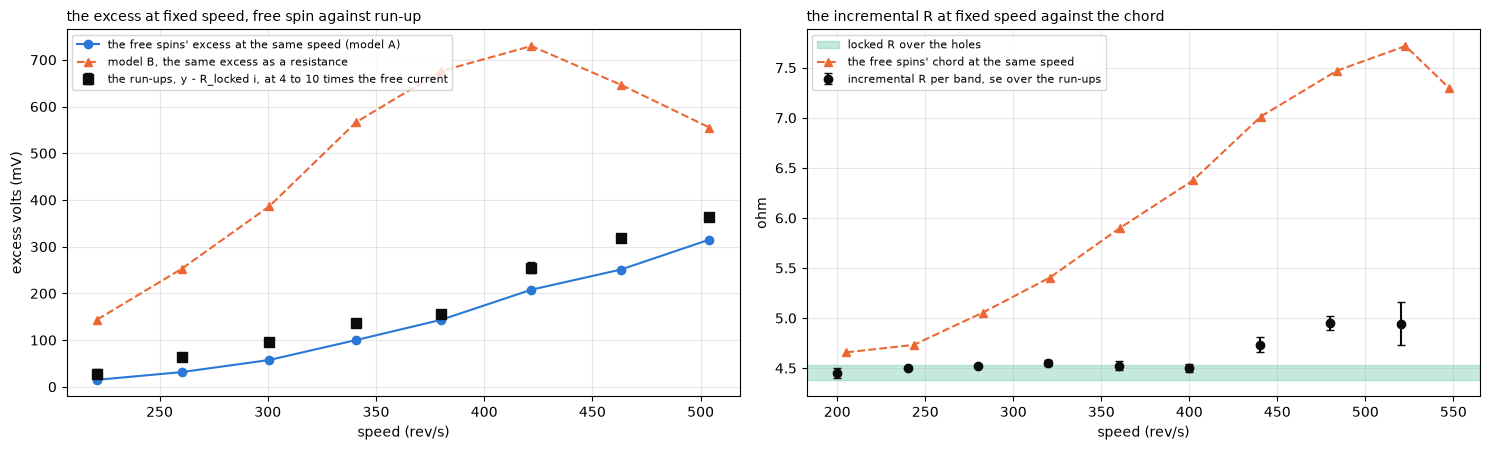

In [25]:
# speed against current: speed-torque's turn windows, by its own estimator cells, against the free spins' excess at the same speed
REV, RUNS_ST, L_H, T_OFF, VPC, SETTLED = bd.runup_windows()
REV, zero_mean = bd.runup_y(REV, RUNS_ST, L_H, T_OFF, VPC)
XF = bd.x_free(C1, TB["speed-torque"])
RU = REV[REV["t"] < SETTLED].copy()
RU["xf"] = [bd.interp_dir(XF, d, w, "x") for d, w in zip(RU["dir"], RU["rev_s"])]       # the free spins' excess at the window's speed
RU["if"] = [bd.interp_dir(XF, d, w, "i") for d, w in zip(RU["dir"], RU["rev_s"])]       # and their current there
RU = RU[np.isfinite(RU["xf"])]
print(f"speed-torque's turn windows: {len(REV)}, L {L_H * 1e3:.3f} mH; in the first {SETTLED * 1e3:.0f} ms and the free spins' speed range {len(RU)}, "
      f"{RU['rev_s'].min():.0f} to {RU['rev_s'].max():.0f} rev/s at {RU['i'].min() * 1e3:.0f} to {RU['i'].max() * 1e3:.0f} mA, the free spins there "
      f"{RU['if'].min() * 1e3:.0f} to {RU['if'].max() * 1e3:.0f} mA, the ratio {(RU['i'] / RU['if']).min():.1f} to {(RU['i'] / RU['if']).max():.1f}")
MODELS = bd.runup_models(RU)
for k, lab in (("A", "a voltage set by speed"), ("B", "a resistance set by speed"), ("0", "no excess")):
    r, res = MODELS[k]
    print(f"model {k}, {lab}: R {r:.3f} ohm, residual rms {res.std() * 1e3:.0f} mV; " + ", ".join(
        f"direction {d:+d} mean {res[(RU['dir'] == d).to_numpy()].mean() * 1e3:+.0f} mV" for d in (1, -1)))
print(f"the windows' own scatter over independent turns: {bd.window_scatter(RU) * 1e3:.0f} mV rms")
BINS = bd.runup_bins(RU, bd.R_LOCKED)
print(f"y - {bd.R_LOCKED:.3f} x i in the run-ups by speed, the free spins' excess at the same speed, and what model B predicts there:")
print(BINS.round(1).to_string(index=False))
d_lock = BINS["runup_excess_mv"] - BINS["free_excess_mv"]
print(f"at the locked R the run-ups sit {d_lock.min():+.0f} to {d_lock.max():+.0f} mV over the free spins' excess, bin by bin; model A's residual "
      "by 40 rev/s band at its own R: " + ", ".join(f"{iv.left:.0f}-{iv.right:.0f} {v * 1e3:+.0f}" for iv, v in pd.Series(np.asarray(MODELS["A"][1]), index=RU.index)
                                                    .groupby(pd.cut(RU["rev_s"], np.arange(180, 600, 40)), observed=True).mean().items()) + " mV")
RINC, RINC_BANDS, RU = bd.incremental_r(RU, XF)
RI, RI_SE = RINC["r_inc"].mean(), RINC["r_inc"].std() / np.sqrt(len(RINC))
RI_SYS = float(np.hypot(RI * bd.CPA_CLASS_PCT / 100, 0.05))         # the current's class, and Ke and the zero together
print("the incremental R at fixed speed per run-up: " + ", ".join(f"k{r.k} {r.dir:+d} {r.r_inc:.3f}" for r in RINC.itertuples())
      + f"; mean {RI:.3f} ohm, sd {RINC['r_inc'].std():.3f}, se {RI_SE:.3f}, sys about {RI_SYS:.2f}; "
      f"+1 {RINC[RINC['dir'] > 0]['r_inc'].mean():.3f}, -1 {RINC[RINC['dir'] < 0]['r_inc'].mean():.3f}")
print(RINC_BANDS.drop(columns="lo").round(3).to_string(index=False))
for r, p in LOWR.items():
    print(f"the incremental R less the pooled low-speed chord, route {r}: {RI - p['pooled']:+.3f} ohm, "
          f"{(RI - p['pooled']) / np.hypot(np.hypot(RI_SE, RI_SYS), p['total']):.1f} sigma")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
ax[0].errorbar(BINS["rev_s"], BINS["runup_excess_mv"], yerr=BINS["sd_mv"] / np.sqrt(BINS["n"]), fmt="s", ms=7, capsize=3, color=INK,
               label="the run-ups, y - R_locked i, at 4 to 10 times the free current")
ax[0].plot(BINS["rev_s"], BINS["free_excess_mv"], "o-", ms=6, color=BLUE, label="the free spins' excess at the same speed (model A)")
ax[0].plot(BINS["rev_s"], BINS["B_predicts_mv"], "^--", ms=6, color=ORANGE, label="model B, the same excess as a resistance")
ax[0].set_xlabel("speed (rev/s)"); ax[0].set_ylabel("excess volts (mV)"); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=8)
ax[0].set_title("the excess at fixed speed, free spin against run-up", loc="left", fontsize=10)
use = RINC_BANDS[RINC_BANDS["lo"] < 540]                              # the last band, a current lever of 30 mA, is not used
ax[1].errorbar(use["lo"] + 20, use["r_inc"], yerr=use["se"], fmt="o", ms=6, capsize=3, color=INK, label="incremental R per band, se over the run-ups")
ax[1].axhspan(bd.R_LOCKED_LO, bd.R_LOCKED_HI, color=GREEN, alpha=0.25, label="locked R over the holes")
ax[1].plot(RU.groupby(pd.cut(RU["rev_s"], np.arange(180, 600, 40)), observed=True)["rev_s"].mean(),
           RU.groupby(pd.cut(RU["rev_s"], np.arange(180, 600, 40)), observed=True).apply(lambda h: (h["ve_f"] / h["if"]).mean(), include_groups=False),
           "^--", color=ORANGE, ms=6, label="the free spins' chord at the same speed")
ax[1].set_xlabel("speed (rev/s)"); ax[1].set_ylabel("ohm"); ax[1].grid(alpha=0.3); ax[1].legend(fontsize=8)
ax[1].set_title("the incremental R at fixed speed against the chord", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

On the left the run-ups' excess follows the free spins' at four to ten times the current, and B, which scales it with the current, sits far above both. The 1461 windows run from 188 to 558 rev/s at 119 to 727 mA, 1.1 to 11 times the free spins' 66 to 109 mA at the same speeds. A voltage set by the speed fits them at 72 mV rms with R 4.56 ohm, inside the windows' own 90 mV scatter. A resistance set by the speed leaves 163 mV with R 3.58 ohm, and no excess 215 mV with R 5.35 ohm. At the locked R, though, the run-ups sit 12 to 68 mV over the free spins' excess in every bin, and they meet it only with R refitted to 4.56 ohm, where model A's residual still runs -76 to +43 mV across the bands. So the test rejects an excess in proportion to the current, model B, by a wide margin, and it does not exclude a part in proportion to the current of up to about 0.3 ohm, 0.2 V at 0.7 A, the bound below. The excess is mostly a voltage set by the speed and not a resistance that scales with the current, moderate confidence, on 100 % transients only.

On the right the incremental R at fixed speed is 4.58 ohm, sd 0.037 and se 0.015 over the six run-ups, flat at 4.45 to 4.55 ohm from 180 to 420 rev/s. That is the locked 4.455 plus 2.8 %, about one sigma once the current's 2 % class is in. From 420 to 540 rev/s it rises to 4.7 to 4.95 ohm, where the current lever narrows to 50 to 200 mA and the dropout rows that speed-torque leaves out start to matter, and the last band, a lever of 30 mA, is not used. Its systematics are about 0.1 ohm, from the current's class, $K_e$'s $\pm$0.5 % and the zero. It sits 1.4 to 1.5 sigma over the low-speed chord, not resolved, so a small part of the excess that follows the current, up to about 0.3 ohm, is not excluded. The free spins' chord at the same speeds runs 4.57 to 8.30 ohm.

### $V_b(\omega)$ by direction

With the run-up test the excess reads as a voltage, $V_b = \bar V - E_0 - R_\mathrm{locked}\,i$, rung by rung and direction by direction, with the 100 % ends beside them. The cell fits a power law over the rungs above 200 rev/s for both directions and for each, and sets $V_b$ against the spins' dropout rate, the rows whose crest sample falls under a quarter of the window's mean, as bemf-coast counts them. The figure draws $V_b$ against speed with the fits on the left, and against the dropout rate spin by spin on the right.

       src  dir  rev_s  i_ma   x_b   x_a  x_se  dropouts  bias_pct
  5 V 15 %   -1   65.0  46.5  -6.0 -11.0   1.8       0.0      -1.3
  5 V 20 %   -1   93.8  53.3  -5.6  -6.8   2.4       0.0      -0.8
7.4 V 15 %   -1  105.6  55.7 -23.5 -19.2   1.9       0.0      -3.0
7.4 V 20 %   -1  148.8  63.7 -10.9  -7.3   4.0       0.0      -1.0
  5 V 30 %   -1  153.4  62.9   0.7  -6.7   3.9       0.0       0.1
  5 V 40 %   -1  214.5  69.6  13.9   9.9   1.8       0.0       0.9
7.4 V 30 %   -1  239.8  72.4   8.0  12.1   3.8       0.0       0.5
7.4 V 40 %   -1  329.7  83.6  40.4  22.2   1.3       0.0       1.7
  5 V 60 %   -1  335.5  82.7  52.4  39.2   2.5       0.0       2.1
7.4 V 60 %   -1  506.6  89.3 186.3 150.5  26.3     190.0       5.1
     100 %   -1  558.2 107.0 320.4   NaN  17.3     478.3       7.8
  5 V 15 %    1   64.4  47.8  -9.0  -8.0   1.8       0.0      -1.9
  5 V 20 %    1   93.3  54.3  -4.7  -2.3   1.5       0.0      -0.7
7.4 V 15 %    1  105.6  56.4 -23.6 -13.7   3.7       0.0      

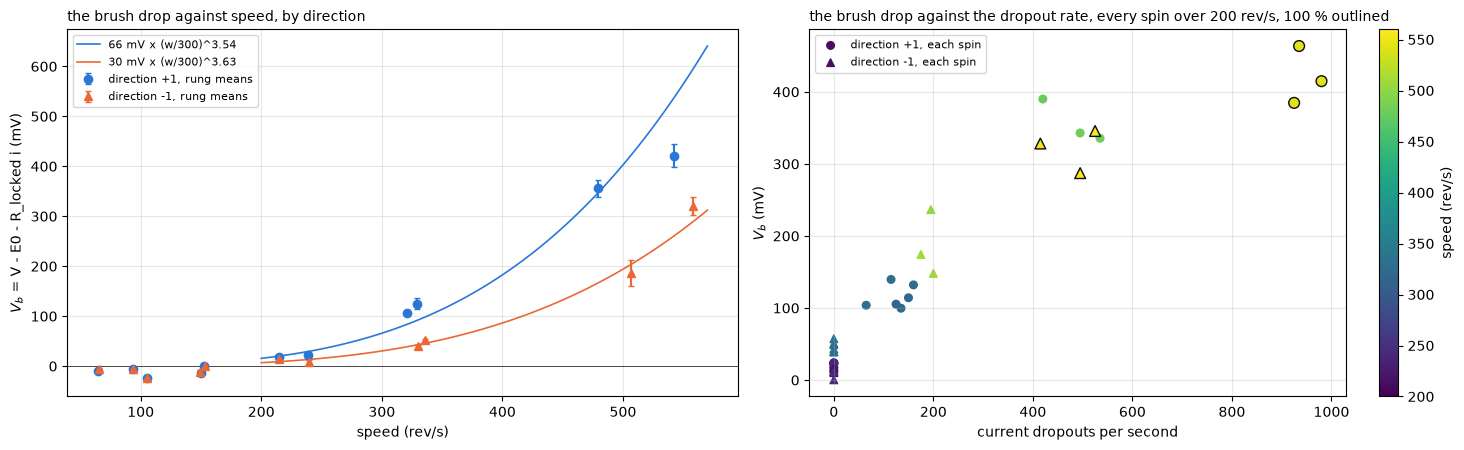

In [26]:
# the brush drop per rung and direction, its power law above 200 rev/s, and what it tracks
XR = bd.excess_by_rung(C1, TB["speed-torque"])
print(XR[["src", "dir", "rev_s", "i_ma", "x_b", "x_a", "x_se", "dropouts", "bias_pct"]].round(1).to_string(index=False))
for lv in (5.0, 7.4):
    h = XR[XR["src"].str.startswith(f"{lv:g} V") & (XR["rev_s"] < bd.LOW)]
    print(f"under {bd.LOW:.0f} rev/s at {lv:g} V: route b {h['x_b'].min():+.1f} to {h['x_b'].max():+.1f} mV, route a {h['x_a'].min():+.1f} to "
          f"{h['x_a'].max():+.1f} mV, se {h['x_se'].min():.1f} to {h['x_se'].max():.1f} mV")
lo7 = C1[(C1["level"] == 7.4) & (C1["spin_rev_s"] < bd.LOW)]
print(f"the 7.4 V tap's ON-edge lag spans {mm.ST['tap_on_edge_lag_7v4']['hi'] - mm.ST['tap_on_edge_lag_7v4']['lo']:.0f} ticks in sample-timing's bounds, "
      f"{(lo7['edge_ohm_per_tick'] * lo7['i_b']).mean():.1f} mV of V - E a tick at those rungs; the edge band +/-{bd.DELTA_SYS_MV:.0f} mV against the fold's "
      f"{EC[7.4][0]:+.1f} mV at 7.4 V")
HI = XR[XR["rev_s"] > 200]
FITS = {lab: bd.power_law(h) for lab, h in (("both", HI), ("+1", HI[HI["dir"] > 0]), ("-1", HI[HI["dir"] < 0]))}
for lab, f in FITS.items():
    print(f"power law above 200 rev/s, {lab}: V_b = {f['mv_300']:.0f} mV x (w / 300 rev/s)^{f['exponent']:.2f} (+/- {f['exponent_se']:.2f}); "
          f"1 % of the EMF at {f['one_pct_rev_s']:.0f} rev/s")
fd = bd.wls(HI["dropouts"], HI["x_b"])
print(f"V_b against the dropout rate above 200 rev/s: {fd['b'] * 100:.1f} +/- {fd['se_b'] * 100:.1f} mV per 100 dropouts/s, corr "
      f"{np.corrcoef(HI['dropouts'], HI['x_b'])[0, 1]:.2f}; against speed corr {np.corrcoef(HI['rev_s'], HI['x_b'])[0, 1]:.2f}")
for (lv, du), g in C1[C1["spin_rev_s"] > 300].groupby(["level", "duty"]):
    f = bd.wls(g["dropouts_per_s"], g["excess_mv_b"])
    print(f"  inside {lv:g} V {du} %: {g['dropouts_per_s'].min():.0f} to {g['dropouts_per_s'].max():.0f} dropouts/s, {f['b'] * 100:+.1f} +/- {f['se_b'] * 100:.1f} mV "
          f"per 100/s (corr {np.corrcoef(g['dropouts_per_s'], g['excess_mv_b'])[0, 1]:.2f}), dropouts against speed corr "
          f"{np.corrcoef(g['dropouts_per_s'], g['spin_rev_s'])[0, 1]:+.2f}")
quiet = C1[(C1["dir"] < 0) & (C1["spin_rev_s"] > 300) & (C1["spin_rev_s"] < 400)]
print(f"direction -1 at {quiet['spin_rev_s'].min():.0f} to {quiet['spin_rev_s'].max():.0f} rev/s: {quiet['dropouts_per_s'].max():.0f} dropouts/s at most, "
      f"V_b {quiet.groupby(['level', 'duty'])['excess_mv_b'].mean().min():.0f} to {quiet.groupby(['level', 'duty'])['excess_mv_b'].mean().max():.0f} mV")
i100, x100 = STF["i"].mean() * 1e-3, X100.mean() * 1e-3
print(f"at 100 %: {x100 * 1e3:.0f} mV as plain interruption needs the path open {bd.open_share(x100, bd.R_LOCKED, i100) * 100:.0f} % of the time; "
      f"the dropout rows are {STF['dropouts_per_s'].min() / mm.FS * 100:.1f} to {STF['dropouts_per_s'].max() / mm.FS * 100:.1f} % of the rows")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
ww = np.linspace(200, 570, 100)
for d, c, mk in ((1, BLUE, "o"), (-1, ORANGE, "^")):
    h = XR[XR["dir"] == d]
    ax[0].errorbar(h["rev_s"], h["x_b"], yerr=h["x_se"], fmt=mk, ms=6, capsize=2, color=c, label=f"direction {d:+d}, rung means")
    f = FITS[f"{d:+d}"]
    ax[0].plot(ww, bd.v_b(ww, f["mv_300"], f["exponent"]), "-", color=c, lw=1.2,
               label=f"{f['mv_300']:.0f} mV x (w/300)^{f['exponent']:.2f}")
ax[0].axhline(0, color=INK, lw=0.5)
ax[0].set_xlabel("speed (rev/s)"); ax[0].set_ylabel("$V_b$ = V - E0 - R_locked i (mV)"); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=8)
ax[0].set_title("the brush drop against speed, by direction", loc="left", fontsize=10)
for d, c, mk in ((1, BLUE, "o"), (-1, ORANGE, "^")):
    h = C1[(C1["dir"] == d) & (C1["spin_rev_s"] > 200)]
    sc = ax[1].scatter(h["dropouts_per_s"], h["excess_mv_b"], c=h["spin_rev_s"], cmap="viridis", vmin=200, vmax=560, marker=mk, s=30, label=f"direction {d:+d}, each spin")
    h = STF[STF["dir"] == d]
    ax[1].scatter(h["dropouts_per_s"], h["excess_mv"], c=h["spin_rev_s"], cmap="viridis", vmin=200, vmax=560, marker=mk, s=60, edgecolor=INK)
plt.colorbar(sc, ax=ax[1], label="speed (rev/s)")
ax[1].set_xlabel("current dropouts per second"); ax[1].set_ylabel("$V_b$ (mV)"); ax[1].grid(alpha=0.3); ax[1].legend(fontsize=8)
ax[1].set_title("the brush drop against the dropout rate, every spin over 200 rev/s, 100 % outlined", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

On the left $V_b$ stays near zero to about 200 rev/s and then rises steeply, direction +1 above -1. On the right it climbs with the dropouts, while the direction -1 spins near 330 rev/s already carry tens of millivolts with none. Below 160 rev/s $V_b$ reads -9.0 to +0.7 mV at 5 V by route b and -11.0 to +2.8 by route a, and -23.6 to -10.9 mV at 7.4 V by route b and -19.2 to -1.3 by route a, the 7.4 V values well past their standard errors of 1 to 4 mV. Above it, +16 mV at 215 to 240 rev/s, +73 to +89 mV at 325 to 332 rev/s, +271 mV at 493 rev/s and +371 mV at 550 rev/s. Above 200 rev/s it follows

$$V_b \approx 45\ \mathrm{mV} \times \left(\frac{\omega}{300\ \mathrm{rev/s}}\right)^{3.55 \pm 0.42}$$

and reaches 1 % of the EMF at about 230 rev/s, moderate confidence on the form, which is a fit and not a law. The fit is a line in logs, unweighted, over every rung above 200 rev/s, so the 8 to 23 mV rungs at 215 to 240 rev/s, which carry systematics of about 10 mV, pull on it as much as the 300 mV ones, and the exponent's $\pm$0.42 is the line's scatter alone and understates its error. Direction +1 carries about twice as much as -1, 66 against 30 mV at 300 rev/s with exponents of 3.54 and 3.63, and bemf-coast's lead swap put the direction split in the motor, high confidence there. The 45 mV of both directions together is close to the geometric mean of the two, $\sqrt{66 \times 30}$ = 44 mV, a value neither direction reads.

Below 160 rev/s, then, $V_b$ is within about 10 mV of zero at 5 V and carries a systematic of about 10 to 25 mV at 7.4 V, a rail term, the 7.4 V rungs reading 10 to 20 mV under the 5 V ones at similar speed by route b. It is the size of the 7.4 V tap's ON-edge lag uncertainty, sample-timing's bounds spanning 26 ticks at about 3 mV a tick at those rungs, and of the crest term's split by rail, and these data do not say which, so it belongs to the construction at 7.4 V and not to the motor, moderate confidence. The current's zero is not it: the dropout rows below put a driven bridge 3.3 mA over the board's zero at 7.4 V, but carried through the crest term, which was fitted over the same zero, it leaves the floor where it is, and route a, which reads no current zero, shows the same floor. The $\pm$5 mV band on $\delta$ does not cover it. That band was set from the 5 V fold and the dead-time dip, beside a fold that measured +19 mV at 7.4 V.

$V_b$ tracks the dropouts. Above 200 rev/s it rises 48 mV per 100 dropouts a second, a correlation of 0.95, and inside one rung 48 to 58 mV per 100/s, a correlation of 0.87 to 0.99, where the slower spins are the ones that drop out. But direction -1 at 330 rev/s carries 40 to 52 mV with no dropouts, so the visible openings are not the whole of it. At 100 % they cannot carry it. A path that stands open a share $f$ of the time with the drive held gives $V - E = R\,i/(1 - f)$, so 371 mV needs the path open 43 % of the time, against dropout rows that are 2.1 to 4.9 % of all rows. Plain interruption is too small by an order, moderate to high confidence. A speed observer that subtracts $R\,i$ from the terminal volts and leaves $V_b$ in over-reads the speed by $V_b/E$, about 1 % at 230 rev/s, 3 to 5 % at 325 to 335 rev/s and 8 to 10 % at 490 to 560 rev/s, and the free shaft's top speed sits inside that range.

### The driven zero from the dropout rows

The section on the current's zero left two zeros standing for the spinning motor's crest, the board's and the open bridge's, and the captures already hold the reading that picks one. A dropout row is a period whose crest sample sits under a quarter of the window's mean, the brush path open for the period. Inside it the winding current is zero while the bridge drives, so the raw crest sample less the torque-off zero reads the zero a driven bridge sits on, at the rail of the run, on the motor itself and with no meter. The cell takes the deep rows, under 0.10 of the window's mean, over the last 200 ms of each spin of capture-1, high-1 and speed-torque, keeps the spins with at least five, and pools the per-spin medians by rail. A period where the contact reseats before the crest sample reads above the floor, so the median leans a little high and the spin's 10th percentile is the floor's estimate. Then it carries the zero into $G_\mathrm{spin}$, the no-meter term at 7.4 V and the low-speed $V_b$.

                             spins  deep_rows  dropout_rows  window_counts  deep_median  deep_p10  dropout_median
run          level duty dir                                                                                      
capture-1    5.0   60    1       3         56            68          111.9          5.5       5.0             6.0
             7.4   40    1       3         81            82          128.3          9.0       7.6             9.0
                   60   -1       3        106           114          130.4          9.0       8.0             9.0
                         1       3        270           290          139.7          9.5       8.0            10.0
high-1       5.0   80   -1       3        104           143           98.8          6.0       5.0             7.0
                   100  -1       3        331           438           96.7          6.0       5.0             7.0
                         1       3        200           285           96.7          6.0 

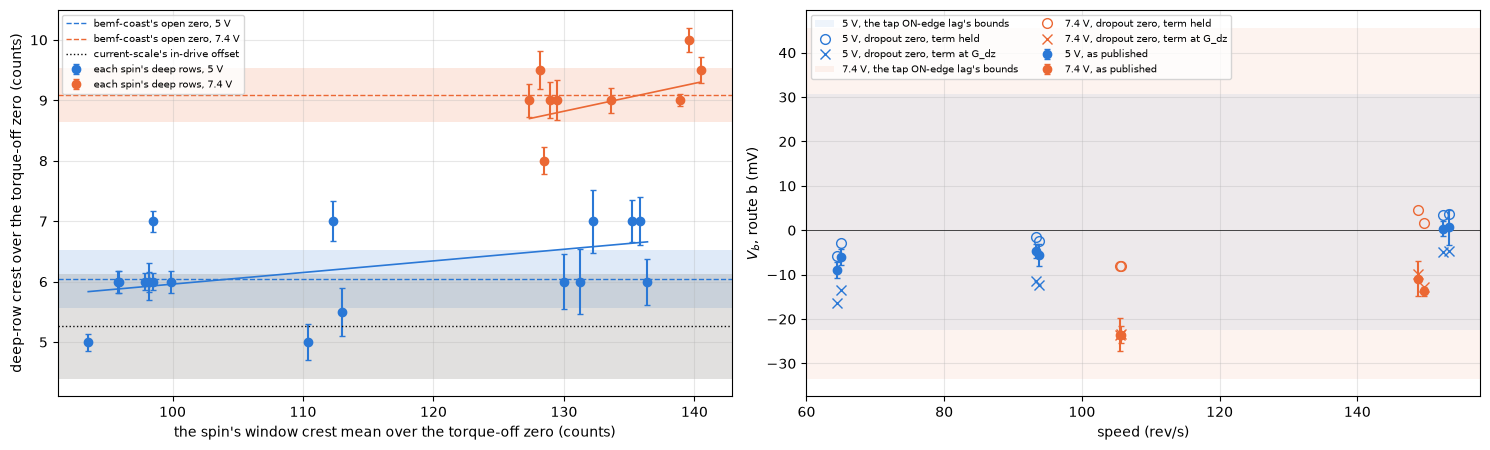

In [27]:
# the zero a driven bridge sits on, read on the motor: in a dropout row the brush path is open for the period, so the
# winding current is zero while the bridge drives and the raw crest over the torque-off zero is that zero, at the run's
# rail. The deep rows, under 0.10 of the window's mean over each spin's last 200 ms, per spin, pooled by rail
DROP = pd.concat([TB[r] for r in ("capture-1", "high-1", "speed-torque")], ignore_index=True)
DROP["mean_counts"] = DROP["i_crest_200"] * mm.CPA * 1e-3 + bd.DRIVE_OFF        # the window's crest mean over the torque-off zero
DROP = DROP[DROP["rows_under_0p10"] >= 5].copy()
# a spin's median read to 1.25 sd / sqrt(n), its rows' sd from their 10-90 % spread, floored at a count's quantization
DROP["se"] = 1.2533 * np.maximum((DROP["deep_zero_p90_counts"] - DROP["deep_zero_p10_counts"]) / 2.563, 1 / np.sqrt(12)) / np.sqrt(DROP["rows_under_0p10"])
print(DROP.groupby(["run", "level", "duty", "dir"]).agg(
    spins=("k", "size"), deep_rows=("rows_under_0p10", "sum"), dropout_rows=("dropouts_200", lambda x: int(round((x * 0.2).sum()))),
    window_counts=("mean_counts", "mean"), deep_median=("deep_zero_med_counts", "median"), deep_p10=("deep_zero_p10_counts", "median"),
    dropout_median=("dropout_zero_med_counts", "median")).round(1).to_string())
CSO, OZL = mm.CS["drive_offset_counts"], mm.BEMF["open_zero_counts_by_level"]
DRZ = {}
for lv, g in DROP.groupby("level"):
    m = g["deep_zero_med_counts"]
    f = bd.wls(g["mean_counts"], m, 1 / g["se"] ** 2)
    DRZ[lv] = dict(med=float(m.median()), p10=float(np.percentile(m, 10)), p90=float(np.percentile(m, 90)), floor=float(g["deep_zero_p10_counts"].median()),
                   spins=len(g), rows=int(g["rows_under_0p10"].sum()), fit=f, lo_i=g["mean_counts"].min(), hi_i=g["mean_counts"].max())
    oz = OZL[f"{lv:g} V"]
    print(f"{lv:g} V: the deep rows read {DRZ[lv]['med']:.1f} counts (10-90 % over spins {DRZ[lv]['p10']:.1f} to {DRZ[lv]['p90']:.1f}, the spins' 10th percentile "
          f"{DRZ[lv]['floor']:.1f}) over {len(g)} spins and {DRZ[lv]['rows']} rows; current-scale's in-drive offset {CSO['value']:.2f} ({CSO['lo']:.2f} to "
          f"{CSO['hi']:.2f}), bemf-coast's open zero {oz['value']:.2f} ({oz['lo']:.2f} to {oz['hi']:.2f}); against the window current "
          f"{f['b'] * 100:+.1f} +/- {f['se_b'] * 100:.1f} counts per 100 counts over {g['mean_counts'].min():.0f} to {g['mean_counts'].max():.0f} counts")
f5, i7 = DRZ[5.0]["fit"], DROP.loc[DROP["level"] == 7.4, "mean_counts"].mean()
x5 = np.array([1.0, i7])
X5 = DROP[DROP["level"] == 5.0]
X = np.c_[np.ones(len(X5)), X5["mean_counts"]]
cv = np.linalg.inv(X.T @ ((1 / X5["se"].to_numpy() ** 2)[:, None] * X)) * max(f5["chi2"], 1.0)
print(f"at the 7.4 V spins' mean window current, {i7:.0f} counts, the 5 V line reads {f5['a'] + f5['b'] * i7:.1f} +/- {np.sqrt(x5 @ cv @ x5):.1f} counts "
      f"against {DRZ[7.4]['med']:.1f} at 7.4 V")

# what the dropout zero moves: each point's gap and crest current by (dropout zero - in-drive offset) / CPA at its rail
dz_ma = lambda lv, k="med": (DRZ[lv][k] - bd.DRIVE_OFF) / mm.CPA * 1e3
GAP_DZ = {k: (PTS["gap"] - PTS["level"].map(lambda lv: dz_ma(lv, k))).to_numpy() for k in ("med", "floor")}
G_DZ = {(k, s): fit_g(GAP_DZ[k], sel) for k in ("med", "floor") for s, sel in (
    ("all", ALL), ("meter", MET), ("5 V", (PTS["level"] == 5.0).to_numpy()), ("7.4 V", (PTS["level"] == 7.4).to_numpy()))}
for k, lab in (("med", "the median"), ("floor", "the 10th percentile")):
    print(f"G_spin by the dropout zero at {lab} ({dz_ma(5.0, k):+.2f} mA at 5 V, {dz_ma(7.4, k):+.2f} mA at 7.4 V over the board's zero): all "
          f"{G_DZ[(k, 'all')][0] * 1e3:.2f} +/- {G_DZ[(k, 'all')][1] * 1e3:.2f} mS (chi2/dof {G_DZ[(k, 'all')][2]:.1f}), meter points "
          f"{G_DZ[(k, 'meter')][0] * 1e3:.2f} +/- {G_DZ[(k, 'meter')][1] * 1e3:.2f}, 5 V {G_DZ[(k, '5 V')][0] * 1e3:.2f}, 7.4 V {G_DZ[(k, '7.4 V')][0] * 1e3:.2f} mS; "
          f"over the locked fast-decay fit {(G_DZ[(k, 'all')][0] / g_fast - 1) * 100:+.0f} %")
g_dz = G_DZ[("med", "all")][0]
print("capture-1 at 7.4 V up to 30 %, measured and modeled term by the dropout zero: " + ", ".join(
    f"{du} % {GAP_DZ['med'][i]:.1f} and {a_[i] + b_[i] * g_dz:.1f}" for i, du in zip(np.flatnonzero(c7), PTS.loc[c7, "duty"])) + " mA")
# the grid's term is close to linear in G, so a cell at G_dz is its central value moved along its G_spin + se step
NM = GRID[GRID["loop"] == "no meter"].assign(term_dz=lambda t: t["RGb"] + t["gse"] / G_SPIN_SE * (g_dz - G_SPIN))
g7 = NM[(NM["rail"] == 7.4) & NM["duty"].between(15, 30)]
print("the no-meter grid at 7.4 V by the board's zero / by the dropout zero: " + ", ".join(f"{r['duty']} % {r['RGb']:.1f} / {r['term_dz']:.1f}" for _, r in g7.iterrows()) + " mA")

# the low-speed V_b floor: a crest current read high by d over-subtracts R_locked d. Route b with the term held as
# published, and with the term at G_dz, the same zero on both sides of the gap; route a carries no current zero
shift_mv = {lv: bd.R_LOCKED * dz_ma(lv) for lv in (5.0, 7.4)}
raw = TB["capture-1"].copy()
raw["i_crest_200"] -= raw["level"].map(dz_ma)
st_dz = TB["speed-torque"].assign(i_crest_50=lambda t: t["i_crest_50"] - dz_ma(5.0))
C1_DZ, _ = bd.per_spin(raw)
XR_HELD = bd.excess_by_rung(C1_DZ, st_dz)
kept = dict(bd.CARRIED)
try:
    bd.carry(coast_over_meter=kept["coast_over_meter"], full_duty_term_ma=kept["full_duty_term_ma"],
             crest_less_mean_ma={f"{v:g} V": {f"{r['duty']} %": q(r["term_dz"], r["lo"] + r["term_dz"] - r["RGb"], r["hi"] + r["term_dz"] - r["RGb"], "mA")
                                              for _, r in g.iterrows()} for v, g in NM.groupby("rail")})
    XR_REFIT = bd.excess_by_rung(bd.per_spin(raw)[0], st_dz)
finally:
    bd.carry(**kept)
FL = XR[["src", "dir", "rev_s", "x_b", "x_a", "x_se"]].merge(XR_HELD[["src", "dir", "x_b"]].rename(columns={"x_b": "held"}), on=["src", "dir"]).merge(
    XR_REFIT[["src", "dir", "x_b"]].rename(columns={"x_b": "refit"}), on=["src", "dir"])
FL = FL[(FL["rev_s"] < bd.LOW) & (FL["src"] != "100 %")].assign(level=lambda t: t["src"].str.split(" ").str[0].astype(float))
print(FL.round(1).to_string(index=False))
v_tick = {lv: C1[(C1["level"] == lv) & (C1["spin_rev_s"] < bd.LOW)]["v_on"].mean() / mm.P * 1e3 for lv in (5.0, 7.4)}
lag = {lv: (np.interp(lv, bd.RAILS, (mm.ST["tap_on_edge_lag_3v7"][k], mm.ST["tap_on_edge_lag_7v4"][k])) for k in ("lo", "value", "hi")) for lv in (5.0, 7.4)}
# where a V_b of zero reads with the true ON edge anywhere in sample-timing's bounds: an edge later than the one the
# construction takes leaves less ON time than it counts, and V_b reads high
EDGE_BAND = {lv: (-(mid - lo) * v_tick[lv], (hi - mid) * v_tick[lv]) for lv, (lo, mid, hi) in lag.items()}
for lv in (5.0, 7.4):
    h = FL[FL["level"] == lv]
    print(f"{lv:g} V under {bd.LOW:.0f} rev/s: the zero shift R_locked d {shift_mv[lv]:+.1f} mV; V_b route b {h['x_b'].min():+.1f} to {h['x_b'].max():+.1f} mV as "
          f"published, {h['held'].min():+.1f} to {h['held'].max():+.1f} by the dropout zero with the term held, {h['refit'].min():+.1f} to {h['refit'].max():+.1f} "
          f"with the term at G_dz; route a {h['x_a'].min():+.1f} to {h['x_a'].max():+.1f}; the tap ON-edge lag's bounds {EDGE_BAND[lv][0]:+.0f} to "
          f"{EDGE_BAND[lv][1]:+.0f} mV ({v_tick[lv]:.2f} mV a tick)")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
for lv, c in ((5.0, BLUE), (7.4, ORANGE)):
    g = DROP[DROP["level"] == lv]
    oz = OZL[f"{lv:g} V"]
    ax[0].axhspan(oz["lo"], oz["hi"], color=c, alpha=0.15, lw=0)
    ax[0].axhline(oz["value"], color=c, lw=1, ls="--", label=f"bemf-coast's open zero, {lv:g} V")
    ax[0].errorbar(g["mean_counts"], g["deep_zero_med_counts"], yerr=g["se"], fmt="o", ms=6, capsize=2, color=c, label=f"each spin's deep rows, {lv:g} V")
    xx = np.array([DRZ[lv]["lo_i"], DRZ[lv]["hi_i"]])
    ax[0].plot(xx, DRZ[lv]["fit"]["a"] + DRZ[lv]["fit"]["b"] * xx, "-", color=c, lw=1.2)
ax[0].axhspan(CSO["lo"], CSO["hi"], color=MUTED, alpha=0.25, lw=0)
ax[0].axhline(CSO["value"], color=INK, lw=1, ls=":", label="current-scale's in-drive offset")
ax[0].set_xlabel("the spin's window crest mean over the torque-off zero (counts)")
ax[0].set_ylabel("deep-row crest over the torque-off zero (counts)"); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=7)
for lv, c in ((5.0, BLUE), (7.4, ORANGE)):
    h = FL[FL["level"] == lv]
    ax[1].axhspan(*EDGE_BAND[lv], color=c, alpha=0.08, lw=0, label=f"{lv:g} V, the tap ON-edge lag's bounds")
    ax[1].errorbar(h["rev_s"], h["x_b"], yerr=h["x_se"], fmt="o", ms=6, capsize=2, color=c, label=f"{lv:g} V, as published")
    ax[1].plot(h["rev_s"], h["held"], "o", ms=7, mfc="none", color=c, label=f"{lv:g} V, dropout zero, term held")
    ax[1].plot(h["rev_s"], h["refit"], "x", ms=7, color=c, label=f"{lv:g} V, dropout zero, term at G_dz")
ax[1].axhline(0, color=INK, lw=0.5)
ax[1].set_xlabel("speed (rev/s)"); ax[1].set_ylabel("$V_b$, route b (mV)")
ax[1].grid(alpha=0.3); ax[1].legend(fontsize=7, ncol=2, loc="upper left")
plt.tight_layout(); plt.show()

On the left the two rails sit on bemf-coast's open bridge's zero and not on current-scale's in-drive offset. At 5 V the deep rows read 6.0 counts over the torque-off zero, 5.3 to 7.0 across 18 spins and 1290 rows, against an open zero of 6.04 and an in-drive offset of 5.26. At 7.4 V they read 9.0 counts, 8.8 to 9.6 across 9 spins and 457 rows, against an open zero of 9.09. The spins' 10th percentiles, the floor, read 5.0 and 8.0 counts. Within a rail the reading barely follows the window current, +1.9 $\pm$ 1.2 counts per 100 counts at 5 V over 94 to 136 counts, under a count across the span, and +4.6 $\pm$ 3.2 at 7.4 V over 127 to 140. Across the rails the same window current reads differently, the 5 V line reading 6.6 $\pm$ 0.4 counts at the 7.4 V spins' mean of 133 counts against their 9.0. So the reading follows the rail and not the residue of the previous period's current. A driven bridge sits on the open bridge's zero, and the board's zero reads the crest current high by 3.7 counts, 3.3 mA, at 7.4 V and by 0.7 counts, 0.65 mA, at 5 V.

That leaves a tension at 5 V. High-1 at 100 % on 5 V, nothing switching, reads the board 0.13 mA under the meter by the board's zero and 0.82 mA under it by the open zero, so there the meter sides with the board's zero by about 0.7 mA, under a count. The cleaner chi2 by the board's zero pools both rails. Neither is at 7.4 V, where the zeros part by 3.3 mA and the dropout rows read the open one directly.

Three things move with it. By the dropout zero, each spinning point's gap moved by its rail's zero less the in-drive offset, $G_\mathrm{spin}$ reads 2.79 $\pm$ 0.10 mS over all 18 points at a chi2 per point of 2.4, 3.01 mS at 5 V and 2.70 mS at 7.4 V, and 2.62 $\pm$ 0.16 mS on the meter points alone, against the locked fast-decay fit's 2.49. That is 12 % over the locked fit where the board's zero read 34 %, and the meter points within their error of it. At the spins' floor it reads 3.00 and 2.85 mS. The no-meter term at 7.4 V and 15 to 30 % falls to 25.9 to 27.4 mA measured and 24.8 to 26.2 modeled on capture-1, and the grid's cells there from 28.3 to 29.1 mA to 25.1 to 26.5 mA.

On the right is the low-speed $V_b$. A crest current read high by $d$ makes route b subtract $R_\mathrm{locked}\,d$ too much, 2.9 mV at 5 V and 14.7 mV at 7.4 V. With the crest term held as published, that takes the floor under 160 rev/s from -23.6 to -10.9 mV to -8.0 to +4.5 mV at 7.4 V, and from -9.0 to +0.7 mV to -5.9 to +3.7 mV at 5 V. Route b's term is the grid's, though, fitted to gaps read over the same zero. Carried to $G_\mathrm{spin}$ by the dropout zero it falls at 7.4 V about as much as the crest does, and the floor reads -23.5 to -9.8 mV at 7.4 V and -16.3 to -4.6 mV at 5 V. Route a, the coast's drag times the meter's scale, reads no current zero and stays at -19.2 to -1.3 mV at 7.4 V. So the zero moves route b's floor only while the term stays on the board's zero. Every version sits inside the tap ON-edge lag's bounds, -33 to +46 mV at 7.4 V and -23 to +31 mV at 5 V.

High confidence that a driven bridge sits on the open bridge's zero at 7.4 V, and moderate at 5 V, where the two zeros are within a count and the meter at 100 % leans the other way by 0.7 mA. A DMM in series at 7.4 V, the board's crest sample against the meter at 100 % and at the meter points' duties, confirms it independently.

### Chord against incremental R

Earlier work on another MG90 found 6.2 to 7.5 ohm in rotation, read as an incremental R from duty steps. The slope across capture-1's rungs is the same kind of read. The cell fits $V - E_0$ against the current across the rungs of one rail, with the construction over the crest less its term, over the raw crest, and as duty times the crest volts over the raw crest, sets each beside the chords of the same rungs and the incremental R at fixed speed, and sizes the rise of $V_b$ across the rungs against their current lever. It also models what a duty-step read 0.3 to 3 ms after the step carries from the step's own dynamics on this motor's constants.

In [28]:
# the slope of V - E0 on i across the rungs of one rail, against the chord of the same rungs: on a free shaft the rungs move
# speed and current together, so the slope runs along the drag curve and not at fixed speed
C1["ve_b"] = C1["v_mean_b"] - C1["e_cut"]
C1["ve_naive"] = C1["duty_applied_pct"] / 100 * C1["v_on"] - C1["e_cut"]       # duty x V_crest, no edges, no brake
for lv, g0 in C1.groupby("level"):
    for lab, g in (("15 to 30 %", g0[g0["duty"] <= 30]), ("all five rungs", g0)):
        for vcol, icol, name in (("ve_b", "i_b", "construction over crest less term"), ("ve_b", "i_crest", "construction over the raw crest"),
                                 ("ve_naive", "i_crest", "duty x V_crest over the raw crest")):
            if lab == "all five rungs" and name != "construction over crest less term":
                continue
            agg = g.groupby("duty").agg(x=(icol, "mean"), y=(vcol, "mean"), sy=(vcol, lambda s: s.std() / np.sqrt(len(s))), w=("spin_rev_s", "mean"))
            f = bd.wls(agg["x"] * 1e-3, agg["y"], 1 / agg["sy"] ** 2)
            chord = agg["y"] / (agg["x"] * 1e-3)
            print(f"{lv:g} V, {lab}, {name}: slope {f['b']:.2f} +/- {f['se_b']:.2f} ohm; chords {chord.min():.2f} to {chord.max():.2f} ohm "
                  f"over {agg['x'].min():.0f} to {agg['x'].max():.0f} mA and {agg['w'].min():.0f} to {agg['w'].max():.0f} rev/s")
    lo3 = g0[g0["duty"] <= 30].groupby("duty")
    lever, rise = lo3["i_b"].mean().iloc[-1] - lo3["i_b"].mean().iloc[0], lo3["excess_mv_b"].mean().iloc[-1] - lo3["excess_mv_b"].mean().iloc[0]
    print(f"  {lv:g} V: V_b rises {rise:+.0f} mV from 15 to 30 % over a current lever of {lever:.1f} mA, {rise / lever:+.2f} ohm of slope")
print(f"at fixed speed: the incremental R {RI:.2f} ohm, se {RI_SE:.3f}")
for lab, l_h in (("motor-model's L0", PT[(PT["set"] == "motor") & (PT["param"] == "l0")]["value"].iloc[0] * 1e-3), ("inductance's l_mh", bd.IND["l_mh"]["value"] * 1e-3)):
    print(f"a duty-step read of dV/di, {lab} {l_h * 1e3:.3f} mH: " + ", ".join(
        f"{t * 1e3:.1f} ms after the step {bd.step_read(l_h, t):.2f} x R" for t in (0.3e-3, 1e-3, 3e-3)))

5 V, 15 to 30 %, construction over crest less term: slope 4.97 +/- 0.17 ohm; chords 4.30 to 4.46 ohm over 47 to 64 mA and 65 to 153 rev/s
5 V, 15 to 30 %, construction over the raw crest: slope 4.88 +/- 0.16 ohm; chords 3.06 to 3.42 ohm over 66 to 83 mA and 65 to 153 rev/s
5 V, 15 to 30 %, duty x V_crest over the raw crest: slope 4.95 +/- 0.17 ohm; chords 4.03 to 4.20 ohm over 66 to 83 mA and 65 to 153 rev/s
5 V, all five rungs, construction over crest less term: slope 5.56 +/- 0.42 ohm; chords 4.30 to 5.55 ohm over 47 to 81 mA and 65 to 332 rev/s
  5 V: V_b rises +8 mV from 15 to 30 % over a current lever of 16.5 mA, +0.49 ohm of slope
7.4 V, 15 to 30 %, construction over crest less term: slope 6.77 +/- 0.48 ohm; chords 4.04 to 4.67 ohm over 56 to 72 mA and 106 to 239 rev/s
7.4 V, 15 to 30 %, construction over the raw crest: slope 6.40 +/- 0.59 ohm; chords 2.68 to 3.33 ohm over 84 to 101 mA and 106 to 239 rev/s
7.4 V, 15 to 30 %, duty x V_crest over the raw crest: slope 6.46 +/- 0.55 

Across the 15 to 30 % rungs the slope is 4.97 $\pm$ 0.17 ohm at 5 V and 6.77 $\pm$ 0.48 ohm at 7.4 V, and 5.56 and 7.16 ohm over all five rungs, while the chords of the same rungs are 4.0 to 4.7 ohm. On a free shaft the rungs move speed and current together, so the slope runs along the drag curve and not at fixed speed. A current lever of 16 to 17 mA then turns $V_b$'s rise of 8 to 39 mV across the rungs into +0.5 to +2.5 ohm of slope, which is what inflates it. At fixed speed the incremental R is the locked R plus 3 %. So on this motor an excess incremental R in rotation reads as the speed-set voltage and not as a drop that follows the current, moderate confidence, since the fixed-speed test runs only at 100 % and 180 to 420 rev/s.

The methods differ in two more ways. A duty step read 0.3 to 3 ms after the step carries 1.05 to 1.28 times R from the step's own electrical and mechanical rise when neither $L\,di/dt$ nor the EMF's rise is taken out, a model and not a measurement. Leaving the crest term out moves the slope by under 0.4 ohm, since the term per volt is nearly flat from 10 to 30 % and cancels in a difference at one rail, while the chord read that way falls a quarter to a third under. Whether the other MG90's fast incremental R is a contact effect that this run-up test does not see, under 200 rev/s and within 3 ms of a step, is open.

### The ripple tach, and the ident route

The coast gives the speed at the cut, but a running motor shows its own speed in the current's ripple, six events a revolution. The cell counts it with a seed that does not use the coast, a rough EMF speed $(D\,V_\mathrm{crest} - R_\mathrm{locked}\,i)/K_e$ that only needs to land within the band-pass's $\pm$35 %, moved to the strongest line within that range and then re-seeded from its own count until it stops moving. It holds the count against the coast-seeded one and reads $R = (\bar V - K_e\,\omega_\mathrm{ripple})/i$, a route that needs no coast and no pot.

In [29]:
# the ripple tach as the spin's own speed, seeded by a rough EMF speed and not by the coast, and the ident route
# R = (V_mean - Ke w_ripple) / i, which needs no coast
for run in ("capture-1", "speed-torque", "high-1"):
    T0 = TB[run]
    once = np.abs(T0["spin_rev_s_rough_once"] / T0["spin_rev_s"] - 1) * 100
    spec = np.abs(T0["spin_rev_s_rough"] / T0["spin_rev_s"] - 1) * 100
    print(f"{run}: against the coast-seeded count, one seeded count {once.max():.2f} % at most, with the spectral seed and re-seeding "
          f"{spec.max():.2f} % at most, median {spec.median():.4f} %")
C1["R_ident"] = (C1["v_mean_b"] - mm.KE * 2 * np.pi * C1["spin_rev_s_rough"]) / (C1["i_b"] * 1e-3)
C1["ident_less_b"] = C1["R_ident"] - C1["R_b"]
g = C1.groupby(["level", "duty"])
print(pd.DataFrame(dict(rev_s=g["spin_rev_s"].mean(), R_b=g["R_b"].mean(), R_ident=g["R_ident"].mean(), sd_ident=g["R_ident"].std(),
                        ident_less_b=g["ident_less_b"].mean(), sd_diff=g["ident_less_b"].std(),
                        ke_band_ohm=g.apply(lambda h: (0.005 * mm.KE * 2 * np.pi * h["spin_rev_s_rough"] / (h["i_b"] * 1e-3)).mean(), include_groups=False))).round(3).to_string())
print(f"ident less the coast route over all 60 spins: {C1['ident_less_b'].mean():+.3f} ohm (sd {C1['ident_less_b'].std():.3f}); at 100 % ident "
      f"{STF['R_ripple'].mean():.3f} ohm (sd {STF['R_ripple'].std():.3f}) against the coast's {STF['R'].mean():.3f}")

capture-1: against the coast-seeded count, one seeded count 0.53 % at most, with the spectral seed and re-seeding 0.27 % at most, median 0.0024 %
speed-torque: against the coast-seeded count, one seeded count 7.14 % at most, with the spectral seed and re-seeding 1.83 % at most, median 0.0392 %
high-1: against the coast-seeded count, one seeded count 35.25 % at most, with the spectral seed and re-seeding 51.60 % at most, median 0.0012 %
              rev_s    R_b  R_ident  sd_ident  ident_less_b  sd_diff  ke_band_ohm
level duty                                                                       
5.0   15     64.721  4.296    4.271     0.042        -0.025    0.094        0.050
      20     93.537  4.360    4.356     0.035        -0.005    0.037        0.064
      30    152.881  4.464    4.517     0.050         0.053    0.042        0.088
      40    214.574  4.690    4.734     0.096         0.044    0.093        0.115
      60    332.151  5.557    5.427     0.460        -0.130    0.163

The tach agrees with the coast-seeded count to 0.27 % at most, a median of 0.0024 %, over capture-1's 60 spins, including the 7.4 V 60 % spins where a free search's peak halves. Two failures are worth knowing. One seeded count with no spectral step slipped 7 % at 100 % in direction -1, where $V_b$ throws the rough seed 8 % off and about 500 dropouts a second leave the band-passed noise crossing at the filter's own center. With the spectral step one run-up of six still lands 1.8 % off. In high-1 the rough seed leaves out the meter's 9 ohm and lands on the 9/rev line, so the tach is not used there.

The ident route reads the coast route to -0.06 ohm, sd 0.15, spin by spin. Below 250 rev/s it is within -0.03 to +0.05 ohm by rung with a within-rung sd of 0.02 to 0.11 ohm, and at speed it runs low by 0.11 to 0.33 ohm, which is $K_e$'s fall with speed. $K_e$'s $\pm$0.5 % carries 0.05 to 0.19 ohm. The route needs no coast, and it inherits $V_b$ just as the coast route does, moderate confidence.

### What it physically is

Five readings fit some of what is measured. Each is set against the data.

| Reading | What it predicts | Against the data | Confidence |
|---|---|---|---|
| A contact or film voltage at the brushes that grows with bounce | a voltage set by the speed and roughly not by the current, rising as the contact bounces, following the rotor's direction | current-independent in the run-up test, tracks the dropouts, splits by direction | leading, moderate |
| Arcs at the bounces | about $\frac12 L i^2$ lost at each opening, times the openings a second | about 26 mV at 100 %, an order short of 371 mV | low |
| Commutation reactance | a drop in proportion to $i\,\omega$ | model B leaves 163 against 72 mV rms in the run-up test | rejected as the main part |
| Plain interruptions | the drive lost while the path stands open | the path open 43 % of the time at 100 %, against 2 to 5 % of rows | low as the main part, likely the dropout correlation inside a rung |
| A higher EMF under drive | an EMF over the coast's while current flows | reads the same as a contact voltage at the cut, since both vanish with the current, and forms that scale with the current are disfavored | low |

The teardown gives the brushes' geometry. Each brush is a strip of three parallel wire fingers, and the commutator carries three dark wear bands, one per finger (teardown, photo `07-brushes-and-commutator-end.jpg`). The two brushes sit in the end cap as mirror images through its center, so both see the same geometry in one direction of rotation and the mirror of it in the other. That gives a contact that depends on the direction, which matches the direction split that bemf-coast placed in the motor. A finger that lifts part of the way raises the contact's voltage without opening the circuit, and a full lift of all three fingers is a dropout. Each brush crosses three gaps a revolution, about 900 Hz at 300 rev/s, which approaches the range a fine wire finger's resonance could sit in. This paragraph is a reading of the geometry, not a result. No finger was measured, and nothing here tests a resonance.

Kesava Rao, on a 5 kW commutator machine with its field poles removed, found the contact drop rising with the commutator's speed, in proportion to it at a fixed current, and found no counter-EMF from retarded commutation [7]. Slip-ring work reviewed there put a sharp rise at high speed down to intermittent contact and an air film between brush and ring [7]. His rise grew with the current toward a constant, where the one here does not follow the current, so that work supports the speed dependence and not the form. Brush makers give the drop against current density and the friction loss against peripheral speed [8]. The cell sizes the arcs and the gap rate and shows the teardown's photo.

100 %, direction +1: 947 dropouts/s at 110 mA: arcs worth 26 mV at L0 0.505 mH (43 mV at inductance's 0.833 mH), against V_b 421 mV
100 %, direction -1: 478 dropouts/s at 107 mA: arcs worth 13 mV at L0 0.505 mH (21 mV at inductance's 0.833 mH), against V_b 320 mV
each brush crosses 3 gaps a revolution: 100 rev/s 300 Hz, 200 rev/s 600 Hz, 300 rev/s 900 Hz, 550 rev/s 1650 Hz


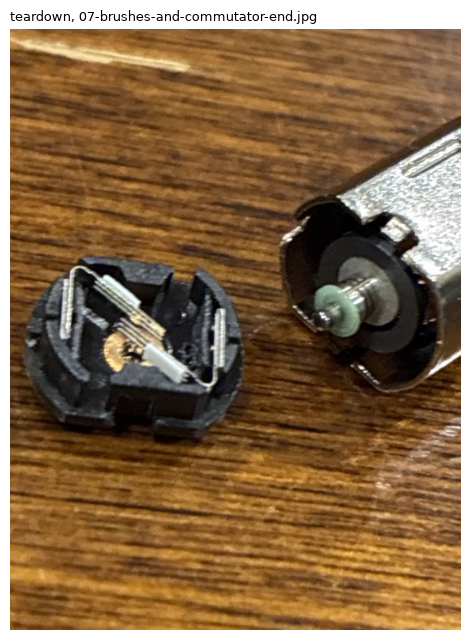

In [30]:
# what each candidate would need: the energy check for arcs at the openings, 1/2 L i^2 per opening times the openings per second
# as volts at the current, and the rate at which one brush crosses the commutator's gaps
L_ARC = PT[(PT["set"] == "motor") & (PT["param"] == "l0")]["value"].iloc[0] * 1e-3
for d in (1, -1):
    h = STF[STF["dir"] == d]
    print(f"100 %, direction {d:+d}: {h['dropouts_per_s'].mean():.0f} dropouts/s at {h['i'].mean():.0f} mA: arcs worth "
          f"{bd.arc_mv(L_ARC, h['i'].mean() * 1e-3, h['dropouts_per_s'].mean()):.0f} mV at L0 {L_ARC * 1e3:.3f} mH "
          f"({bd.arc_mv(bd.IND['l_mh']['value'] * 1e-3, h['i'].mean() * 1e-3, h['dropouts_per_s'].mean()):.0f} mV at inductance's {bd.IND['l_mh']['value']:.3f} mH), "
          f"against V_b {h['excess_mv'].mean():.0f} mV")
print(f"each brush crosses {mm.MOTOR.slots} gaps a revolution: " + ", ".join(f"{w} rev/s {bd.gap_hz(w):.0f} Hz" for w in (100, 200, 300, 550)))

# the teardown's photo of the end cap with its two brushes, beside the can with the commutator end
from PIL import Image
img = Image.open(results.ROOT / "telemetry" / mm.MOTOR.key / "teardown" / "photos" / "07-brushes-and-commutator-end.jpg")
img.thumbnail((700, 700))
fig, ax = plt.subplots(figsize=(5, 6.5))
ax.imshow(img); ax.set_axis_off()
ax.set_title("teardown, 07-brushes-and-commutator-end.jpg", loc="left", fontsize=9)
plt.tight_layout(); plt.show()

In the photo the end cap on the left holds the two brushes, each a strip of fingers, mirror images through the cap's center, and the can on the right shows the commutator end. At 100 % the arcs come to about 26 mV in direction +1 at the locked $L_0$ and 43 mV at inductance's period-fit $L$, against 421 mV, and to less in direction -1, an order short in both. So arcs at the visible openings do not carry $V_b$, moderate confidence. The gap rate runs from 300 Hz at 100 rev/s to 1650 Hz at 550 rev/s, and $V_b$ switches on above about 200 rev/s, 600 Hz. Nothing here ties the two.

### Folding it in

Two things above rest on a pairing or a term that $V_b$ touches.

The meter's resistance. The pairing above sets each meter point against capture-1 at the same rail and duty, which turns faster without the meter's 9 ohm, and so carries more $V_b$. Redone with $V_b$ in the pairing, each meter point's loop less the locked R less capture-1's $V_b$ at that point's own speed is the meter's R, and the 100 % run-ups' $V_b$ carries high-1's 100 % point. If $V_b$ is set by the speed, that gives one meter R across all six points.

The crest term. The spinning steady state solves for the EMF that makes the period-mean current equal the measured mean, so whatever volts $V_b$ takes are already inside that EMF, and the crest-term grid is unaffected by $V_b$ itself. Its meter loop and the spinning $G$ ran at the pairing's meter R, though, so the cell reruns the meter-loop grid and the spinning $G$ at the new meter R to size that.

In [31]:
# the meter's R redone with the brush drop in the pairing: each meter point's loop less the locked R less capture-1's V_b at the
# point's own speed (the 100 % run-ups' V_b carries it to high-1's 100 % point), against the pairing above at the same rail and duty
XC = C1.groupby(["level", "duty"]).agg(rev_s=("spin_rev_s", "mean"), x=("excess_mv_b", "mean")).reset_index()
XS = pd.concat([pd.DataFrame(dict(rev_s=XC["rev_s"], x=XC["x"] * 1e-3)),
                pd.DataFrame([dict(rev_s=STF["spin_rev_s"].mean(), x=X100.mean() * 1e-3)])]).sort_values("rev_s")
MP = bd.meter_points(TB, XS)
print(MP[["run", "level", "duty", "rev_s", "meter_ma", "r_loop", "r_loop_se", "x_c_at_w_mv", "r_meter_plain", "r_meter_vb", "dropouts"]].round(3).to_string(index=False))
R_M_VB, R_M_VB_SD = float(MP["r_meter_vb"].mean()), float(MP["r_meter_vb"].std())
m1 = MP[(MP["run"] == "meter-1") & (MP["rev_s"] < 120)].set_index("level")      # meter-1's two points at matched speed and current
print(f"meter-1's matched pair, 7.4 V 20 % less 5.0 V 30 %: {m1.loc[7.4, 'r_loop'] - m1.loc[5.0, 'r_loop']:+.3f} ohm "
      f"+/- {np.hypot(m1.loc[7.4, 'r_loop_se'], m1.loc[5.0, 'r_loop_se']):.3f}, {(m1.loc[7.4, 'r_loop'] - m1.loc[5.0, 'r_loop']) * m1['meter_ma'].mean():+.1f} mV of V - E")
print(f"the meter's R: the pairing at the same rail and duty above {R_M:.2f} (sd {R_M_SD:.2f}) over {len(MO)} points; the plain loop less the locked R "
      f"{MP['r_meter_plain'].mean():.2f} (sd {MP['r_meter_plain'].std():.2f}); with V_b in the pairing {R_M_VB:.2f} (sd {R_M_VB_SD:.2f}, "
      f"{MP[MP['duty'] < 100]['r_meter_vb'].std():.2f} at partial duty) over {len(MP)} points")
print("the pairing above sets each meter point against a capture-1 rung at another speed: " + ", ".join(
    f"{r.level:g} V {r.duty} % meter {SP[(SP['run'] != 'capture-1') & (SP['run'] != 'spinning-1') & (SP['level'] == r.level) & (SP['duty'] == r.duty)]['rev_s'].iloc[0]:.0f} "
    f"against capture-1 {SP[(SP['run'] == 'capture-1') & (SP['level'] == r.level) & (SP['duty'] == r.duty)]['rev_s'].iloc[0]:.0f} rev/s" for r in MO.itertuples()))

# what the new meter R would move: the crest term with the meter in the loop at the grid's cells, the central model, and the
# spinning G refitted with the meter points at the new loop R
jobs, tags = [], []
for v in (3.7, 5.0, 7.4, 8.4):
    for du in (10, 15, 20, 30, 40, 50, 60, 70, 80, 90):
        sh = mm.share(du)
        lo_, hi_ = 0.0, sh * v / mm.KE
        for _ in range(60):                                             # the speed where the drive's volts meet the drag's current
            om = 0.5 * (lo_ + hi_)
            if sh * v - mm.KE * om - drag(om) * 1e-3 * (R_MOT + R_M_VB) > 0:
                lo_ = om
            else:
                hi_ = om
        jobs.append((mm.steady_both, (dict(P_FAST[("RGb", 2)], g=G_SPIN, rs=R_MOT + R_M_VB), du, v, drag(om)), {})); tags.append(("grid", v, du))
mpts = PTS[PTS["loop"] == "meter"]
for i, r in mpts.iterrows():
    for gg in (0.0, 0.002):
        jobs.append((mm.steady_both, (dict(P_FAST[("RGb", 2)], g=gg, rs=R_MOT + R_M_VB), r["duty"], r["v_on"], r["mean"]), {})); tags.append(("lin", i, gg))
NEWM = dict(zip(tags, mm.run_parallel(jobs, chunksize=2)))
old = GRID[GRID["loop"] == "meter"].set_index(["rail", "duty"])
shift = np.array([NEWM[("grid", v, du)]["crest_less_mean"] - old.loc[(v, du), "RGb"] for v in (3.7, 5.0, 7.4, 8.4) for du in (10, 15, 20, 30, 40, 50, 60, 70, 80, 90)])
width = (old["hi"] - old["lo"]).to_numpy()
print(f"the meter-loop crest term at {R_M_VB:.2f} ohm against {R_M:.2f}: {shift.min():+.2f} to {shift.max():+.2f} mA over the grid, against band widths of "
      f"{width.min():.1f} to {width.max():.1f} mA")
ga, gb = GS[("RGb", 2)]["a"].copy(), GS[("RGb", 2)]["b"].copy()   # the term = ga + gb G at each point, the meter points rerun
for i in mpts.index:
    ga[i] = NEWM[("lin", i, 0.0)]["crest_less_mean"]
    gb[i] = (NEWM[("lin", i, 0.002)]["crest_less_mean"] - ga[i]) / 0.002
wgt = 1 / PTS["sig"].to_numpy() ** 2
G_NEW = np.sum(wgt * gb * (PTS["gap"].to_numpy() - ga)) / np.sum(wgt * gb ** 2)
print(f"G_spin with the meter points at {R_M_VB:.2f} ohm: {G_NEW * 1e3:.2f} mS against {G_SPIN * 1e3:.2f} +/- {G_SPIN_SE * 1e3:.2f} mS")

    run  level  duty   rev_s  meter_ma  r_loop  r_loop_se  x_c_at_w_mv  r_meter_plain  r_meter_vb  dropouts
meter-1    7.4    20  96.484    48.576  13.592      0.034       -9.625          9.136       9.334     0.000
meter-1    5.0    30  98.297    49.582  14.063      0.040      -12.390          9.608       9.857     0.000
meter-1    7.4    40 262.563    67.041  13.798      0.035       31.157          9.343       8.878     0.000
 high-1    5.0    60 269.075    66.170  14.291      0.073       35.551          9.836       9.298     6.667
 high-1    5.0    80 375.339    75.310  15.473      0.259      137.800         11.017       9.187   125.000
 high-1    5.0   100 480.152    81.514  18.074      0.256      256.732         13.619      10.469   602.500
meter-1's matched pair, 7.4 V 20 % less 5.0 V 30 %: -0.471 ohm +/- 0.053, -23.1 mV of V - E
the meter's R: the pairing at the same rail and duty above 8.87 (sd 0.62) over 4 points; the plain loop less the locked R 10.43 (sd 1.70); with V_b in t

the meter-loop crest term at 9.50 ohm against 8.87: +0.04 to +0.22 mA over the grid, against band widths of 0.7 to 5.4 mA
G_spin with the meter points at 9.50 ohm: 3.32 mS against 3.35 +/- 0.07 mS


The loop R by the meter's own current rises from 13.8 ohm at 97 rev/s to 18.1 ohm at 480 rev/s, a true series current showing the same rise. Meter-1's matched pair, 7.4 V 20 % less 5.0 V 30 % at 96 to 98 rev/s and 49 mA, reads -23.1 mV of V - E through the construction, the edge fold's size within the meter's wiring. The pairing above sets each meter point against a capture-1 rung that turns 53 to 63 rev/s faster. With $V_b$ in the pairing the meter reads 9.50 ohm with an sd of 0.57 over the six points, 0.35 at partial duty, against 10.43 with an sd of 1.70 for the plain loop less the locked R. So $V_b$ carries over to the runs with a true current, moderate to high confidence, and the pairing above most likely reads the meter about 0.6 ohm low, moderate confidence. `meter_loop_ohm` carries the new value. The pairing's 8.87 ohm and its four points stay printed in the coast section, since the crest term with the meter in the loop and the spinning $G$ were run on it. At the new meter R the meter-loop term moves by +0.04 to +0.22 mA over the grid, against band widths of 0.7 to 5.4 mA, and $G_\mathrm{spin}$ moves from 3.35 to 3.32 mS, under half its standard error, so `crest_less_meter_ma` and `g_spin_ms` stay as computed and are open to a rerun.

With $V_b$ the motor's equation reads

$$v = R\,i + L\,\frac{di}{dt} + K_e\,\omega + V_b(\omega, \mathrm{dir})$$

with $L$ the window model of this notebook, $R$ the locked R to within a few percent below 160 rev/s and at fixed speed, and $V_b$ a voltage set by the speed and the direction, about 45 mV $\times (\omega/300\ \mathrm{rev/s})^{3.55}$ above 200 rev/s, and under 160 rev/s within about 10 mV of zero at 5 V beside a 10 to 25 mV rail term of the construction at 7.4 V. A speed observer that subtracts $R\,i$ also needs $V_b$, indexed by speed and direction. An R learned by speed on a free shaft would instead over-correct under load by $i_\mathrm{free}/i_\mathrm{load}$, since $V_b$ does not scale with the current.

## Results

The result file carries the floor, the bare coil's, the can's and the motor's parameters with the ranges above, the rail test's edge currents and lines, each working model's chi2 with its largest held-out test, the offset's Shapley shares and the edge current, inductance's ratio and slide with the data beside the model, the spinning $G$ and its rms, the predicted crest sample less the period mean by rail and duty with and without the meter, the meter's resistance, the coast's scale to the meter, the 100 % term, drag and curve forms, the delta's spans, and the brush drop by rung and direction with its power law, the running R below 160 rev/s and at fixed speed, and the 100 % chord.

In [32]:
q = results.quantity
PTD = {(r.set, r.param): r for r in PT.itertuples()}


def ptq(s, n, unit):
    # a parameter at the joint fast + slow fit, rule 2, bounded by its range's union
    r = PTD[(s, n)]
    return q(r.value, r.lo, r.hi, unit)


def pm(v, e, unit):
    # a value with its standard error as the bounds
    return q(v, v - e, v + e, unit)


ra_edges = [r["edge_ma"] for r in RAIL[("ra", "RL")]["G"]["rows"]]
bare_line, can_line = RAIL[("bare", "RG")]["G"], RAIL[("can", "QRG")]["G"]
held_max = {s: max(mm.pooled([x for x in JREFIT[PRIMARY[s] + (t,)]["test"] if x["decay"] == d]) for t in mm.tests_of(s) for d in ("fast", "slow")) for s in PRIMARY}
PASSING = ["RGb", "RG", "RSG", "RS", "RSb"]                             # the forms that pass, for the shares' spread
SHARE_KEYS = {"loss": "loss_line", "rl_curvature": "rl_line", "l_of_i": "L(i)_line", "rung": "rung_line"}


def share_q(pct, col):
    v = OF.loc[("RGb", pct), col]
    spread = [OF.loc[(k, pct), col] for k in PASSING if col in OF.columns and np.isfinite(OF.loc[(k, pct), col]) and OF.loc[(k, pct), col] != 0]
    return q(v, min(spread), max(spread), "mA")


EDGE_BY_FORM = OFFSET.groupby("key")["edge_ma"].mean()
G_FORMS_SPIN = {km: GS[km]["res"]["all"][0] * 1e3 for km in (("RGb", 2), ("RG", 2), ("RSG", 2), ("LG", 1))}
RMS = {km: float(np.sqrt(np.mean(GS[km]["resid"] ** 2))) for km in L_MODELS}
st_board, st_drag = st["i_board_ma"], st["drag_win_ma"]


def grid_q(loop):
    t = GRID[GRID["loop"] == loop]
    return {f"{v:g} V": {f"{r['duty']} %": q(r["RGb"], r["lo"], r["hi"], "mA") for _, r in g.iterrows()} for v, g in t.groupby("rail")}


med = lambda m, p, c: float(IR[(IR["model"] == m) & (IR["pct"] == p)][c].median())
NOTES = ("motor-model fits one window-current model to stage 2's locked-rotor bursts and carries it to the spinning motor. "
         "Every fit is the simulator in motor_model.py (tick-level RK4, 4 substeps a tick; Rs in series with L(i) || G and a rung Lb || Rb; "
         "the bridge's ON, return, float and brake modes; the shunt through bridge-states' amplifier lag and gain), weights 1 / each burst's "
         "rest sd, band ON+60 (coils, controls, slow decay) or ON+150 (the motor's fast decay) to OFF-30. The coils' series R is the hand ohms "
         "less teardown's pair_zero_ohm, the motor's fast decay rest-resistance's stall R at hole 11, its slow decay one R per capture fitted. "
         "floor_edge_ma: the control ra's ideal R-L carries no edge term, the bounds its per-rail edge current as a G with the shape held. "
         "bare_*, can_* and motor_* parameters: the value at the joint fast + slow fit, rule 2 (bare Rayleigh + G, can quad per sign + Rayleigh "
         "+ G + rung, motor Rayleigh + G + rung), the bounds the union of that fit's Jacobian error, its rail and duty held-out refits, the "
         "band-start and R variants of the fast-decay fits (bare RG and RSG, can QG and QRG, motor RGb), and the alternative joint fits "
         "(bare RSG rule 2, can QRG and QRGb rule 1, motor RSGb rule 2) with their refits. motor_g_locked_ms is the joint fast + slow fit's G; "
         "motor_g_locked_fast_ms is the fast-decay-only fit's, the L model g_spin_ms holds, its bounds the fast-decay G across the forms that "
         "carry one. can_l_change_0p2a_pct_by_sign is the incremental L at 0.2 A over L0 from zero current. bare_edge_* and can_edge_line "
         "are the rail test, the fast fit's shape held and L0 and a G refitted per rail, the edge current G V against V_on as a line, errors "
         "from its own scatter. window_model_chi2: the joint fit's chi2/dof, hi the largest held-out test chi2/n of either decay. "
         "offset_shares_line_ma: the line read at the fast-decay ON edge taken apart into Shapley shares on fast-1's folds at hole 11, the "
         "value Rayleigh + G + rung's, the bounds the other passing forms'. edge_current_ma: the model's current from ON+10 to ON+60 over a "
         "plain R-L, the bounds the forms. ripple_over_fit_* and l_slide_*: inductance's estimators on hole 11's slow-decay bursts, the edge "
         "volt-ticks left out of both, data against the model with each capture's R from its slow-decay R refit. g_spin_ms: the locked "
         "motor's fast-decay Rayleigh + G + rung shape held and G refitted to the 18 spinning points, their crest over the board's zero "
         "(the torque-off zero plus current-scale's in-drive offset), the bounds the other L forms with a G, each end widened by G's move "
         "at the coast-to-meter scale's lowest and highest group; a rung-only form, its loss in the rung, reads 1.38 mS and is left out of "
         "the bounds. g_spin_open_zero_ms: the same fit with each point's gap moved to the open bridge's zero from bemf-coast's result "
         "(capture-1 per rung, meter-1 per point, spinning-1 its between-window zero, high-1 the 5 V level's), the value over all 18 points, "
         "the bounds that and the meter points alone; crest_less_mean_ma, crest_less_meter_ma and g_spin_ms stay on the board's "
         "zero, though the dropout rows put a driven bridge on the open zero. drive_zero_counts_by_rail: the zero a driven bridge "
         "sits on, counts over the torque-off zero with no in-drive offset removed, read on the dropout rows of capture-1, high-1 "
         "and speed-torque, the periods whose crest sample sits under 0.10 of the window's mean over each spin's last 200 ms, the "
         "brush path open; the value the median of the per-spin medians over the spins with at least five such rows, the bounds "
         "the 10th and 90th percentiles across those spins; a period whose contact reseats before the crest sample reads high, "
         "so the value leans high by up to about a count. crest_less_mean_ma and crest_less_meter_ma: the "
         "crest sample (31 ticks after the crest, sample-timing's crest_sample_ticks) less the period mean in slow decay at the speed where "
         "the drive meets capture-1's coast drag (a + b sqrt w), with no meter and with the meter's R of the same-rail-and-duty pairing "
         f"({R_M:.2f} ohm) added, the bounds the L forms with their own spinning G and G's error. coast_over_meter: the meter runs' mean current over the coast's pinned drag at the cut, J alpha "
         "/ Kt with speed-torque's J and Kt = bemf-coast's Ke, mean and sd. drag_100_*: speed-torque's 100 % run-ups, the board and the "
         "coast's 5 ms windows; drag_100_curve_forms_ma capture-1's coast drag extrapolated to that speed by four forms. delta_*: three coils "
         "in a delta in the measured coil states, coupling 0 to 0.95, the median and range over every case. "
         "meter_loop_ohm: each meter point's loop R by the meter's current less the locked R less capture-1's brush drop at the point's "
         "own speed (speed-torque's at high-1's 100 % point), mean and sd over the six points. brush_drop_mv: V_b = V_mean - E0 - "
         "R_locked i per rung and direction, the period-mean voltage by the share construction at sample-timing's slow-decay tap lags "
         "at the rail, bemf-coast's E0 at the cut, the crest current less crest_less_mean_ma (route b), mean +/- se over three spins; "
         "the 100 % rows from speed-torque's run-ups over their last 50 ms. brush_drop_fit: a power law over the rungs above 200 "
         "rev/s, V_b = A (w / 300 rev/s)^n, an unweighted line in logs, bounds +/- one se of that line, which leave out the rungs' "
         "systematics and understate the error; both directions' A is about the geometric mean of the two. running_r_incremental_ohm: speed-torque's run-up turn windows "
         "against the free spins at the same speed and direction, (y - (V - E)_free) / (i - i_free), mean +/- se over the six "
         "run-ups, about 0.1 ohm systematic beside it. running_r_low_speed_ohm: capture-1's rungs under 160 rev/s pooled, route a "
         "the pinned drag x coast_over_meter, route b the crest less its term, bounds the stat and rung-common systematics "
         "together. full_duty_chord_ohm: (V - E0) / i over the 100 % run-ups' last 50 ms, mean +/- se.")
written = results.write("2-motor", "motor-model", mm.PAIR / "inductance" / "fast-1", pair=mm.MOTOR.key, notes=NOTES,
    floor_edge_ma=q(0.0, min(ra_edges), max(ra_edges), "mA"),
    bare_l0_mh=ptq("bare", "l0", "mH"), bare_rayleigh_per_a=ptq("bare", "cr", "1/A"),
    bare_edge_ma_by_rail={r["level"]: pm(r["edge_ma"], r["se_ma"], "mA") for r in bare_line["rows"]},
    bare_edge_slope_ms=pm(*bare_line["slope"], "mS"),
    can_l0_mh=ptq("can", "l0", "mH"),
    can_l_change_0p2a_pct_by_sign={"+1": ptq("can", "l_up_pct", "%"), "-1": ptq("can", "l_down_pct", "%")},
    can_g_ms=ptq("can", "g", "mS"),
    can_edge_line={"slope_ms": pm(*can_line["slope"], "mS"), "intercept_ma": pm(*can_line["intercept"], "mA")},
    motor_l0_mh=ptq("motor", "l0", "mH"), motor_rayleigh_per_a=ptq("motor", "cr", "1/A"), motor_g_locked_ms=ptq("motor", "g", "mS"),
    motor_g_locked_fast_ms=q(G_FORMS["RGb"], min(G_FORMS.values()), max(G_FORMS.values()), "mS"),
    motor_rung_l_mh=ptq("motor", "lb", "mH"), motor_rung_r_ohm=ptq("motor", "rb", "ohm"),
    motor_r_slow_ohm_by_capture={{"cap-11": "capture-1", "motor": "fast-1", "rev-11": "reversal-1"}[k]: pm(v, e, "ohm")
                                 for (n, k), v, e in zip(JM["names"], JM["x"], JM["sd"]) if n == "rs_slow"},
    window_model_chi2={s: q(JOINT[PRIMARY[s]]["chi2"], None, held_max[s], "chi2/dof") for s in PRIMARY},
    offset_shares_line_ma={str(p): {k: share_q(p, c) for k, c in SHARE_KEYS.items()} for p in (25, 40)},
    edge_current_ma=q(EDGE_BY_FORM["RGb"], EDGE_BY_FORM[PASSING].min(), EDGE_BY_FORM[PASSING].max(), "mA"),
    ripple_over_fit_model={str(p): {"model": q(med("RGb rule 2", p, "ratio"), unit="ratio"), "data": q(med("data", p, "ratio"), unit="ratio")} for p in (25, 40)},
    l_slide_model_pct={str(p): {"model": q(med("RGb rule 2", p, "slide_pct"), unit="%"), "data": q(med("data", p, "slide_pct"), unit="%")} for p in (25, 40)},
    g_spin_ms=q(G_SPIN * 1e3, min(G_FORMS_SPIN.values()) - max(G_SPIN - min(G_SCALE.values()), 0.0) * 1e3,
                max(G_FORMS_SPIN.values()) + max(max(G_SCALE.values()) - G_SPIN, 0.0) * 1e3, "mS"),
    g_spin_open_zero_ms=q(GZ[("open zero", "all")][0] * 1e3, min(GZ[("open zero", s)][0] for s in ("all", "meter")) * 1e3,
                          max(GZ[("open zero", s)][0] for s in ("all", "meter")) * 1e3, "mS"),
    drive_zero_counts_by_rail={f"{lv:g} V": q(r["med"], r["p10"], r["p90"], "counts") for lv, r in DRZ.items()},
    reading_term_rms_ma=q(RMS[("RGb", 2)], min(RMS.values()), max(RMS.values()), "mA"),
    crest_less_mean_ma=grid_q("no meter"), crest_less_meter_ma=grid_q("meter"),
    meter_loop_ohm=q(R_M_VB, R_M_VB - R_M_VB_SD, R_M_VB + R_M_VB_SD, "ohm"),
    brush_drop_mv={f"{d:+d}": {r.src: q(r.x_b, r.x_b - r.x_se, r.x_b + r.x_se, f"mV at {r.rev_s:.0f} rev/s")
                               for r in XR[XR["dir"] == d].itertuples()} for d in (1, -1)},
    brush_drop_fit={("both directions" if k == "both" else k): {
        "mv_at_300_rev_s": q(f["mv_300"], f["mv_300"] * np.exp(-f["a_se"]), f["mv_300"] * np.exp(f["a_se"]), "mV"),
        "exponent": q(f["exponent"], f["exponent"] - f["exponent_se"], f["exponent"] + f["exponent_se"], "")} for k, f in FITS.items()},
    running_r_incremental_ohm=pm(RI, RI_SE, "ohm"),
    running_r_low_speed_ohm={f"route {r}": q(p["pooled"], p["pooled"] - p["total"], p["pooled"] + p["total"], "ohm") for r, p in LOWR.items()},
    full_duty_chord_ohm=pm(STF["R"].mean(), STF["R"].std() / np.sqrt(len(STF)), "ohm"),
    coast_over_meter=q(C_SCALE, C_SCALE - C_SD, C_SCALE + C_SD, "ratio"),
    full_duty_term_ma=q(0.0, D100.mean() - D100.std(), D100.mean() + D100.std(), "mA"),
    drag_100_drive_ma=q(st_board.mean(), st_board.mean() - st_board.std(), st_board.mean() + st_board.std(), "mA"),
    drag_100_coast_ma=pm(st_drag.mean(), st_drag.std() / np.sqrt(len(st_drag)), "mA"),
    drag_100_curve_forms_ma=q(AT_ST["a + b sqrt w"], min(AT_ST.values()), max(AT_ST.values()), "mA"),
    delta_l_term_mh=q(DL["l_hf"].median(), DL["l_hf"].min(), DL["l_hf"].max(), "mH"),
    delta_g_term_ms=q(DL["g_term"].median(), DL["g_term"].min(), DL["g_term"].max(), "mS"))
print("wrote", written)

wrote stages/2-motor/motor-model/results/mg90-b.json


## The second motor

Everything above was built on mg90-b. mg90-c is a second motor of the same clone, opened after mg90-b's teardown and run bare on the same board, and it is the check that the window model, the spinning motor's loss and the brush drop come out the same on a motor they were not built on. The [telemetry README](../../../telemetry/mg90-c__dev-v006-2A-D/README.md) lists every mg90-c dataset with its brush state, A to E.

The section runs this notebook's own code on mg90-c. `second_motor.py`, beside the notebook, executes `motor_model.py` and `brush_drop.py` a second time and points every motor constant at mg90-c's result files of rest-resistance, bemf-coast, speed-torque, no-load-current and inductance, each re-derived from mg90-c's captures, and every folder at mg90-c's telemetry. The board's constants are the same, since both motors ran on board D. mg90-b's values stand beside mg90-c's as the comparison and enter nothing. No number from the teardown enters either. mg90-c was not opened, and the parts of this notebook that need the teardown, the coil runs, the delta and the brush photo, are not run here.

Four things differ from mg90-b's datasets.

- The locked motor is inductance's `fast-1` and `capture-1` at hole 11, in state C. mg90-c had no reversal run, so its slow decay comes from two captures and not three.
- The spinning points are bemf-coast's `capture-1` ladder, in state A as delivered, and `meter-1` and `high-1` with the meter in series, in state C, after the run over the rated voltage and half a day at rest. The ladder ran at 3.7, 5.0 and 7.4 V. Bemf-coast left out its three cycles at 3.7 V and 15 %, whose coast falls under 0.05 V within about 40 ms of the cut, before the window holds its ripple cycles, and they are left out here too. There was no spinning run, so mg90-b's 18 points become 19 here with no `spinning-1` among them.
- The ohms route was not run on mg90-c, so the $R$ variant that the motor's ranges took from the meter's ohms at rest takes rest-resistance's graded lines instead.
- The run-up test's incremental $R$ runs speed-torque's own estimator cells, which this section does not run on mg90-c, so it is not read.

The first cell fits the locked motor, the second reads the spinning motor and runs brush_drop's reduction, and the third sets the two motors side by side.

In [33]:
# the second motor: motor_model.py and brush_drop.py again, every motor constant from mg90-c's own result files
import second_motor as sm
mc, bc = sm.mm, sm.bd                                                   # the mg90-c copies; mm and bd above stay mg90-b's
MMB = results.read("2-motor", "motor-model", pair=mm.MOTOR.key)         # mg90-b's file, written above, the comparison column

print(mc.MOTOR.key, "on", mc.BOARD.key, "| locked:", results.rel(mc.OLD["motor"]), "and", results.rel(mc.IND_RUNS["cap-11"]),
      "| spinning:", results.rel(mc.BC), "and", results.rel(mc.STQ))
print(f"carried in from mg90-c's files: Ke {mc.KE * 1e3:.4f} mV s/rad (bemf-coast), J {mc.J * 1e9:.3f} x 1e-9 kg m^2 (speed-torque), "
      f"stall R {mc.motor_r(11):.3f} ohm at hole 11 and {mc.RR['r_term_median_ohm']['value']:.3f} over the holes, the graded lines' R "
      f"{sm.R_GRADED:.3f} ohm for the R variant (rest-resistance)")
# the locked motor at hole 11: every model of the suite in fast decay; then the joint fast + slow fits, the fast fit's
# band and R variants, the window offset's shares, and the slow-decay R per capture; then the joint fits' duty refits
# and inductance's estimators on the slow bursts. mg90-c's slow decay is fast-1's slow groups and capture-1 at hole 11
KEYS_C = SUITE["motor"]
FAST_C = {k: r for k, r in zip(KEYS_C, sm.run_parallel([(mc.job_fast, ("motor", k), {}) for k in KEYS_C]))}
JOINTS_C = [("RGb", 2), ("RGb", 1), ("RG", 2), ("RSGb", 2)]
jobs, tags = [], []
for k, m in JOINTS_C:
    jobs.append((mc.job_joint, ("motor", k, m, x0_of(FAST_C[k]["joint"])), {})); tags.append(("joint", (k, m)))
for w in sm.VARIANTS:
    jobs.append((sm.job_variant, ("motor", "RGb", w, x0_of(FAST_C["RGb"]["joint"])), {})); tags.append(("var", w))
for k in ("RGb", "RG", "RSG", "RS", "RSb", "LG"):
    for i in range(len(mc.fast_folds("motor"))):
        jobs.append((mc.job_offset, (k, FAST_C[k]["joint"], i), {})); tags.append(("offset", (k, i)))
jobs.append((mc.job_slow_rfree, ("motor", "RGb", 2, FAST_C["RGb"]["joint"]), {})); tags.append(("rfree", ("RGb", 2)))
W2_C = dict(zip(tags, sm.run_parallel(jobs)))
JOINT_C = {key: r for (kind, key), r in W2_C.items() if kind == "joint"}
VAR_C = {key: r for (kind, key), r in W2_C.items() if kind == "var"}
OF_C = pd.DataFrame([r for (kind, key), r in W2_C.items() if kind == "offset"]).groupby(["key", "pct"]).mean(numeric_only=True)
RS_C = mc.values(W2_C[("rfree", ("RGb", 2))], "rs")                    # each capture's slow-decay R under the central form
IND_C = {"RGb rule 2": {s: dict(params_of(FAST_C["RGb"]["joint"]), kc=0.9, mem=2, rs=RS_C[s]) for s in mc.IND_RUNS}}
JR_IDX = [(k, m, t) for k, m in (("RGb", 2), ("RSGb", 2)) for t in mc.tests_of("motor")]
jobs = [(mc.job_joint_refit, ("motor", k, m, t, x0_of(JOINT_C[(k, m)])), {}) for k, m, t in JR_IDX]
jobs += [(mc.job_ind, (s, IND_C, part, 4), {}) for s in mc.IND_RUNS for part in range(4)]
W3_C = sm.run_parallel(jobs)
JREFIT_C = dict(zip(JR_IDX, W3_C[:len(JR_IDX)]))
IR_C = pd.DataFrame([r for rows in W3_C[len(JR_IDX):] for r in rows])
IR_C["ratio"], IR_C["slide_pct"] = IR_C["l_rip"] / IR_C["l"], (IR_C["lmax"] / IR_C["l3"] - 1) * 100

# each motor parameter at the joint fit, rule 2, its range the union of the same fits as mg90-b's: the Jacobian error,
# the duty refits, the fast fit's band and R variants, and Rayleigh + step + G + rung with its refits
JM_C = JOINT_C[("RGb", 2)]
U_C = ([("joint, rule 2", JM_C, True)] + [(f"held out {t}", JREFIT_C[("RGb", 2, t)]["fit"], False) for t in mc.tests_of("motor")]
       + [(f"RGb fast decay, {w}", VAR_C[w], False) for w in sm.VARIANTS] + [("RSGb rule 2", JOINT_C[("RSGb", 2)], True)]
       + [(f"RSGb, held out {t}", JREFIT_C[("RSGb", 2, t)]["fit"], False) for t in mc.tests_of("motor")])
PT_C = {}
for n in PARAMS["motor"]:
    vals = [q for q in ((par(f, n), jac) for lab, f, jac in U_C) if q[0] is not None]
    lo = min(v - (e if jac and np.isfinite(e) else 0.0) for (v, e), jac in vals)
    hi = max(v + (e if jac and np.isfinite(e) else 0.0) for (v, e), jac in vals)
    PT_C[n] = (vals[0][0][0] * SCALE[n], lo * SCALE[n], hi * SCALE[n])
G_FORMS_C = {k: mc.value(FAST_C[k]["joint"], "g") * 1e3 for k in ("LG", "LGb", "RG", "RSG", "RGb", "RSGb")}
MED_C = IR_C.groupby(["model", "pct"])[["ratio", "slide_pct"]].median()
SD_C = IR_C[IR_C["model"] == "data"].groupby("pct")[["ratio", "slide_pct"]].std()   # the data's burst-to-burst sd
held_c = max(mc.pooled([x for x in JREFIT_C[("RGb", 2, t)]["test"] if x["decay"] == d]) for t in mc.tests_of("motor") for d in ("fast", "slow"))
print(f"{len(FAST_C)} fast-decay fits, {len(JOINT_C)} joint fast + slow fits, {len(VAR_C)} variants, {len(JREFIT_C)} held-out refits, "
      f"{len(IR_C[IR_C['model'] == 'data'])} slow bursts through inductance's estimators; fast decay, chi2/dof by form: "
      + ", ".join(f"{k} {FAST_C[k]['joint']['chi2']:.2f} ({FAST[('motor', k)]['joint']['chi2']:.2f})" for k in KEYS_C) + " (mg90-b in brackets)")
print("joint fast + slow, chi2/dof: " + ", ".join(f"{k} rule {m} {JOINT_C[(k, m)]['chi2']:.2f} ({JOINT[('motor', k, m)]['chi2']:.2f})" for k, m in JOINTS_C)
      + "; the G range's ends from " + ", ".join(f"{lab} {(par(f, 'g')[0]) * 1e3:.2f}" for lab, f, jac in U_C if lab.startswith("RSGb")) + " mS")
print("inductance's estimators, the model less the data in the data's burst sd: " + "; ".join(
    f"{p} %: ratio {(MED_C.loc[('RGb rule 2', p), 'ratio'] - MED_C.loc[('data', p), 'ratio']) / SD_C.loc[p, 'ratio']:+.1f} sd, slide "
    f"{(MED_C.loc[('RGb rule 2', p), 'slide_pct'] - MED_C.loc[('data', p), 'slide_pct']) / SD_C.loc[p, 'slide_pct']:+.1f} sd" for p in (25, 40)))

mg90-c on dev-v006-2A-D | locked: telemetry/mg90-c__dev-v006-2A-D/inductance/fast-1/hole-11 and telemetry/mg90-c__dev-v006-2A-D/inductance/capture-1/hole-11 | spinning: telemetry/mg90-c__dev-v006-2A-D/bemf-coast and telemetry/mg90-c__dev-v006-2A-D/speed-torque/capture-1
carried in from mg90-c's files: Ke 1.1644 mV s/rad (bemf-coast), J 6.140 x 1e-9 kg m^2 (speed-torque), stall R 4.438 ohm at hole 11 and 4.402 over the holes, the graded lines' R 4.502 ohm for the R variant (rest-resistance)


12 fast-decay fits, 4 joint fast + slow fits, 6 variants, 4 held-out refits, 26 slow bursts through inductance's estimators; fast decay, chi2/dof by form: RL 83.27 (77.39), LG 3.94 (3.44), LGb 1.91 (1.53), R 3.98 (3.92), RG 2.21 (1.92), RS 2.24 (1.95), RSG 2.20 (1.91), RGb 1.46 (1.24), RSb 1.47 (1.25), Rb 1.63 (1.49), Lb 7.38 (7.09), RSGb 1.46 (1.24) (mg90-b in brackets)
joint fast + slow, chi2/dof: RGb rule 2 1.94 (1.94), RGb rule 1 2.63 (2.57), RG rule 2 42.15 (40.05), RSGb rule 2 1.87 (1.94); the G range's ends from RSGb rule 2 0.47, RSGb, held out ('duty_from', 25) 1.54, RSGb, held out ('duty_from', 40) -0.02 mS
inductance's estimators, the model less the data in the data's burst sd: 25 %: ratio +1.3 sd, slide -1.7 sd; 40 %: ratio +5.6 sd, slide -0.6 sd


In [34]:
# the spinning motor, the same steps as the sections above on mg90-c: the coast reduction of capture-1 and speed-torque's
# run-ups (state A) and of meter-1 and high-1 (state C, the meter in series), the spinning points, G refitted per L form,
# the zeros, the prediction grid, the 100 % ends, and brush_drop's per-spin reduction of the same four runs
CT_C = mc.coast_table(sm.run_parallel(mc.coast_jobs()))
SP_C, MO_C, C_SCALE_C, C_SD_C = mc.spin_points(CT_C)                   # no spinning-1: capture-1's rungs and the meter points
R_MOT_C, R_M_C = mc.RR["r_term_median_ohm"]["value"], float(MO_C["meter_ohm"].mean())
PTS_C = SP_C[SP_C["duty"] < 100].reset_index(drop=True)
PTS_C["sig"] = np.sqrt(np.nan_to_num(PTS_C["mean_err"], nan=0.5) ** 2 + zero_ma ** 2
                       + np.where(PTS_C["run"] == "capture-1", (C_SD_C / C_SCALE_C * PTS_C["mean"]) ** 2 / 6, 0.0))
P_FAST_C = {km: dict(params_of(FAST_C[km[0]]["joint"]), kc=0.9, mem=km[1]) for km in L_MODELS}
rs_c = lambda r: R_MOT_C + (R_M_C if r["loop"] == "meter" else 0.0)
jobs, tags = [], []
for i, r in PTS_C.iterrows():
    for km in L_MODELS:
        for gg in (0.0, 0.002):
            jobs.append((mc.steady_both, (dict(P_FAST_C[km], g=gg, rs=rs_c(r)), r["duty"], r["v_on"], r["mean"]), {})); tags.append((km, gg, i))
OUT_C = dict(zip(tags, sm.run_parallel(jobs, chunksize=4)))
w_c = 1 / PTS_C["sig"].to_numpy() ** 2
AB_C = {km: (np.array([OUT_C[(km, 0.0, i)]["crest_less_mean"] for i in PTS_C.index]),
             np.array([OUT_C[(km, 0.002, i)]["crest_less_mean"] - OUT_C[(km, 0.0, i)]["crest_less_mean"] for i in PTS_C.index]) / 0.002) for km in L_MODELS}


def fit_g_c(y, sel, km=("RGb", 2)):
    # fit_g above on mg90-c's points: term = a + b G, weighted, G, its se, chi2/dof
    a, b, w = AB_C[km][0][sel], AB_C[km][1][sel], w_c[sel]
    G = np.sum(w * b * (y[sel] - a)) / np.sum(w * b ** 2)
    chi2 = np.sum(w * (y[sel] - a - b * G) ** 2) / max(sel.sum() - 1, 1)
    return G, np.sqrt(max(chi2, 1) / np.sum(w * b ** 2)), chi2


ALL_C, MET_C = np.ones(len(PTS_C), bool), (PTS_C["run"] != "capture-1").to_numpy()
GAP_C = PTS_C["gap"].to_numpy()
GS_C = {km: fit_g_c(GAP_C, ALL_C, km) for km in L_MODELS}
G_SPIN_C, G_SPIN_SE_C = GS_C[("RGb", 2)][:2]
RMS_C = {km: float(np.sqrt(np.mean((GAP_C - AB_C[km][0] - AB_C[km][1] * GS_C[km][0]) ** 2))) for km in L_MODELS}
# the coast scale's group extremes, and the open bridge's zero from bemf-coast's mg90-c result in place of the board's
KN_C = CT_C[CT_C["run"].isin(["meter-1", "high-1"]) & (CT_C["duty"] < 100)].groupby(["run", "level", "duty"]).apply(
    lambda h: h["meter_ma"].mean() / h["drag_pin_ma"].mean(), include_groups=False)
c1m_c = (PTS_C["run"] == "capture-1").to_numpy()
G_SCALE_C = {s: fit_g_c(GAP_C - np.where(c1m_c, PTS_C["mean"] * (s / C_SCALE_C - 1), 0.0), ALL_C)[0] for s in (KN_C.min(), KN_C.max())}
OZ_RUNG_C = pd.DataFrame(mc.BEMF["cycles"]).groupby(["level", "duty"])["open_zero_counts"].mean()
oz_c = {"capture-1": lambda r: OZ_RUNG_C.loc[(r["level"], r["duty"])],
        "meter-1": lambda r: mc.BEMF["meter_by_point"][f"{r['level']:g} V {r['duty']} %"]["open_zero_counts"]["value"],
        "high-1": lambda r: mc.BEMF["open_zero_counts_by_level"][f"{r['level']:g} V"]["value"]}
PTS_C["open_shift"] = [(oz_c[r["run"]](r) - mc.CS["drive_offset_counts"]["value"]) / mc.CPA * 1e3 for _, r in PTS_C.iterrows()]
GZ_C = {s: fit_g_c(GAP_C - PTS_C["open_shift"].to_numpy(), sel) for s, sel in (("all", ALL_C), ("meter", MET_C))}

# brush_drop's per-spin reduction: the dropout rows' zero by rail, then the grid, then the running R and the brush drop
TB_C = bc.reduce_tables(sm.run_parallel(bc.reduce_jobs()))
DROP_C = pd.concat([TB_C[r] for r in ("capture-1", "high-1", "speed-torque")], ignore_index=True)
DROP_C = DROP_C[DROP_C["rows_under_0p10"] >= 5]
DRZ_C = {lv: dict(med=float(g["deep_zero_med_counts"].median()), p10=float(np.percentile(g["deep_zero_med_counts"], 10)),
                  p90=float(np.percentile(g["deep_zero_med_counts"], 90)), spins=len(g), rows=int(g["rows_under_0p10"].sum()))
         for lv, g in DROP_C.groupby("level")}
dz_c = PTS_C["level"].map(lambda lv: (DRZ_C[lv]["med"] - bc.DRIVE_OFF) / mc.CPA * 1e3 if lv in DRZ_C else np.nan).to_numpy()
G_DZ_C = fit_g_c(GAP_C - np.nan_to_num(dz_c), np.isfinite(dz_c))         # over the points whose rail has a dropout zero

# the prediction grid, at the speed where the drive meets capture-1's coast drag, a + b sqrt(w), as above
c1_c = CT_C[CT_C["run"] == "capture-1"]
w_ = 2 * np.pi * c1_c["spin_rev_s"].to_numpy()
y_ = C_SCALE_C * np.where(c1_c["spin_rev_s"] < 300, c1_c["drag_pin_ma"], c1_c["drag_win_ma"])
ok_ = np.isfinite(w_) & np.isfinite(y_)
CD_C = np.linalg.lstsq(np.c_[np.ones(ok_.sum()), np.sqrt(w_[ok_])], y_[ok_], rcond=None)[0]
drag_c = lambda om: CD_C[0] + CD_C[1] * np.sqrt(max(om, 0.0))
cells_c, jobs, tags = [], [], []
for loop, rext in (("no meter", 0.0), ("meter", R_M_C)):
    for v in (3.7, 5.0, 7.4, 8.4):
        for du in (10, 15, 20, 30, 40, 50, 60, 70, 80, 90):
            sh, lo_ = mc.share(du), 0.0
            hi_ = sh * v / mc.KE
            for _ in range(60):
                om = 0.5 * (lo_ + hi_)
                lo_, hi_ = (om, hi_) if sh * v - mc.KE * om - drag_c(om) * 1e-3 * (R_MOT_C + rext) > 0 else (lo_, om)
            cells_c.append(dict(loop=loop, rail=v, duty=du, rev_s=om / 2 / np.pi, mean_ma=drag_c(om)))
            for km in GRID_MODELS:
                jobs.append((mc.steady_both, (dict(P_FAST_C[km], g=GS_C[km][0], rs=R_MOT_C + rext), du, v, drag_c(om)), {})); tags.append((len(cells_c) - 1, km[0]))
            jobs.append((mc.steady_both, (dict(P_FAST_C[("RGb", 2)], g=G_SPIN_C + G_SPIN_SE_C, rs=R_MOT_C + rext), du, v, drag_c(om)), {}))
            tags.append((len(cells_c) - 1, "gse"))
res_c = dict(zip(tags, sm.run_parallel(jobs, chunksize=4)))
for i, cell in enumerate(cells_c):
    vals = [res_c[(i, km[0])]["crest_less_mean"] for km in GRID_MODELS]
    gse = res_c[(i, "gse")]["crest_less_mean"] - res_c[(i, "RGb")]["crest_less_mean"]
    cell.update(RGb=res_c[(i, "RGb")]["crest_less_mean"], lo=min(vals) - abs(gse), hi=max(vals) + abs(gse))
GRID_C = pd.DataFrame(cells_c)
h100_c = CT_C[(CT_C["run"] == "high-1") & (CT_C["duty"] == 100)]
D100_C = h100_c["i_board_ma"] - h100_c["meter_ma"]                      # nothing switching, the board less the meter
grid_q_c = lambda loop: {f"{v:g} V": {f"{r['duty']} %": q(r["RGb"], r["lo"], r["hi"], "mA") for _, r in g.iterrows()}
                         for v, g in GRID_C[GRID_C["loop"] == loop].groupby("rail")}
bc.carry(coast_over_meter=q(C_SCALE_C, C_SCALE_C - C_SD_C, C_SCALE_C + C_SD_C, "ratio"), crest_less_mean_ma=grid_q_c("no meter"),
         full_duty_term_ma=q(0.0, D100_C.mean() - D100_C.std(), D100_C.mean() + D100_C.std(), "mA"))
C1_C, _ = bc.per_spin(TB_C["capture-1"])
STF_C, _ = bc.full_duty(TB_C["speed-torque"], bc.e0_noise(C1_C))
XR_C = bc.excess_by_rung(C1_C, TB_C["speed-torque"])
HI_C = XR_C[XR_C["rev_s"] > 200]
FITS_C = {lab: bc.power_law(h) for lab, h in (("both", HI_C), ("+1", HI_C[HI_C["dir"] > 0]), ("-1", HI_C[HI_C["dir"] < 0]))}
LOWR_C = {r: bc.pooled_low(C1_C, r) for r in ("a", "b")}
XS_C = pd.concat([C1_C.groupby(["level", "duty"]).agg(rev_s=("spin_rev_s", "mean"), x=("excess_mv_b", "mean")).reset_index()[["rev_s", "x"]].assign(x=lambda d: d["x"] * 1e-3),
                  pd.DataFrame([dict(rev_s=STF_C["spin_rev_s"].mean(), x=STF_C["excess_mv"].mean() * 1e-3)])]).sort_values("rev_s")
MP_C = bc.meter_points(TB_C, XS_C)
R_M_VB_C, R_M_VB_SD_C = float(MP_C["r_meter_vb"].mean()), float(MP_C["r_meter_vb"].std())
st_c = CT_C[CT_C["run"] == "speed-torque"]
w1_, y1_ = 2 * np.pi * c1_c["spin_rev_s"].to_numpy(), np.where(c1_c["spin_rev_s"] < 300, c1_c["drag_pin_ma"], c1_c["drag_win_ma"])
k_ = np.isfinite(w1_) & np.isfinite(y1_)
AT_ST_C = {n: float((X(np.array([2 * np.pi * st_c["spin_rev_s"].mean()])) @ np.linalg.lstsq(X(w1_[k_]), y1_[k_], rcond=None)[0])[0]) for n, X in FORMS.items()}

G_RAIL_C = {lv: fit_g_c(GAP_C, (PTS_C["level"] == lv).to_numpy())[0] for lv in (3.7, 5.0, 7.4)}
G_DZ_RAIL_C = {lv: fit_g_c(GAP_C - np.nan_to_num(dz_c), (PTS_C["level"] == lv).to_numpy() & np.isfinite(dz_c))[0] for lv in (3.7, 5.0, 7.4)}
print(f"{len(CT_C)} spins, {len(PTS_C)} spinning points ({', '.join(f'{k} {v}' for k, v in PTS_C['run'].value_counts().items())}), "
      f"{len(jobs)} grid steady states; brush_drop's reduction: " + ", ".join(f"{run} {len(T)} spins" for run, T in TB_C.items()))
print("the spinning points by the board's zero, measured less the central model at G_spin, mA: "
      + ", ".join(f"{r['run'][:2]}{r['level']:g}/{r['duty']} {g_ - a_ - b_ * G_SPIN_C:+.1f}" for (_, r), g_, a_, b_ in zip(PTS_C.iterrows(), GAP_C, *AB_C[("RGb", 2)])))
print("the board's zero less the open bridge's zero per point, mA: " + ", ".join(f"{r['run'][:2]}{r['level']:g}/{r['duty']} {r['open_shift']:+.2f}" for _, r in PTS_C.iterrows()))

126 spins, 19 spinning points (capture-1 14, meter-1 3, high-1 2), 400 grid steady states; brush_drop's reduction: capture-1 84 spins, speed-torque 6 spins, meter-1 18 spins, high-1 18 spins
the spinning points by the board's zero, measured less the central model at G_spin, mA: ca3.7/20 -3.1, ca3.7/30 -3.0, ca3.7/40 -3.3, ca3.7/60 -4.8, ca5/15 -0.8, ca5/20 +0.4, ca5/30 -1.0, ca5/40 -1.1, ca5/60 -3.3, ca7.4/15 +1.6, ca7.4/20 +2.7, ca7.4/30 +1.5, ca7.4/40 -1.6, ca7.4/60 +2.2, hi5/60 -1.7, hi5/80 -1.8, me5/30 -0.3, me7.4/20 +0.9, me7.4/40 +0.3
the board's zero less the open bridge's zero per point, mA: ca3.7/20 -2.44, ca3.7/30 -2.49, ca3.7/40 -2.51, ca3.7/60 -2.75, ca5/15 +0.49, ca5/20 +0.37, ca5/30 +0.27, ca5/40 +0.67, ca5/60 +0.18, ca7.4/15 +3.73, ca7.4/20 +3.91, ca7.4/30 +3.64, ca7.4/40 +3.99, ca7.4/60 +4.09, hi5/60 +0.40, hi5/80 +0.40, me5/30 +0.28, me7.4/20 +3.54, me7.4/40 +4.02


The table sets the two motors side by side, each mg90-c number from the two cells above and each mg90-b number from this notebook's own cells. The figure draws the reading term per volt against $1 - D$ by the board's zero on the left, mg90-c filled with its central model at its $G_\mathrm{spin}$ and mg90-b open, and the brush drop by rung and direction with each motor's power law on the right. The thing to see on the left is whether the term falls with $1 - D$ the same way on both motors and how the rails order, and on the right whether the drop switches on at the same speed and splits by direction the same way.

                                                                       mg90-c                               mg90-b
locked, Rayleigh + G + rung, rule 2: joint chi2/dof, largest held-out  1.94, 3.29                           1.94, 3.55
  without the rung (Rayleigh + G, rule 2), joint chi2/dof              42.1                                 40.0
  L0, mH (range)                                                       0.516 (0.514 to 0.58)                0.505 (0.501 to 0.542)
  Rayleigh term, 1/A (range)                                           2.99 (1.58 to 3.33)                  2.91 (2.12 to 3.37)
  sign term a1, 1/A (range)                                            -0.149 (-0.167 to -0.0911)           0.073 (0.0625 to 0.0805)
  G, joint fit, mS (range)                                             2.35 (-0.0248 to 2.72)               2.29 (2.14 to 2.69)
  G, fast-decay fit, mS (over the forms with a G)                      2.49 (1.46 to 4.15)                  2.49 (1.77 to 4.00)
  run

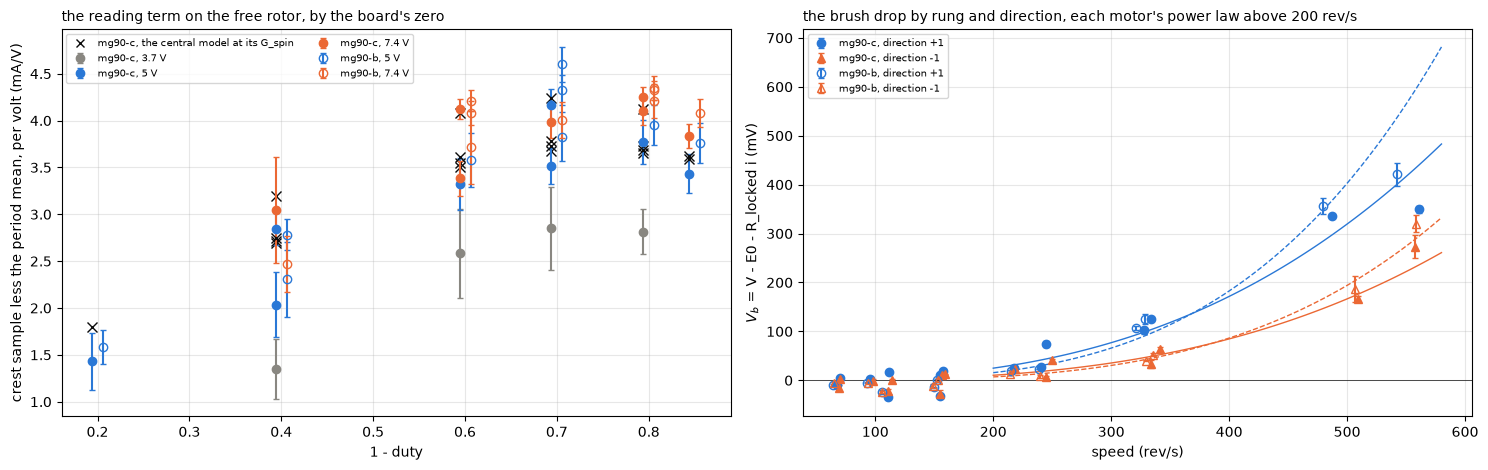

In [35]:
# the two motors side by side: every number of mg90-c from the two cells above, mg90-b's from this notebook's cells
pt_b = lambda n: PT[(PT["set"] == "motor") & (PT["param"] == n)].iloc[0]
rng = lambda v, lo, hi, f="{:.3g}": f"{f.format(v)} ({f.format(lo)} to {f.format(hi)})"
nm_c, nm_b = GRID_C[GRID_C["loop"] == "no meter"], GRID[GRID["loop"] == "no meter"]
per_v = lambda t: f"{(t[t['duty'] <= 30]['RGb'] / t[t['duty'] <= 30]['rail']).min():.2f} to {(t[t['duty'] <= 30]['RGb'] / t[t['duty'] <= 30]['rail']).max():.2f}"
cell74 = lambda t: rng(*t[(t["rail"] == 7.4) & (t["duty"] == 30)].iloc[0][["RGb", "lo", "hi"]], "{:.1f}")
dzs = lambda d: ", ".join(f"{lv:g} V {d[lv]['med']:.1f}" for lv in sorted(d))
rs_slow = lambda jm, names: ", ".join(f"{names.get(k, k)} {v:.3f}" for (n, k), v in zip(jm["names"], jm["x"]) if n == "rs_slow")
CAPS = {"cap-11": "capture-1", "motor": "fast-1", "rev-11": "reversal-1"}
ROWS = [
    ("locked, Rayleigh + G + rung, rule 2: joint chi2/dof, largest held-out", f"{JM_C['chi2']:.2f}, {held_c:.2f}", f"{JM['chi2']:.2f}, {MMB['window_model_chi2']['motor']['hi']:.2f}"),
    ("  without the rung (Rayleigh + G, rule 2), joint chi2/dof", f"{JOINT_C[('RG', 2)]['chi2']:.1f}", f"{JOINT[('motor', 'RG', 2)]['chi2']:.1f}"),
    ("  L0, mH (range)", rng(*PT_C["l0"]), rng(*pt_b("l0")[["value", "lo", "hi"]])),
    ("  Rayleigh term, 1/A (range)", rng(*PT_C["cr"]), rng(*pt_b("cr")[["value", "lo", "hi"]])),
    ("  sign term a1, 1/A (range)", rng(*PT_C["a1"]), rng(*pt_b("a1")[["value", "lo", "hi"]])),
    ("  G, joint fit, mS (range)", rng(*PT_C["g"]), rng(*pt_b("g")[["value", "lo", "hi"]])),
    ("  G, fast-decay fit, mS (over the forms with a G)", f"{G_FORMS_C['RGb']:.2f} ({min(G_FORMS_C.values()):.2f} to {max(G_FORMS_C.values()):.2f})",
     f"{G_FORMS['RGb']:.2f} ({min(G_FORMS.values()):.2f} to {max(G_FORMS.values()):.2f})"),
    ("  rung Lb mH, Rb ohm, time constant us", f"{PT_C['lb'][0]:.3f}, {PT_C['rb'][0]:.2f}, {PT_C['tau_us'][0]:.0f}",
     f"{pt_b('lb')['value']:.3f}, {pt_b('rb')['value']:.2f}, {pt_b('tau_us')['value']:.0f}"),
    ("  slow-decay R per capture, ohm", rs_slow(JM_C, CAPS), rs_slow(JM, CAPS)),
    ("  window offset, line read at 25 / 40 %: data, its loss share, mA", f"{OF_C.loc[('RGb', 25), 'data_line']:.1f} / {OF_C.loc[('RGb', 40), 'data_line']:.1f}, {OF_C.loc[('RGb', 25), 'loss_line']:.1f}",
     f"{OF.loc[('RGb', 25), 'data_line']:.1f} / {OF.loc[('RGb', 40), 'data_line']:.1f}, {OF.loc[('RGb', 25), 'loss_line']:.1f}"),
    ("  inductance's ripple over fit at 25 / 40 %: data, model", f"{MED_C.loc[('data', 25), 'ratio']:.3f} / {MED_C.loc[('data', 40), 'ratio']:.3f}, {MED_C.loc[('RGb rule 2', 25), 'ratio']:.3f} / {MED_C.loc[('RGb rule 2', 40), 'ratio']:.3f}",
     f"{MED.loc[('data', 25), 'ratio']:.3f} / {MED.loc[('data', 40), 'ratio']:.3f}, {MED.loc[('RGb rule 2', 25), 'ratio']:.3f} / {MED.loc[('RGb rule 2', 40), 'ratio']:.3f}"),
    ("  its slide, 3 pairs to all, at 25 / 40 %: data, model, %", f"{MED_C.loc[('data', 25), 'slide_pct']:.1f} / {MED_C.loc[('data', 40), 'slide_pct']:.1f}, {MED_C.loc[('RGb rule 2', 25), 'slide_pct']:.1f} / {MED_C.loc[('RGb rule 2', 40), 'slide_pct']:.1f}",
     f"{MED.loc[('data', 25), 'slide_pct']:.1f} / {MED.loc[('data', 40), 'slide_pct']:.1f}, {MED.loc[('RGb rule 2', 25), 'slide_pct']:.1f} / {MED.loc[('RGb rule 2', 40), 'slide_pct']:.1f}"),
    ("spinning points, of them with the meter", f"{len(PTS_C)}, {int(MET_C.sum())}", f"{len(PTS)}, {int(MET.sum())}"),
    ("  coast scale, the meter runs' mean over the pinned drag (sd)", f"{C_SCALE_C:.3f} ({C_SD_C:.3f})", f"{C_SCALE:.3f} ({C_SD:.3f})"),
    ("  G_spin, central form, mS: chi2/dof, rms mA", f"{G_SPIN_C * 1e3:.2f}: {GS_C[('RGb', 2)][2]:.1f}, {RMS_C[('RGb', 2)]:.2f}", f"{G_SPIN * 1e3:.2f}: {GS[('RGb', 2)]['res']['all'][2]:.1f}, {RMS[('RGb', 2)]:.2f}"),
    ("  G_spin over the forms, mS", f"{min(g[0] for g in GS_C.values()) * 1e3:.2f} to {max(g[0] for g in GS_C.values()) * 1e3:.2f}",
     f"{min(g['res']['all'][0] for g in GS.values()) * 1e3:.2f} to {max(g['res']['all'][0] for g in GS.values()) * 1e3:.2f}"),
    ("  G_spin per rail, board's zero, mS", ", ".join(f"{lv:g} V {g * 1e3:.2f}" for lv, g in G_RAIL_C.items()),
     ", ".join(f"{lv} {GS[('RGb', 2)]['res'][lv][0] * 1e3:.2f}" for lv in ("5 V", "7.4 V"))),
    ("  G_spin by the open zero / the dropout rows' zero, mS (chi2/dof)", f"{GZ_C['all'][0] * 1e3:.2f} ({GZ_C['all'][2]:.1f}) / {G_DZ_C[0] * 1e3:.2f} ({G_DZ_C[2]:.1f})",
     f"{GZ[('open zero', 'all')][0] * 1e3:.2f} ({GZ[('open zero', 'all')][2]:.1f}) / {G_DZ[('med', 'all')][0] * 1e3:.2f} ({G_DZ[('med', 'all')][2]:.1f})"),
    ("  G_spin per rail, the dropout rows' zero, mS", ", ".join(f"{lv:g} V {g * 1e3:.2f}" for lv, g in G_DZ_RAIL_C.items()),
     ", ".join(f"{lv} {G_DZ[('med', lv)][0] * 1e3:.2f}" for lv in ("5 V", "7.4 V"))),
    ("  the dropout rows' zero by rail, counts over torque-off", dzs(DRZ_C), dzs(DRZ)),
    ("  no-meter term per volt at 10 to 30 %, mA/V", per_v(nm_c), per_v(nm_b)),
    ("  no-meter term at 7.4 V 30 %, mA (band)", cell74(nm_c), cell74(nm_b)),
    ("  100 %, the board less the meter, mA (sd)", f"{D100_C.mean():+.2f} ({D100_C.std():.2f})", f"{D100.mean():+.2f} ({D100.std():.2f})"),
    ("  the meter's R, paired / with V_b in the pairing, ohm", f"{R_M_C:.2f} / {R_M_VB_C:.2f}", f"{R_M:.2f} / {R_M_VB:.2f}"),
    ("coast drag a + b sqrt w at 100 / 300 / 500 rev/s, mA", " / ".join(f"{drag_c(2 * np.pi * x):.1f}" for x in (100, 300, 500)), " / ".join(f"{drag(2 * np.pi * x):.1f}" for x in (100, 300, 500))),
    ("100 % run-ups: rev/s, drive, coast drag, mA", f"{st_c['spin_rev_s'].mean():.0f}, {st_c['i_board_ma'].mean():.1f}, {st_c['drag_win_ma'].mean():.1f}",
     f"{st['spin_rev_s'].mean():.0f}, {st['i_board_ma'].mean():.1f}, {st['drag_win_ma'].mean():.1f}"),
    ("  the drive less the coast drag, mA (sd)", f"{(st_c['i_board_ma'] - st_c['drag_win_ma']).mean():+.1f} ({(st_c['i_board_ma'] - st_c['drag_win_ma']).std():.1f})",
     f"{(st['i_board_ma'] - st['drag_win_ma']).mean():+.1f} ({(st['i_board_ma'] - st['drag_win_ma']).std():.1f})"),
    ("  coast drag extrapolated there by four forms / term-out curve, mA", f"{min(AT_ST_C.values()):.1f} to {max(AT_ST_C.values()):.1f} / {mc.nlc_curve(st_c['spin_rev_s'].mean()):.1f}",
     f"{min(AT_ST.values()):.1f} to {max(AT_ST.values()):.1f} / {mm.nlc_curve(st['spin_rev_s'].mean()):.1f}"),
    ("V_b at 300 rev/s, mV, both / +1 / -1", " / ".join(f"{FITS_C[k]['mv_300']:.0f}" for k in ("both", "+1", "-1")), " / ".join(f"{FITS[k]['mv_300']:.0f}" for k in ("both", "+1", "-1"))),
    ("  its exponent, both directions (se)", f"{FITS_C['both']['exponent']:.2f} ({FITS_C['both']['exponent_se']:.2f})", f"{FITS['both']['exponent']:.2f} ({FITS['both']['exponent_se']:.2f})"),
    ("running R under 160 rev/s, route a / b, ohm (locked R)", f"{LOWR_C['a']['pooled']:.3f} / {LOWR_C['b']['pooled']:.3f} ({R_MOT_C:.3f})", f"{LOWR['a']['pooled']:.3f} / {LOWR['b']['pooled']:.3f} ({R_MOT:.3f})"),
    ("100 % chord (V - E0) / i, ohm; dropouts per s", f"{STF_C['R'].mean():.2f}; {STF_C['dropouts_per_s'].mean():.0f}", f"{STF['R'].mean():.2f}; {STF['dropouts_per_s'].mean():.0f}"),
]
print(f"{'':70s} {'mg90-c':36s} mg90-b")
for lab, c_, b_ in ROWS:
    print(f"{lab:70s} {c_:36s} {b_}")

# the reading term per volt against 1 - D on both motors, measured, and mg90-c's central model at its G_spin, and
# the brush drop against speed by direction with each motor's power law
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for P_, a_b, g_, mfc, lab in ((PTS_C, AB_C[("RGb", 2)], G_SPIN_C, None, "mg90-c"), (PTS, (GS[("RGb", 2)]["a"], GS[("RGb", 2)]["b"]), G_SPIN, "none", "mg90-b")):
    for lv, c in ((3.7, MUTED), (5.0, BLUE), (7.4, ORANGE)):
        s = (P_["level"] == lv).to_numpy()
        if s.any():
            x = 1 - P_["duty"].to_numpy()[s] / 100 + (0.006 if lab == "mg90-b" else -0.006)
            ax[0].errorbar(x, P_["gap"].to_numpy()[s] / P_["v_on"].to_numpy()[s], yerr=P_["sig"].to_numpy()[s] / P_["v_on"].to_numpy()[s],
                           fmt="o", ms=6, capsize=2, color=c, mfc=mfc or c, label=f"{lab}, {lv:g} V")
            if lab == "mg90-c":
                ax[0].plot(x, (a_b[0][s] + a_b[1][s] * g_) / P_["v_on"].to_numpy()[s], "x", ms=7, color=INK)
ax[0].plot([], [], "x", color=INK, label="mg90-c, the central model at its G_spin")
ax[0].set_xlabel("1 - duty"); ax[0].set_ylabel("crest sample less the period mean, per volt (mA/V)"); ax[0].grid(alpha=0.3); ax[0].legend(fontsize=7, ncol=2)
ax[0].set_title("the reading term on the free rotor, by the board's zero", loc="left", fontsize=10)
ww = np.linspace(200, 580, 100)
for X_, F_, mfc, ls, lab in ((XR_C, FITS_C, None, "-", "mg90-c"), (XR, FITS, "none", "--", "mg90-b")):
    for d, c, mk in ((1, BLUE, "o"), (-1, ORANGE, "^")):
        h = X_[X_["dir"] == d]
        ax[1].errorbar(h["rev_s"], h["x_b"], yerr=h["x_se"], fmt=mk, ms=6, capsize=2, color=c, mfc=mfc or c, label=f"{lab}, direction {d:+d}")
        ax[1].plot(ww, bc.v_b(ww, F_[f"{d:+d}"]["mv_300"], F_[f"{d:+d}"]["exponent"]), ls, color=c, lw=1)
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_xlabel("speed (rev/s)"); ax[1].set_ylabel("$V_b$ = V - E0 - R_locked i (mV)"); ax[1].grid(alpha=0.3)
ax[1].legend(fontsize=7); ax[1].set_title("the brush drop by rung and direction, each motor's power law above 200 rev/s", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

In [36]:
# mg90-c's results file: mg90-b's keys wherever mg90-c's datasets give them, each defined as in mg90-b's notes
ptq_c = lambda n, unit: q(*PT_C[n], unit)
EDGE_C = OF_C.groupby(level="key")["edge_ma"].mean()
PASS_C = ["RGb", "RG", "RSG", "RS", "RSb"]


def share_q_c(pct, col):
    # the central form's Shapley share, the bounds the other passing forms', as share_q above
    spread = [OF_C.loc[(k, pct), col] for k in PASS_C if col in OF_C.columns and np.isfinite(OF_C.loc[(k, pct), col]) and OF_C.loc[(k, pct), col] != 0]
    return q(OF_C.loc[("RGb", pct), col], min(spread), max(spread), "mA")


G_FORMS_SPIN_C = {km: GS_C[km][0] * 1e3 for km in (("RGb", 2), ("RG", 2), ("RSG", 2), ("LG", 1))}
OMITTED = ("floor_edge_ma (the control's floor, a board read in the teardown sitting), bare_* and can_* (the coil runs) and "
           "delta_l_term_mh and delta_g_term_ms (the coil states), since mg90-c was not opened; running_r_incremental_ohm, since "
           "it runs speed-torque's estimator cells, which this section does not run on mg90-c")
NOTES_C = ("mg90-c, the second motor, through this notebook's cells as motor_model.py and brush_drop.py executed a second time "
           "by second_motor.py with every motor constant from mg90-c's own result files of rest-resistance, bemf-coast, "
           "speed-torque, no-load-current and inductance, each re-derived from mg90-c's captures; every key defined as in "
           "results/mg90-b.json's notes. No teardown number enters, since the coil runs, the delta and the brush photo are "
           "not run here. The locked motor is inductance's fast-1 at hole 11 (four fast groups, two slow) and capture-1 at "
           "hole 11 (slow), the bar seat rest-resistance's stall pass used, state C; mg90-c had no reversal run, so the slow "
           "decay is fast-1's slow groups and capture-1's, and motor_r_slow_ohm_by_capture carries capture-1 and fast-1 "
           "only. The motor_* ranges are the same union as mg90-b's, with the R variant that mg90-b took from the meter's "
           "ohms at rest taken from rest-resistance's r_stall_graded_lines_ohm (the ohms route was not run on mg90-c). "
           "The spinning points are bemf-coast's capture-1 rungs (state A, the ladder at 3.7, 5.0 and 7.4 V; the three "
           "cycles at 3.7 V 15 % that bemf-coast's mg90-c result leaves out are left out here too) and its meter-1 and "
           "high-1 points (state C, the DMM in series), with no spinning-1 points since mg90-c had no spinning run; "
           "g_spin_open_zero_ms takes capture-1's open zero per rung, meter-1's per point and high-1's 5 V level's, and "
           "its bounds are that value and the meter points alone. coast_over_meter carries capture-1's coast drag (state A) "
           "to the meter runs' ratio (state C). The grid's drag is capture-1's coast drag as a + b sqrt w, its "
           "rails 3.7, 5.0, 7.4 and 8.4 V as mg90-b's. drive_zero_counts_by_rail reads the dropout rows of capture-1, "
           "high-1 and speed-torque/capture-1 and has a 3.7 V row from three spins. The 100 % keys are speed-torque's "
           "capture-1, state A, and high-1's 100 % spins, state C. Left out against mg90-b's file: " + OMITTED)
written_c = results.write("2-motor", "motor-model", mc.IND / "fast-1", pair=mc.MOTOR.key, notes=NOTES_C,
    motor_l0_mh=ptq_c("l0", "mH"), motor_rayleigh_per_a=ptq_c("cr", "1/A"), motor_g_locked_ms=ptq_c("g", "mS"),
    motor_g_locked_fast_ms=q(G_FORMS_C["RGb"], min(G_FORMS_C.values()), max(G_FORMS_C.values()), "mS"),
    motor_rung_l_mh=ptq_c("lb", "mH"), motor_rung_r_ohm=ptq_c("rb", "ohm"),
    motor_r_slow_ohm_by_capture={CAPS[k]: pm(v, e, "ohm") for (n, k), v, e in zip(JM_C["names"], JM_C["x"], JM_C["sd"]) if n == "rs_slow"},
    window_model_chi2={"motor": q(JM_C["chi2"], None, held_c, "chi2/dof")},
    offset_shares_line_ma={str(p): {k: share_q_c(p, c) for k, c in SHARE_KEYS.items()} for p in (25, 40)},
    edge_current_ma=q(EDGE_C["RGb"], EDGE_C[PASS_C].min(), EDGE_C[PASS_C].max(), "mA"),
    ripple_over_fit_model={str(p): {"model": q(MED_C.loc[("RGb rule 2", p), "ratio"], unit="ratio"), "data": q(MED_C.loc[("data", p), "ratio"], unit="ratio")} for p in (25, 40)},
    l_slide_model_pct={str(p): {"model": q(MED_C.loc[("RGb rule 2", p), "slide_pct"], unit="%"), "data": q(MED_C.loc[("data", p), "slide_pct"], unit="%")} for p in (25, 40)},
    g_spin_ms=q(G_SPIN_C * 1e3, min(G_FORMS_SPIN_C.values()) - max(G_SPIN_C - min(G_SCALE_C.values()), 0.0) * 1e3,
                max(G_FORMS_SPIN_C.values()) + max(max(G_SCALE_C.values()) - G_SPIN_C, 0.0) * 1e3, "mS"),
    g_spin_open_zero_ms=q(GZ_C["all"][0] * 1e3, min(GZ_C["all"][0], GZ_C["meter"][0]) * 1e3, max(GZ_C["all"][0], GZ_C["meter"][0]) * 1e3, "mS"),
    drive_zero_counts_by_rail={f"{lv:g} V": q(r["med"], r["p10"], r["p90"], "counts") for lv, r in DRZ_C.items()},
    reading_term_rms_ma=q(RMS_C[("RGb", 2)], min(RMS_C.values()), max(RMS_C.values()), "mA"),
    crest_less_mean_ma=grid_q_c("no meter"), crest_less_meter_ma=grid_q_c("meter"),
    meter_loop_ohm=q(R_M_VB_C, R_M_VB_C - R_M_VB_SD_C, R_M_VB_C + R_M_VB_SD_C, "ohm"),
    brush_drop_mv={f"{d:+d}": {r.src: q(r.x_b, r.x_b - r.x_se, r.x_b + r.x_se, f"mV at {r.rev_s:.0f} rev/s") for r in XR_C[XR_C["dir"] == d].itertuples()} for d in (1, -1)},
    brush_drop_fit={("both directions" if k == "both" else k): {
        "mv_at_300_rev_s": q(f["mv_300"], f["mv_300"] * np.exp(-f["a_se"]), f["mv_300"] * np.exp(f["a_se"]), "mV"),
        "exponent": q(f["exponent"], f["exponent"] - f["exponent_se"], f["exponent"] + f["exponent_se"], "")} for k, f in FITS_C.items()},
    running_r_low_speed_ohm={f"route {r}": q(p["pooled"], p["pooled"] - p["total"], p["pooled"] + p["total"], "ohm") for r, p in LOWR_C.items()},
    full_duty_chord_ohm=pm(STF_C["R"].mean(), STF_C["R"].std() / np.sqrt(len(STF_C)), "ohm"),
    coast_over_meter=q(C_SCALE_C, C_SCALE_C - C_SD_C, C_SCALE_C + C_SD_C, "ratio"),
    full_duty_term_ma=q(0.0, D100_C.mean() - D100_C.std(), D100_C.mean() + D100_C.std(), "mA"),
    drag_100_drive_ma=q(st_c["i_board_ma"].mean(), st_c["i_board_ma"].mean() - st_c["i_board_ma"].std(), st_c["i_board_ma"].mean() + st_c["i_board_ma"].std(), "mA"),
    drag_100_coast_ma=pm(st_c["drag_win_ma"].mean(), st_c["drag_win_ma"].std() / np.sqrt(len(st_c)), "mA"),
    drag_100_curve_forms_ma=q(AT_ST_C["a + b sqrt w"], min(AT_ST_C.values()), max(AT_ST_C.values()), "mA"))
print("wrote", written_c, "| left out:", OMITTED)

wrote stages/2-motor/motor-model/results/mg90-c.json | left out: floor_edge_ma (the control's floor, a board read in the teardown sitting), bare_* and can_* (the coil runs) and delta_l_term_mh and delta_g_term_ms (the coil states), since mg90-c was not opened; running_r_incremental_ohm, since it runs speed-torque's estimator cells, which this section does not run on mg90-c


### What the second motor says

The window model built on mg90-b holds on mg90-c within its stated spread. Rayleigh + G + rung under rule 2 fits mg90-c's locked motor at hole 11 at a chi2 per point of 1.94, the same as mg90-b's, its largest held-out duty test reads 3.29 against 3.55, and without the rung the joint fit reads 42 against 40. $L_0$ reads 0.516 against 0.505 mH, the Rayleigh term 2.99 against 2.91 per A, $G$ 2.35 against 2.29 mS in the joint fit and 2.49 mS on both motors in fast decay, and the rung 0.264 mH with 6.95 ohm and 38 us against 0.240 mH, 6.08 ohm and 39 us. The window offset's line read is 18.2 and 23.6 mA at 25 and 40 % against 17.9 and 23.1 mA, about 12 mA of it the loss on both motors. Through inductance's estimators the model gives a ripple over fit of 0.787 and 0.757 against the data's 0.769 and 0.724, 1.3 and 5.6 burst sd off where mg90-b's sat 0.8 and 2.2 sd off, and a slide of 6.4 and 5.4 % against the data's 8.4 and 6.1 %. So the rung reproduces the gap between the window's $L$ and the period fit's on the second motor too, high confidence on the size, and at 40 % it lands further off than on mg90-b.

The spinning motor's loss is the locked loss once the current's zero is the one a driven bridge sits on. mg90-c's ladder adds a third rail, 3.7 V, and there the open bridge's zero sits 2.4 counts over the torque-off zero against the board's 5.3, so the two zeros part the other way from 7.4 V. By the board's zero one $G$ draws mg90-c's 19 points at 3.03 mS with a chi2 per point of 3.5 and an rms of 2.2 mA, the 3.7 V rungs 3 to 5 mA under the model, and per rail it reads 1.62, 2.77 and 3.26 mS. By the open bridge's zero it reads 2.54 mS at 1.7 per point, and by the dropout rows' zero 2.43 mS at 1.9 per point, 2.64, 2.55 and 2.36 mS per rail, against the locked fast-decay fit's 2.49 mS. mg90-b by the same two zeros read 2.69 and 2.79 mS at 3.1 and 2.4 per point. The dropout rows read 2.5, 6.0 and 10.2 counts at the three rails against the open zero's 2.4, 5.7 and 9.7. So on mg90-c the driven zero follows the rail as on mg90-b, now over three rails, and by that zero the spinning loss is the locked loss within 3 %, high confidence. The no-meter term per volt is 3.4 to 3.8 mA/V at 10 to 30 % against 3.7 to 4.0, falling with $1 - D$ to zero at 100 %, where high-1 reads the board 0.11 mA over the meter against 0.13 under. The grid is published by the board's zero as mg90-b's is, so its 3.7 V cells carry that zero's miss.

The coast reads as a meter on both motors. The meter runs' mean is 0.990 of the coast's pinned drag with an sd of 0.018 against 0.984 and 0.030, through speed-torque's $J$ of 6.14 against 6.26 x $10^{-9}$ kg m$^2$ and bemf-coast's $K_e$, though mg90-c's meter runs are in state C and its coasts in state A. mg90-c's coast drag reads 6, 4 and 3 mA under mg90-b's at 100, 300 and 500 rev/s. At 100 % the drive reads 20 mA over no-load-current's term-out curve on both motors, 105.6 against 85.3 mA and 109.9 against 89.8 mA, so that excess goes with the method and not with one motor. The coast's drag at the cut reads 109.6 mA on both, which on mg90-c sits 3.9 mA over its drive, sd 2.5 over six run-ups, where on mg90-b the two agreed.

The brush drop is there with the same shape and the same direction order. Above 200 rev/s it reads 52 mV at 300 rev/s against 45, and 77 and 35 mV by direction against 66 and 30, the same ratio of about 2.2, with an exponent of 2.88 $\pm$ 0.51 against 3.55 $\pm$ 0.42. At 100 % it reads 349 and 273 mV by direction against 421 and 320, with about 410 dropouts a second against about 710, so the 100 % chord is 7.37 against 7.88 ohm. Below 160 rev/s the running R is 4.31 and 4.45 ohm by routes a and b against the locked 4.40, -2.0 and +1.0 %, inside the method's 3 to 4 %, and the 7.4 V rungs again read 22 to 35 mV under zero there by route b, against 11 to 24 on mg90-b, the construction's rail term. The meter's R with $V_b$ in the pairing reads 9.37 against 9.50 ohm.

Three things differ. The sign term of $L(i)$ reads -0.149 per A against +0.073, opposite in sign and twice the size, and which of the leads' orientation, the seat's rotor angle and the motor sets that sign is not separated here. mg90-c's two captures at the seat refit their slow-decay $R$ to 4.380 and 4.372 ohm, where mg90-b's three spread from 4.196 to 4.445. And Rayleigh + step + G + rung, which on mg90-b kept its loss in $G$, puts most of it in the step on mg90-c, 0.47 mS of $G$ jointly and -0.02 mS with 40 % alone, so mg90-c's joint $G$ range reaches zero through that one form. The brush drop at full speed is smaller, with half the dropouts, as speed-torque found for this motor as delivered. Every constant came from mg90-c's own files and captures, and `results/mg90-c.json` carries mg90-b's keys except the coil runs', the delta's, the control's floor and the incremental R at fixed speed.

## Limitations

- One seat per motor. Every motor number belongs to mg90-b at hole 11, and the second-motor section's to mg90-c at its hole 11, one of the three holes that read low in $L$ in inductance. The coil runs are one coil each at one angle in the can, at two sittings that differ by two times in $L$.
- The motor ran at one rail locked, so the form of its edge term rests on fast decay's curvature and slow decay, not on a rail test. The spinning term follows the volts, but there $G$ also carries the $L$ model's error.
- The parameter ranges are a union over fits that share the data, not a confidence interval. They show how far the choices move a parameter.
- The simulator carries no terminal capacitance, so nothing inside the ON edge's first 60 ticks, or 150 on the motor's fast decay, is modeled. The ring's charge there is the teardown's.
- The current's zero at partial duty. The grid, $G_\mathrm{spin}$ and the terms by rail are published by the board's zero, the torque-off zero plus current-scale's in-drive offset, and the locked folds read over each burst's own pre-step zero. The dropout rows put a driven bridge on the open bridge's zero, 3.3 mA over the board's at 7.4 V and 0.65 mA at 5 V, which takes $G_\mathrm{spin}$ to 2.79 mS and its meter points to 2.62 mS, and nothing in the grid has been moved to it yet. At 5 V the meter at 100 % sides with the board's zero by about 0.7 mA.
- `steady()` matches the series current's mean over its last 16.5 periods and not over whole periods, so the modeled term reads 0.20 to 1.14 mA high across the grid. $G_\mathrm{spin}$ absorbs it at the spinning points, and the cells away from them keep up to about 0.5 mA of it.
- The simulator runs slow decay's edges at the mean of the 3.7 and 7.4 V lags at every rail, which reads the 7.4 V term 0.24 to 0.33 mA high.
- The no-meter truth on the spinning motor is the coast's drag scaled by the meter runs' own ratio, 0.984 with an sd of 0.031, read on other spins a day apart, and the drag moved between those sittings.
- The prediction grid uses capture-1's coast drag as $a + b\sqrt{\omega}$, extrapolated above 510 rev/s, which moves only the mean current there.
- The rung is one rung. A ladder is not testable at this resolution.
- The memory rule is chosen per set by slow decay, and the sets disagree. Slow decay is scored with each capture's $R$ refitted on the folds it is scored on, so it tests the slow window's shape and is not a prediction from fast decay; with $R$ held the motor's model reads 50 per point under rule 2.
- The rail test's lines run through three points each, one degree of freedom, so their slopes and intercepts carry little weight on their own.
- The brush drop belongs to mg90-b in the sittings it was read in. Bemf-coast's direction splits shrank between its sittings, so its size is not a constant of the motor type.
- The test that separates speed from current runs only at 100 %, through transients, from 180 to 540 rev/s. Whether $V_b$ stays set by the speed under a steady load is not tested.
- $V_b$ is read against the locked R, so a part that follows the current, up to about 0.3 ohm, would sit inside it.
- The construction's edge term $\delta$ is taken as zero with a $\pm$5 mV band. The fold that measured it ran with the meter in the loop and did not carry over to capture-1, and the band does not cover the 10 to 25 mV rail term at 7.4 V below 160 rev/s.
- The brush drop's power law is an unweighted line in logs, so its exponent's $\pm$0.42 leaves out the low rungs' systematics.
- Routes a and b share $G_\mathrm{spin}$'s fit, so they are not independent at the rung level, and the fixed-speed incremental R rests on speed-torque's estimator cells as they stand.
- The crest term with the meter in the loop and the spinning $G$ were run at the pairing's meter R of 8.87 ohm, not at `meter_loop_ohm`.

## Open questions

- What the bare rotor's edge current of about 2.6 mA is. It does not rise with the rail in any clear way, a slope of 0.08 $\pm$ 0.15 mS on three rails that are not monotonic, and the other bare sitting, coil-noring-1, fits L||G with no Rayleigh rise. A hysteresis onset predicts the same milliamps at every rail and duty and a step at each slow-decay reversal. A conductance with an $L(i)$ form error predicts milliamps in proportion to the volts. A coil-to-coil difference predicts the two bare sittings to disagree, as they do. The levels runs at 10 and 15 % beside 25 and 40 % would set the first against the second, and the levels groups on the other two coils would test the third.
- Where the can's conductance and its small rung live. $G$ of 1.1 to 1.7 mS is mostly a conductance by the rail test, and under rule 2 a small fast rung of 0.045 mH with a time constant of about 60 us appears. Eddy currents in the can or the magnets, and a closed turn through the cut coils' dangling ends touching the can, predict the same shape in the band. The cut coils' ends read for continuity to the can, and ohms across one magnet's faces, separate them.
- Where the motor's rung lives, the can, the magnets, the laminations or the delta. The delta of these coils does not make it. Magnetic relaxation after each switch to a near-zero voltage gives the same exponential form in a circuit [5, 6], but the bare coil needs no rung, which argues against it in the rotor iron. The same bursts at a second PWM frequency read a rung's $R_b$ and $L_b$ apart, since the window's time scale moves against its time constant.
- Whether the spinning motor's extra loss is there at all. By the dropout rows' zero, the zero a driven bridge sits on, $G_\mathrm{spin}$'s meter points read the locked value and all 18 points 12 % over it. What stays open is the 5 V tension, the meter at 100 % siding with the board's zero by about 0.7 mA, and a DMM in series at 7.4 V that confirms the dropout rows' zero independently. If a gap holds, the locked rotor at several holes in fast decay bounds the angle's part, and what is left over at speed is rotation's.
- Which memory rule this iron follows. Slow decay with a reversal of the ripple's size from a known plateau separates rule 1 from rule 2, and none of these captures isolates it.
- Why the motor's series $R$ moves between captures at one seat, 4.445, 4.304 and 4.196 ohm for capture-1, reversal-1 and fast-1 in capture order, at 0.3 to 0.45 A. A contact film wearing in predicts a fall with use, copper warming a rise. The order fits the film, low confidence.
- Why the 60 % reading term sits 1.8 to 2.7 mA under every form but L||G at both rails, with and without the meter. A meter run at 50, 60 and 70 % reads the fall's shape against $1 - D$.
- How much the drag moves between sittings, about 20 mA at 480 rev/s between capture-1's coasts and high-1's meter a day later, with speed-torque's run-ups between them. Coasts at fixed duties at the start and end of each sitting read it.
- Whether $V_b$ stays set by the speed under load at steady state. A load that holds the motor at a fixed speed while the current moves, not an acceleration, reads it. A contact voltage predicts $V_b$ to hold as the current rises, a resistance predicts it to rise with the current.
- $V_b$ by direction, and how it drifts between sittings and over running hours. Low-speed and full-speed coasts at the start and end of each sitting re-read it. A contact film predicts it to move with wear and the commutator's state, while the brushes' fixed geometry predicts the direction split to stay.
- The edge volt-ticks in a servo's own wiring with no meter, by the spinning-burst fold at both rails, since the fold read with the meter did not carry over to capture-1. A wiring effect predicts a different OFF-edge tail without the meter, an effect of the bridge the same tail.
- The crest term against a meter whose R is measured on its own and not paired. That takes the meter's R out of $G_\mathrm{spin}$'s fit and settles whether the meter-loop grid needs a rerun.
- What $V_b$ physically is. A contact voltage predicts it to fall with brush pressure and to follow the fingers' bounce, arcs predict light or erosion that scales with $L\,i^2$, and a finger resonance predicts a sharper rise near the speed where three gaps a revolution meet it. A high-speed camera on the fingers at fixed speeds, or the same coasts with the brush springs loaded harder, separates them.
- The low-speed chord 3 % under the locked R, and the fixed-speed incremental R 0.27 ohm over the low-speed chord, both inside 1.5 sigma. Rotation averaging over angles against one locked seat, the brush contact's state, $\delta$ and the current scale are the candidates, and coasts at several fixed duties in one sitting beside a locked pass at several holes separate the first from the rest.
- The first ripple cycle after the cut reading 0.7 % under $E_0$. Tap settling predicts the same deficit in volts at every speed, a real dip in the EMF predicts one in proportion to it.

## Conclusion

On the motor at hole 11, one model draws every locked dataset of stage 2. It is an inductance of 0.505 mH that rises with the current from its last reversal by 2.9 per A, the Rayleigh law of soft iron, a loss across it of 2.29 mS, and a slow series rung of 0.240 mH with 6.1 ohm, a time constant of 39 us. Fitted to fast and slow decay together it reads a chi2 per point of 1.94 over twelve runs and holds out by duty. Slow decay's shape it draws with each capture's $R$ refitted on the slow folds, a shape test with $R$ free rather than a prediction from fast decay, since fast-1's slow groups refit 7 % under the $R$ its fast groups hold. Linear networks fail every held-out test, the control sets the floor at about 0.3 mA, and on one coil the bare rotor iron carries a Rayleigh rise and an edge current of 2.3 to 2.9 mA that does not clearly follow the rail, while the coil in the can carries a magnet-biased $L(i)$ and a loss of 1.1 to 1.7 mS that most likely follows the volts. High confidence on the model's form reproducing the data, moderate on each parameter, since $L_0$, $G$ and the Rayleigh term trade.

The rung is what inductance's gap between the window's $L$ and the period fit's, and its slide with the fit's length, come from, high confidence that it reproduces both at 25 % and their size at 40 %, where it lands about two burst sd off, and moderate that one rung is the mechanism. About 12 mA of the motor's window offset at 4.95 V is a loss at the edge, the same at both duties, and the rest is the ramp's shape. The +20 mA at 100 % is not a window current, high confidence, since at 100 % the crest reads the meter; it is a drag of the run-up's first few hundred milliseconds and not of the settled 100 % drive, which bemf-coast's high-1 spins read 5 mA under the curve after 3 s, moderate confidence, and no-load-current's curve reads low there by its form, its meter-run term and the drag's drift between sittings.

On the spinning motor the crest sample reads a loss in the window that a meter averages away, falling with $1 - D$ to zero at 100 %, high confidence. Where the loss sits, across the inductance or in the rung, is moderate at most, since a rung-only form fits the same points. By the board's current zero the spinning motor needs 34 % more $G$ than the locked fast-decay fit of the same $L$ model, 2.4 sigma once the coast scale and the locked $G$'s range are carried. By the zero a driven bridge sits on, which the dropout rows read as the open bridge's, high confidence at 7.4 V and moderate at 5 V, its meter points need none and all 18 points 12 % more, so the gap is mostly the zero, and a DMM in series at 7.4 V confirms it. With no meter in the loop the crest sample reads over the period mean by about 3.7 to 4.0 mA per volt of the rail at 10 to 30 % by the board's zero, 19 mA at 5.0 V and 29 mA at 7.4 V, and about 25 to 26.5 mA at 7.4 V by the dropout zero, falling close to linearly to zero at 100 %, with a band of 0.5 to 6.6 mA from the $L$ forms. Later stages take the prediction, the parameters and the meter's share from `results/mg90-b.json`, and the term a design subtracts from its crest sample is that grid, not a constant. The grid there is published by the board's zero, with the dropout zero beside it.

On the turning motor the terminal volts carry, beyond $R\,i$ and $K_e\,\omega$, the brush drop $V_b(\omega)$, a voltage set by the speed and the direction and not by the current. High confidence that it is in the motor, since the 100 % run-ups read it with nothing switching and nothing modeled, and moderate confidence that it does not scale with the current, since the run-ups pass the same speeds at up to eleven times the free current and keep it, which rejects an excess in proportion to the current and leaves a part of up to about 0.3 ohm open, on 100 % transients only. Below 160 rev/s it is within about 10 mV of zero at 5 V and reads 10 to 25 mV under zero at 7.4 V, a rail term of the construction, and the running R is the locked R within the method's 3 to 4 %, moderate confidence. Above 200 rev/s it grows as about 45 mV $\times (\omega/300\ \mathrm{rev/s})^{3.55}$, close to the geometric mean of 66 mV at 300 rev/s in direction +1 and 30 mV in -1, its exponent's error understated by an unweighted fit, to 371 mV at 550 rev/s, where it makes the 100 % chord read 7.88 ohm against the locked 4.455. At fixed speed the incremental R is 4.58 ohm, the locked R plus 2.8 %, so an incremental R read across rungs on a free shaft inflates by $V_b$'s rise and not by a resistance. $V_b$ tracks the current dropouts but is not carried by them. The leading reading is a contact voltage at the three-finger brushes that grows with their bounce, moderate confidence. The motor's equation is $v = R\,i + L\,di/dt + K_e\,\omega + V_b(\omega, \mathrm{dir})$, and later stages take $V_b$ by speed and direction, the running R and the meter's 9.50 ohm from `results/mg90-b.json`.

## References

1. Lord Rayleigh, "On the behaviour of iron and steel under the operation of feeble magnetic forces," *Philosophical Magazine*, vol. 23, pp. 225-245, 1887.
2. G. Bertotti, "General properties of power losses in soft ferromagnetic materials," *IEEE Transactions on Magnetics*, vol. 24, pp. 621-630, 1988.
3. T. Matsuo, A. Kameari, K. Sugahara and Y. Shindo, "Matrix formulation of the Cauer ladder network method for efficient eddy-current analysis," *IEEE Transactions on Magnetics*, vol. 54, no. 11, 2018, doi:10.1109/TMAG.2018.2839768.
4. J. Mühlethaler, J. Biela, J. W. Kolar and A. Ecklebe, "Core losses under the DC bias condition based on Steinmetz parameters," in *Proc. International Power Electronics Conference (IPEC, ECCE Asia)*, 2010, pp. 2430-2437.
5. J. Mühlethaler, J. Biela, J. W. Kolar and A. Ecklebe, "Improved core-loss calculation for magnetic components employed in power electronic systems," *IEEE Transactions on Power Electronics*, vol. 27, no. 2, 2012, doi:10.1109/TPEL.2011.2162252.
6. Z. Yan, W. Xie, C. Ma and L. Huang, "Modeling core losses under exciting waveforms with zero voltage period in power converters," *IEEE Transactions on Industrial Electronics*, vol. 70, no. 2, pp. 1378-1386, 2023.
7. M. V. Kesava Rao, "Brush contact drop in D.C. machines," *Journal of the Indian Institute of Science*, vol. 17B, part 5, pp. 91-100, 1934.
8. Mersen, "Losses in brushes," Technical Data Sheet TDS-05, PTT-TDS05-EN-2007, 2007.